# SK Hynix perp pair: short `xyz:SKHX` / long `xyz:SKHY`

## S0 · Summary

**Research question.** Is it profitable to long SKHY and short SKHX to collect funding? What is the basis risk historically? How much can we make?

| Trade set-up | |
|---|---|
| What is the trade | Short the Seoul line `xyz:SKHX`, long the New York line `xyz:SKHY`, equal USD on each leg, to collect the funding differential |
| Venue | Hyperliquid (xyz) |
| Type of risk | Basis: the listing basis `10 x SKHY / SKHX - 1`, which the book is long, and the perp basis of each leg |
| Rules | Enter both legs at one close, hold through every funding print, exit both at the end of the window. No early exit is simulated |
| Base test | Does it pay above the T-bill at 1x? (S3) |
| Test 1 | Is it real: out of sample, statistically significant, after costs? (S4) |
| Test 2 | What if we exit based on a rule: hold only while the trailing 7-day funding is above the T-bill, or above zero? (S4) |

**Read this before the verdict.** This study, the four-leg study and its discretionary variant read the same two Hyperliquid perps over the same window and one regime: together they are ONE result, not three. The premium basis carries most of the P&L and no gate reads it; Test 3 in S4 tests it.

## S1 · Setup

### S1.1 · Assumptions

| Assumption | Value | From |
|---|---|---|
| **Equity** | USD 1,000,000, one cross USDC account | custom |
| Base book | 1x = USD 500,000 per leg | custom |
| Reserve | 0 | custom |
| Slippage | 2 bp per fill | custom |
| Unwind slippage | 10 bp | custom |
| Liquidation fee | 7.5 bp | custom |
| **Premium stop** | 10 premium points of room | custom |
| Drawdown limit | 15% of equity | custom |
| T-bill hurdle | 4.11% a year | custom choice (US Treasury [V]) |
| Test settings | split 2026-08-20 · 2,000 shuffles · 5-day blocks · 168 h hedge window | custom |
| Taker fee | 0.9 bp per fill | Hyperliquid [V] |
| Maintenance margin | 5% | Hyperliquid [V] |
| Max leverage | 10x | Hyperliquid [V] |
| Funding rate | hourly, as published | Hyperliquid [V] |
| Funding notional | position x oracle price | Hyperliquid [V] |
| Liquidation | equity below maintenance, on the mark | Hyperliquid [V] |
| ADS ratio | 10 SKHY = 1 Korean share | fact [V] |

### S1.2 · Data

| Source | Data | Period |
|---|---|---|
| Hyperliquid | funding (hourly, settled), 1h candles, published premium, for `xyz:SKHX` and `xyz:SKHY` | 2026-07-15 to 2026-10-03 |
| Hyperliquid (live) | margin table and max leverage for dex xyz | NIL |

### S1.3 · Code

In [1]:
EQUITY = 1_000_000.0        # custom: account equity, USD
LEV = 1.0                   # custom: leverage of the base book
RESERVE = 0.0               # custom: extra margin held back, x initial margin
SLIPPAGE_BPS = 2.0          # custom: slippage per fill, bp
UNWIND_SLIPPAGE_BPS = 10.0  # custom: slippage when the second leg is closed after a liquidation, bp
LIQ_FEE_BPS = 7.5           # custom: fee when a leg is liquidated, bp of its notional
STOP_PTS = 10.0             # custom: premium points of room a leverage level must keep
DD_LIMIT_PCT = 15.0         # custom: max drawdown we accept, % of equity

COIN_A, COIN_B, VENUE, DAYS = "xyz:SKHX", "xyz:SKHY", "Hyperliquid", 120   # the pair, the venue, days of history
START_DATE, SPLIT_DATE = "2026-07-15", "2026-08-20"   # custom: entry date, out-of-sample split date
END_DATE, WINDOW_HOURS = "2026-10-03 09:00", 1930    # custom: window end and its hours, pinned so the study reproduces on the same window
LEVS, RESV = (1, 2, 3, 5, 7, 10), (0.0, 0.5, 1.0, 2.0)   # custom: leverage levels, reserve levels
NSHUF, SEED = 2000, 7       # custom: number of shuffles, random seed
BOOT_BLOCK_D = 5            # custom: bootstrap block length, days
HEDGE_WIN_H = 168           # custom: hedge-ratio window, hours
FWD_FROM, FWD_H, FWD30_H = "2026-10-05 00:00", 168, 720   # custom: the registered forward windows (B-0283): both open here, 168 h and 30 d long, fixed so every later read measures the SAME hours
FWD_LEV = 3.0               # custom: the book the forward windows are read on

In [2]:
import datetime as dt, json, time
from dataclasses import replace
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib.patches import Patch
import numpy as np, pandas as pd
from IPython import get_ipython
from IPython.display import HTML, Markdown, display
from fundplat.quant.core import refdata
from fundplat.quant.core import stats as ST
from fundplat.quant.core import report as REPORT
from fundplat.quant.crypto.backtest import hip3_pair as HP
from fundplat.data.crypto import venue_truth as VT
import fundplat.data as DATA
from fundplat.quant.core import figstyle, summary_card
get_ipython().run_line_magic("config", "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")   # the picture is the figure, not a tight crop of it

MMR = 0.05          # the venue's maintenance margin - asserted below against refdata.spec_for + the live meta
HOUR = 3_600_000
ms_ = lambda s: int(dt.datetime.fromisoformat(s).replace(tzinfo=dt.timezone.utc).timestamp() * 1000)
START, SPLIT, END_MS = ms_(START_DATE), ms_(SPLIT_DATE), ms_(END_DATE)

p1 = HP.pair_params_simple(EQUITY, LEV, RESERVE, "cross", "equal_usd", "short_a", regime=False,
                           exec_slippage_bps=SLIPPAGE_BPS, unwind_slippage_bps=UNWIND_SLIPPAGE_BPS,
                           liq_fee_bps=LIQ_FEE_BPS)
assert p1.aum_usd == EQUITY and p1.leverage == LEV and p1.reserve_mult == RESERVE
assert p1.margin_mode == "cross" and p1.direction == "short_a" and p1.size_mode == "equal_usd" and not p1.regime
assert p1.fee_taker_bps == refdata.XYZ_TAKER_BPS == 0.9 and p1.exec_slippage_bps == SLIPPAGE_BPS and not p1.maker
assert p1.wick_mode == "joint_adverse" and p1.liq_fee_bps == LIQ_FEE_BPS and p1.unwind_slippage_bps == UNWIND_SLIPPAGE_BPS
assert p1.hurdle_ann == refdata.HURDLE_ANN and HP.spec_for(VENUE, COIN_A, EQUITY)[0] == MMR

# ---- the venue's own margin spec: max leverage is the SETTING cap, not the desk's split ----
SPEC_A, SPEC_B = refdata.spec_for(VENUE, COIN_A, EQUITY), refdata.spec_for(VENUE, COIN_B, EQUITY)
assert SPEC_A[0] == SPEC_B[0] == MMR
MAXLEV = int(min(SPEC_A[1], SPEC_B[1]))
ENTRY_BPS = p1.fee_taker_bps + p1.exec_slippage_bps
L_MAX_PLACEABLE = MAXLEV / (1.0 + MAXLEV * ENTRY_BPS / 1e4)

# ---- the numbers the opening tables STATE, held to the code. A table that parts from the run goes red here ----
PROSE = {"equity USD 1,000,000": (EQUITY, 1_000_000.0), "1x = USD 500,000 per leg": (EQUITY * LEV / 2, 500_000.0),
         "reserve 0": (RESERVE, 0.0), "taker 0.9 bp, growth tier": (refdata.XYZ_TAKER_BPS, 0.9),
         "slippage 2 bp": (p1.exec_slippage_bps, 2.0), "unwind 10 bp": (p1.unwind_slippage_bps, 10.0),
         "liquidation fee 7.5 bp": (p1.liq_fee_bps, 7.5), "maintenance 5%": (MMR, 0.05), "max leverage 10x": (MAXLEV, 10),
         "hurdle 4.11%": (refdata.HURDLE_ANN, 0.0411), "stop 10 pts": (STOP_PTS, 10.0), "drawdown limit 15%": (DD_LIMIT_PCT, 15.0),
         "split 2026-08-20": (SPLIT, ms_("2026-08-20")), "2,000 sign shuffles": (NSHUF, 2000),
         "block bootstrap, mean block 5 d": (BOOT_BLOCK_D, 5), "hedge-ratio window 168 h": (HEDGE_WIN_H, 168)}
BAD = {k_: v_ for k_, (v_, w_) in PROSE.items() if v_ != w_}
assert not BAD, f"the opening tables no longer describe this run: {BAD}"

# ---- ONE palette (figstyle) and the notebook's chart settings ----
globals().update(figstyle.NAMES)
LEG = dict(frameon=True, facecolor=SURF, edgecolor="none", framealpha=0.9)
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
                     "font.size": 9.5, "axes.axisbelow": True, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
                     "axes.titlecolor": INK, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "xtick.color": MUTED, "ytick.color": MUTED,
                     "legend.frameon": False, "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.8})
ANN, A_PCT = 8760 * 100, 100.0 / EQUITY
num = lambda s: pd.to_numeric(s, errors="coerce")
fmt = lambda ms: dt.datetime.fromtimestamp(ms / 1000, dt.timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
usd = lambda v: f"USD {v:,.0f}"
kusd = lambda v: f"{v:,.0f}"


def usdm(v):
    s = f"{v/1e6:,.2f}"
    return "USD " + (s.rstrip("0").rstrip(".") if "." in s else s) + "M"


# ---- premium-point arithmetic, exact (never 2 x distance): both legs adverse by the same fraction x moves a premium P_pct to (1+P)(1-x)/(1+x) - 1 ----
pts = lambda P_pct, x: (1.0 + P_pct / 100.0) * 2.0 * x / (1.0 + x) * 100.0
liq_lvl = lambda P_pct, x: (1.0 + P_pct / 100.0) * (1.0 - x) / (1.0 + x) * 100.0 - 100.0


def ask(ax, q, sub):
    ax.set_title(q, pad=24)
    ax.text(0.0, 1.012, sub, transform=ax.transAxes, color=MUTED, fontsize=8.5, ha="left", va="bottom")


def fig_ask(fig, q, sub, top):
    fig.suptitle(q, x=0.06, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
    fig.text(0.06, top + (0.985 - top) * 0.42, sub, color=MUTED, fontsize=8.5, ha="left", va="center")


def frame(r_):
    d = pd.DataFrame(r_["series"])
    d["ts"] = pd.to_datetime(d["time"], unit="ms", utc=True)
    d = d.set_index("ts")
    d["gross"] = num(d["notional_A"]).abs() + num(d["notional_B"]).abs()
    return d


def daily(d_):
    cum = pd.DataFrame({"funding": num(d_["cum_funding_net"]), "premium": num(d_["cum_premium_pnl"]),
                        "fees": -(num(d_["cum_fees"]) + num(d_["cum_liq_fees"])), "total": num(d_["total_pnl"]),
                        "premium_pct": num(d_["implied_premium_pct"])})
    eod = cum.resample("1D").last().ffill()
    day = eod.diff()
    day.iloc[0] = eod.iloc[0] - pd.Series({"funding": 0.0, "premium": 0.0, "fees": 0.0, "total": 0.0, "premium_pct": cum["premium_pct"].iloc[0]})
    day["premium_level"] = eod["premium_pct"]
    return day


# ---- the data, then the venue-published asserts: every engine hour IS the venue's own funding rate; the margin spec IS the venue's own ----
rows_all, meta_v = HP.load_pair_rows(COIN_A, COIN_B, days=DAYS, with_meta=True)
t0, t1 = meta_v["window"]
VEN = {leg: {(t // HOUR) * HOUR: r for t, r in VT.hl_funding_history(c, t0 - HOUR, t1 + HOUR).items()} for leg, c in (("A", COIN_A), ("B", COIN_B))}
bad = [(r["time"], leg) for r in rows_all for leg in ("A", "B") if r[f"{leg}_rate"] != VEN[leg].get((r["time"] // HOUR) * HOUR)]
assert not bad, f"{len(bad)} engine hours differ from the venue, first: {bad[0]}"
UNI = VT.hl_universe("xyz")
for c_ in (COIN_A, COIN_B):
    assert int(UNI[c_]["maxLeverage"]) == MAXLEV and int(UNI[c_]["marginTableId"]) == 10, (c_, UNI[c_])
rows = [r for r in rows_all if START <= r["time"] <= END_MS]
assert len(rows) > 500 and rows[0]["time"] >= START > rows[0]["time"] - HOUR
assert len(rows) in (WINDOW_HOURS, WINDOW_HOURS + 1), f"the pinned window holds {WINDOW_HOURS} hours, this run read {len(rows)}"
P_ENTRY = rows[0]["B_perp"] * 10 / rows[0]["A_perp"] * 100 - 100
FIGURES = []                      # every cell that draws lists itself here through figstyle.show; the manifest reads it
STATS = {}                        # what a later cell, the verdict and the summary card read; nothing is typed

In [3]:
res = HP.run_pair(rows, p1)
c_ = HP.verify_pair(res)
assert HP.all_pass(c_), {k: v for k, v in c_.items() if not v[0]}
NCHK = len(c_)
assert NCHK >= 37, NCHK
df = frame(res)
assert abs(res["gross_notional_usd"] - LEV * EQUITY) < 1e-6 and res["reserve_usd"] == 0.0
prem = num(df["implied_premium_pct"])
P0 = prem.iloc[0]
DAY = daily(df)
assert abs(DAY["total"].sum() - res["total_pnl"]) < 1e-6
FS = res["funding_stats"]
D7, DMEAN = FS["net"]["last7d_mean_ann_pct"], FS["net"]["mean_ann_pct"]
HURDLE_PCT = p1.hurdle_ann * 100
# the engine books funding on the RECONSTRUCTED ORACLE notional, which drifts away from the entry notional as the legs move; DRIFT is that ratio, engine / analytic
DRIFT = res["funding_ann_pct_aum"] / (DMEAN * LEV / 2.0)


def book(L, R=0.0):
    """One leverage level's arithmetic in the engine's own conventions: gross = equity x L / (1 + R)."""
    G = EQUITY * L / (1.0 + R)
    N = G / 2.0
    x_liq = (1.0 + R) / L - MMR
    return {"per leg USD": kusd(N), "venue initial margin (gross/10) USD": kusd(G / MAXLEV), "desk collateral (gross/L) USD": kusd(G / L),
            "maintenance (5% x gross) USD": kusd(MMR * G), "room at entry, pts": f"{pts(P0, x_liq):.1f}", "liquidation premium %": f"{liq_lvl(P0, x_liq):+.1f}"}


_BB = {"per leg USD": "Per leg", "venue initial margin (gross/10) USD": "Venue initial margin (gross / 10)", "desk collateral (gross/L) USD": "Desk collateral",
       "maintenance (5% x gross) USD": "Maintenance (5% of gross)", "room at entry, pts": "Room at entry, premium points", "liquidation premium %": "Liquidation premium, %"}
display(Markdown("#### Base book, 1x\n\n| | |\n|---|---|\n" + "\n".join(f"| {_BB[k]} | {v} |" for k, v in book(int(LEV)).items())))

#### Base book, 1x

| | |
|---|---|
| Per leg | 500,000 |
| Venue initial margin (gross / 10) | 100,000 |
| Desk collateral | 1,000,000 |
| Maintenance (5% of gross) | 50,000 |
| Room at entry, premium points | 128.0 |
| Liquidation premium, % | -96.6 |

### S1.4 · Notebook structure

| Section | What it holds |
|---|---|
| S0 Summary | the question and the trade set-up |
| S1 Setup | assumptions, data, code, this page |
| S2 Data checks · History | how the funding and the basis moved |
| S3 Core result · Base test | does it pay at 1x |
| S4 Robustness | test 1 (out of sample, significance, costs) and test 2 (exit rules) |
| S5 Risk and diagnostics | the hedge, the premium basis (the listing basis) and the perp basis |
| S6 Decision | size, fill, limits |
| S7 Verdict | the gates, what would change it |
| A Appendix | the leverage grid |
| Research summary | the card, a separate part at the very bottom |

In [4]:
# ---- the window pin first: the pinned window, the hours and the book, all as the cells above read them ----
assert START == ms_(START_DATE) and rows[0]["time"] >= START > rows[0]["time"] - HOUR
assert rows[-1]["time"] <= END_MS < rows[-1]["time"] + HOUR, (fmt(rows[-1]["time"]), END_DATE)
assert len(rows) in (WINDOW_HOURS, WINDOW_HOURS + 1) and res["n_hours"] == len(rows) and len(DAY) == len(set(DAY.index))
assert abs(DAY["total"].sum() - res["total_pnl"]) < 1e-6 and (START_DATE, END_DATE, WINDOW_HOURS, SPLIT_DATE) == ("2026-07-15", "2026-10-03 09:00", 1930, "2026-08-20")

# ---- the numbers the tests below use, tagged [U] (ours, no venue publishes them) ----
CI_LEVEL = 90                       # custom [U]: the interval every bootstrap quotes, %
BLOCKS_D = (1, 3, 5, 10, 20, 40)    # custom [U]: mean block lengths of the sensitivity row, days (5 is the study's own)
SIZED_X = 3                         # custom: the rung S6 picks; the S7 cell asserts the pick is this

## S2 · Data checks - History

How funding and the basis moved. Hyperliquid's own prices are the cash prices here: the oracle is the cash price each perp tracks.

In [5]:
num_ = lambda s: pd.to_numeric(s, errors="coerce")
fA, fB = num_(df["A_rate"]) * ANN, -num_(df["B_rate"]) * ANN
d_h, d_7 = num_(df["diff_ann_pct"]), num_(df["diff7_ann_pct"])
prem = num_(df["implied_premium_pct"]); P0 = prem.iloc[0]
HURDLE_EQ = p1.hurdle_ann * 100
HURDLE_LEG = HURDLE_EQ * EQUITY / (EQUITY * LEV / 2.0)          # the same bar on the leg-notional axis the differential is quoted on
WS = f"{df.index[0]:%b %d} - {df.index[-1]:%b %d} \u00b7 {len(df):,}h"          # funding and basis history do not depend on the book settings, so the window is all a subtitle needs
STATS.update({"window": WS, "hours": int(len(df)), "hurdle_eq": HURDLE_EQ, "hurdle_leg": HURDLE_LEG})
KEY = "faint lines: dashed mean, dotted median, dash-dot max"

# ---- units check (the owner asked): the published rate is a fraction per HOUR; annualised = x 8,760. Read the biggest print from the venue itself ----
from fundplat.data.crypto import venue_truth as VT
i_mx = fA.idxmax(); t_mx = int(i_mx.timestamp() * 1000)
_v = VT.hl_funding_history(COIN_A, t_mx - HOUR, t_mx + HOUR)
_raw_df = float(num_(df.loc[i_mx, "A_rate"]))
_vv = {(t // HOUR) * HOUR: r for t, r in _v.items()}          # floor to the settlement hour, as the original notebook's assert does
_raw_venue = _vv.get((t_mx // HOUR) * HOUR)
assert _raw_venue is not None and len(_v) >= 1, f"the venue returned no row for {i_mx}: {list(_v)[:3]}"
STATS["unit_check"] = {"coin": COIN_A, "hour": str(i_mx), "engine_rate_per_hour": _raw_df, "venue_rate_per_hour": _raw_venue, "equal": _raw_df == _raw_venue,
                       "pct_per_hour": _raw_df * 100, "annualised_pct": _raw_df * 8760 * 100, "cap_pct_per_hour": 4.0, "times_under_cap": 0.04 / _raw_df,
                       "baseline_floor_pct": 0.0000125 * 8760 * 100}
print(f"units check: {_raw_df * 100:.4f}% for the hour = {_raw_df * 8760 * 100:,.0f}% annualised; equal to the venue: {_raw_df == _raw_venue}")
stat3, tag, yfit, finish, LS = figstyle.stat_lines, figstyle.tag, figstyle.yfit, figstyle.finish, figstyle.LS

UC = STATS["unit_check"]

units check: 0.0972% for the hour = 851% annualised; equal to the venue: True


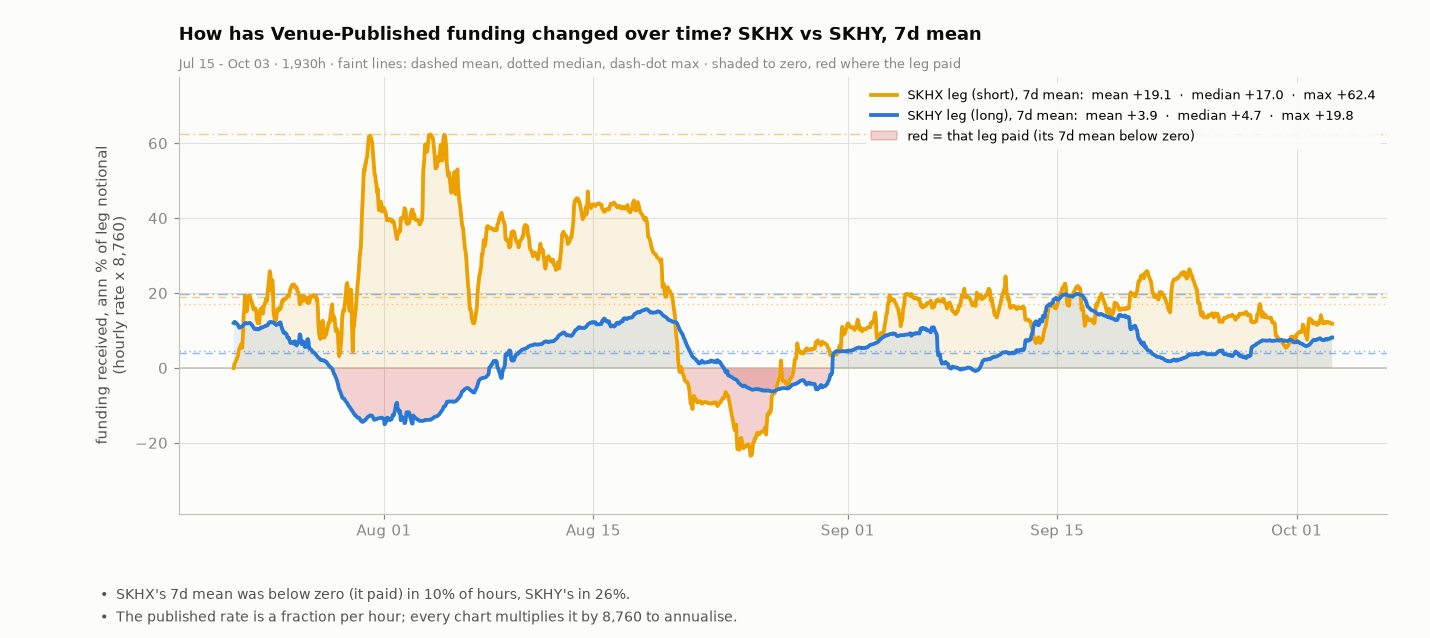

In [6]:
# ---- 1a. SKHX vs SKHY, 7d mean, ONE chart ----
a7, b7 = fA.rolling(168).mean(), fB.rolling(168).mean()
fig, ax = plt.subplots(figsize=(13, 5.8))
ax.plot(a7.index, a7, color=C_A, linewidth=2.5, zorder=4)
ax.plot(b7.index, b7, color=C_B, linewidth=2.5, zorder=4)
va, vb = stat3(ax, a7, C_A), stat3(ax, b7, C_B)
ax.plot([], [], color=C_A, linewidth=2.5, label=tag("SKHX leg (short), 7d mean", va)); ax.plot([], [], color=C_B, linewidth=2.5, label=tag("SKHY leg (long), 7d mean", vb))
ax.axhline(0, color=AXIS, linewidth=1, zorder=1)
for s_, col_ in ((a7.dropna(), C_A), (b7.dropna(), C_B)):          # shade each leg down to zero; red where that leg PAID (its 7d mean is below zero)
    ax.fill_between(s_.index, s_, 0, where=(s_ >= 0), interpolate=True, color=col_, alpha=0.10, linewidth=0, zorder=1)
    ax.fill_between(s_.index, s_, 0, where=(s_ < 0), interpolate=True, color=CRIT, alpha=0.22, linewidth=0, zorder=1)
paid_a, paid_b = float(a7.dropna().lt(0).mean() * 100), float(b7.dropna().lt(0).mean() * 100)
ax.fill_between([], [], color=CRIT, alpha=0.22, label="red = that leg paid (its 7d mean below zero)")
yfit(ax, [a7.dropna(), b7.dropna()], pad=0.18); ax.set_ylabel("funding received, ann % of leg notional\n(hourly rate x 8,760)")
ax.legend(loc="upper right", fontsize=8.5, **LEG); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(ax, "How has Venue-Published funding changed over time? SKHX vs SKHY, 7d mean", f"{WS} · {KEY} · shaded to zero, red where the leg paid")
finish(fig, [f"SKHX's 7d mean was below zero (it paid) in {paid_a:.0f}% of hours, SKHY's in {paid_b:.0f}%.",
             "The published rate is a fraction per hour; every chart multiplies it by 8,760 to annualise."], top=0.88, right=0.97)
figstyle.show(fig, "fig:s2-funding-7d", FIGURES)
STATS["funding7"] = {"A": va, "B": vb, "paid_A_pct": paid_a, "paid_B_pct": paid_b}

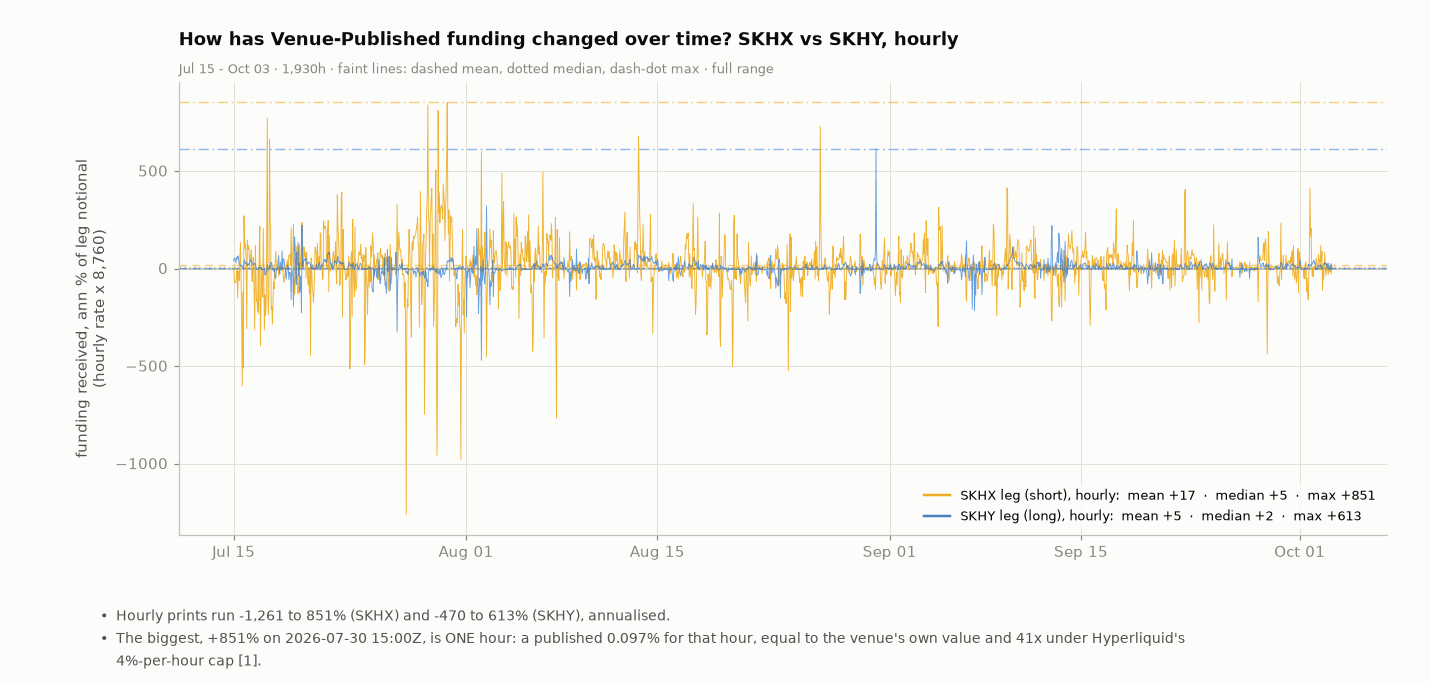

In [7]:
# ---- 1b. SKHX vs SKHY, hourly, ONE chart (full range, so the max is in the frame) ----
fig, ax = plt.subplots(figsize=(13, 6.2))
ax.plot(fA.index, fA, color=C_A, linewidth=0.6, alpha=0.8, zorder=3)
ax.plot(fB.index, fB, color=C_B, linewidth=0.6, alpha=0.7, zorder=3)
ha, hb = stat3(ax, fA.iloc[1:], C_A), stat3(ax, fB.iloc[1:], C_B)
ax.plot([], [], color=C_A, linewidth=1.6, label=tag("SKHX leg (short), hourly", ha, 0)); ax.plot([], [], color=C_B, linewidth=1.6, label=tag("SKHY leg (long), hourly", hb, 0))
ax.axhline(0, color=AXIS, linewidth=1, zorder=1)
yfit(ax, [fA, fB], pad=0.05); ax.set_ylabel("funding received, ann % of leg notional\n(hourly rate x 8,760)")
ax.legend(loc="lower right", fontsize=8.5, ncol=1, **LEG); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(ax, "How has Venue-Published funding changed over time? SKHX vs SKHY, hourly", f"{WS} · {KEY} · full range")
finish(fig, [f"Hourly prints run {fA.min():,.0f} to {fA.max():,.0f}% (SKHX) and {fB.min():,.0f} to {fB.max():,.0f}% (SKHY), annualised.",
             f"The biggest, +{UC['annualised_pct']:,.0f}% on {UC['hour'][:16]}Z, is ONE hour: a published {UC['pct_per_hour']:.3f}% for that hour, equal to the venue's own value and {UC['times_under_cap']:.0f}x under Hyperliquid's 4%-per-hour cap [1]."], top=0.88, right=0.97)
figstyle.show(fig, "fig:s2-funding-hourly", FIGURES)
STATS["funding_hourly"] = {"A": ha, "B": hb, "A_min": float(fA.min()), "B_min": float(fB.min())}

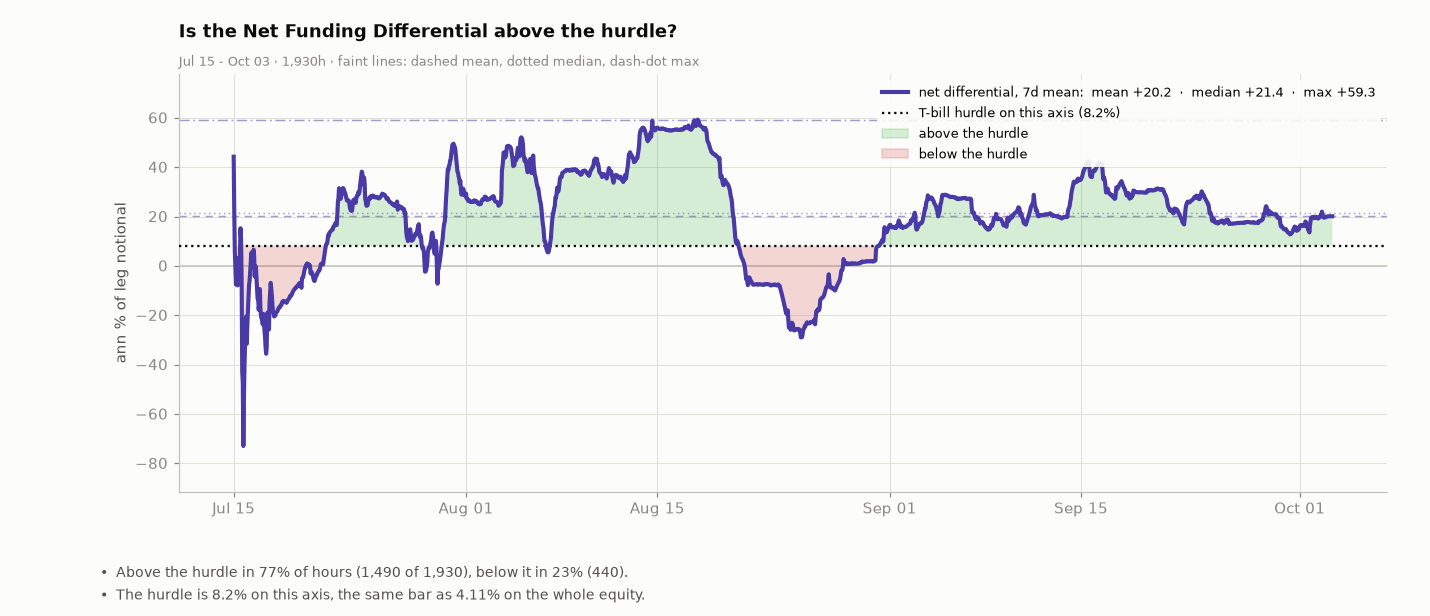

In [8]:
# ---- 2. Is the Net Funding Differential above the hurdle? (7d mean only) ----
fig, ax = plt.subplots(figsize=(13, 5.6))
ax.plot(d_7.index, d_7, color=C_NET, linewidth=2.7, zorder=4)
vn = stat3(ax, d_7, C_NET)
ax.plot([], [], color=C_NET, linewidth=2.7, label=tag("net differential, 7d mean", vn))
ax.axhline(HURDLE_LEG, color=INK, linestyle=":", linewidth=1.5, zorder=3, label=f"T-bill hurdle on this axis ({HURDLE_LEG:.1f}%)")
ax.axhline(0, color=AXIS, linewidth=1, zorder=2)
d7c = d_7.dropna()
ax.fill_between(d7c.index, d7c, HURDLE_LEG, where=(d7c >= HURDLE_LEG), interpolate=True, color=GOOD, alpha=0.16, linewidth=0, zorder=2)
ax.fill_between(d7c.index, d7c, HURDLE_LEG, where=(d7c < HURDLE_LEG), interpolate=True, color=CRIT, alpha=0.20, linewidth=0, zorder=2)
ax.fill_between([], [], color=GOOD, alpha=0.16, label="above the hurdle"); ax.fill_between([], [], color=CRIT, alpha=0.20, label="below the hurdle")
yfit(ax, [d_7.dropna()], pad=0.14); ax.set_ylabel("ann % of leg notional")
ax.legend(loc="upper right", fontsize=8.5, **LEG); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
n_up, n_all = int(d7c.gt(HURDLE_LEG).sum()), int(len(d7c))
share = n_up / n_all * 100
ask(ax, "Is the Net Funding Differential above the hurdle?", f"{WS} · {KEY}")
finish(fig, [f"Above the hurdle in {share:.0f}% of hours ({n_up:,} of {n_all:,}), below it in {100 - share:.0f}% ({n_all - n_up:,}).",
             f"The hurdle is {HURDLE_LEG:.1f}% on this axis, the same bar as {HURDLE_EQ:.2f}% on the whole equity."], top=0.88, right=0.97)
figstyle.show(fig, "fig:s2-net-vs-hurdle", FIGURES)
STATS["net_vs_hurdle"] = {"share_above": share, "share_below": 100 - share, "hours_above": n_up, "hours_all": n_all, "stats": vn, "min7": float(d_7.min())}

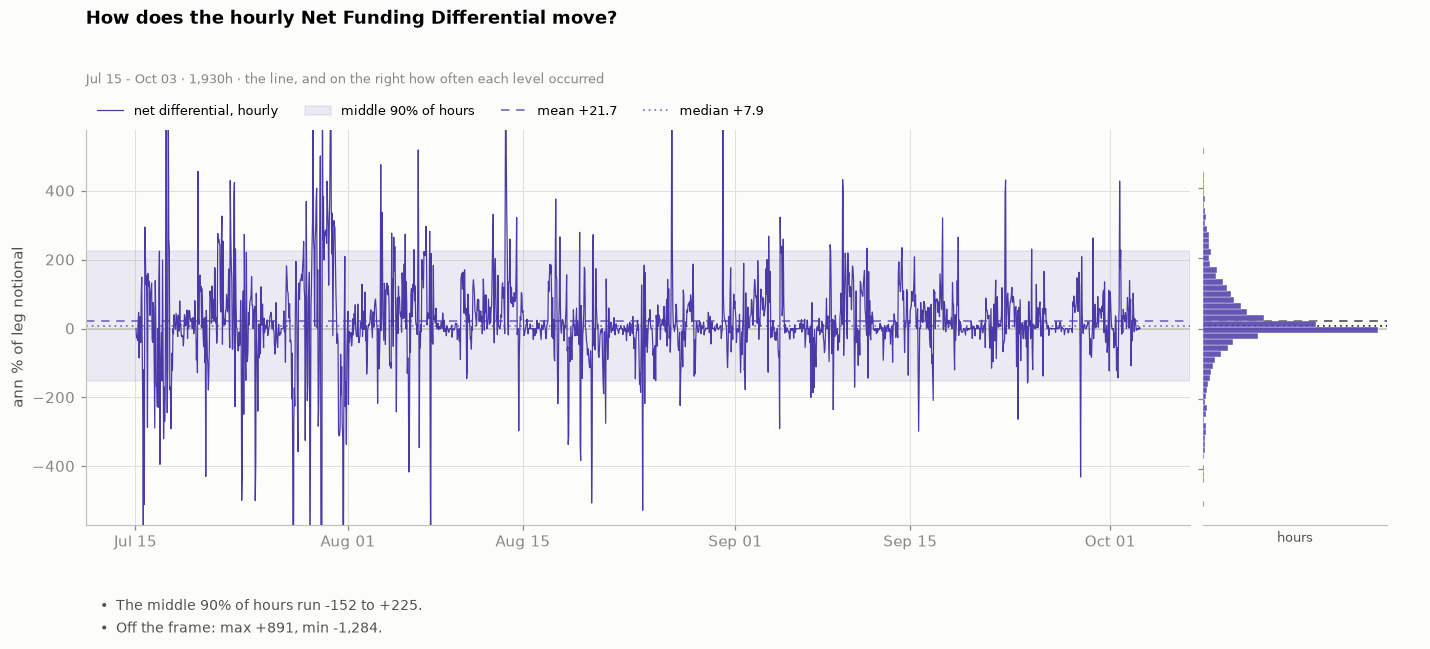

In [9]:
# ---- 3. The hourly net differential: the line, with its distribution beside it ----
dn = d_h.iloc[1:]
lo_, hi_ = np.nanpercentile(dn, 0.5), np.nanpercentile(dn, 99.5)
p5, p95 = np.nanpercentile(dn, 5), np.nanpercentile(dn, 95)
fig = plt.figure(figsize=(13, 5.9))
bm = figstyle.bullets(fig, [f"The middle 90% of hours run {p5:+.0f} to {p95:+.0f}.", f"Off the frame: max {dn.max():+,.0f}, min {dn.min():+,.0f}."])
gs = fig.add_gridspec(1, 2, width_ratios=[6, 1], wspace=0.02, left=0.06, right=0.97, top=0.80, bottom=bm + 0.5 / 5.9)
ax, axh = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
ax.plot(dn.index, dn, color=C_NET, linewidth=0.8, zorder=3, label="net differential, hourly")
ax.axhspan(p5, p95, color=C_NET, alpha=0.09, zorder=1, label="middle 90% of hours")
ax.axhline(dn.mean(), color=C_NET, linewidth=1.1, linestyle=LS["mean"], alpha=0.75, zorder=2, label=f"mean {dn.mean():+.1f}")
ax.axhline(dn.median(), color=C_NET, linewidth=1.1, linestyle=LS["median"], alpha=0.75, zorder=2, label=f"median {dn.median():+.1f}")
ax.axhline(0, color=AXIS, linewidth=1, zorder=1)
ax.set_ylim(lo_ - (hi_ - lo_) * 0.06, hi_ + (hi_ - lo_) * 0.06); ax.set_ylabel("ann % of leg notional")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d")); ax.legend(loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=4, fontsize=8.5, frameon=False)
axh.hist(dn[(dn >= lo_) & (dn <= hi_)], bins=60, orientation="horizontal", color=C_NET, alpha=0.85, edgecolor=SURF, linewidth=0.3, zorder=3)
axh.axhline(dn.mean(), color=INK2, linewidth=1.1, linestyle=LS["mean"]); axh.axhline(dn.median(), color=INK, linewidth=1.1, linestyle=LS["median"])
axh.axhline(0, color=AXIS, linewidth=1); axh.set_xticks([]); axh.tick_params(labelleft=False); axh.grid(False); axh.set_xlabel("hours", fontsize=8.5)
for sp in ("left",):
    axh.spines[sp].set_visible(False)
fig_ask(fig, "How does the hourly Net Funding Differential move?", f"{WS} · the line, and on the right how often each level occurred", 0.80)
figstyle.show(fig, "fig:s2-net-hourly", FIGURES)
STATS["net_hourly"] = {"min": float(dn.min()), "max": float(dn.max()), "mean": float(dn.mean()), "median": float(dn.median()), "p5": float(p5), "p95": float(p95)}

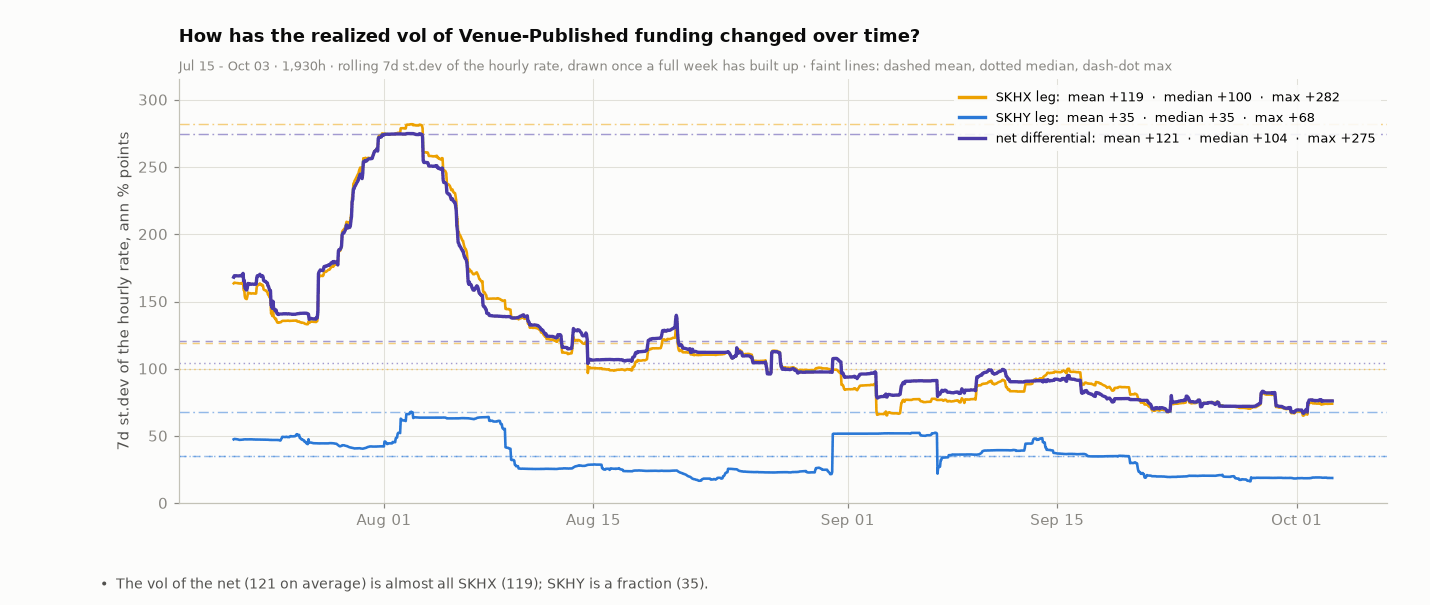

In [10]:
# ---- 4. Realized vol of Venue-Published funding ----
fig, ax = plt.subplots(figsize=(13, 5.5))
V, VS = {}, {}
for s, col, lab in ((fA, C_A, "SKHX leg"), (fB, C_B, "SKHY leg"), (d_h, C_NET, "net differential")):
    v7 = s.rolling(168).std(); V[lab] = v7
    ax.plot(v7.index, v7, color=col, linewidth=2.2 if lab == "net differential" else 1.7, zorder=4 if lab == "net differential" else 3)
    VS[lab] = stat3(ax, v7, col)
    ax.plot([], [], color=col, linewidth=2.2, label=tag(lab, VS[lab], 0))
ax.set_ylabel("7d st.dev of the hourly rate, ann % points"); ax.set_ylim(0, float(max(v.max() for v in V.values())) * 1.12)
ax.legend(loc="upper right", fontsize=8.5, **LEG); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(ax, "How has the realized vol of Venue-Published funding changed over time?", f"{WS} · rolling 7d st.dev of the hourly rate, drawn once a full week has built up · {KEY}")
finish(fig, [f"The vol of the net ({VS['net differential']['mean']:,.0f} on average) is almost all SKHX ({VS['SKHX leg']['mean']:,.0f}); SKHY is a fraction ({VS['SKHY leg']['mean']:,.0f})."], top=0.87, right=0.97)
figstyle.show(fig, "fig:s2-funding-vol", FIGURES)
STATS["funding_vol"] = VS

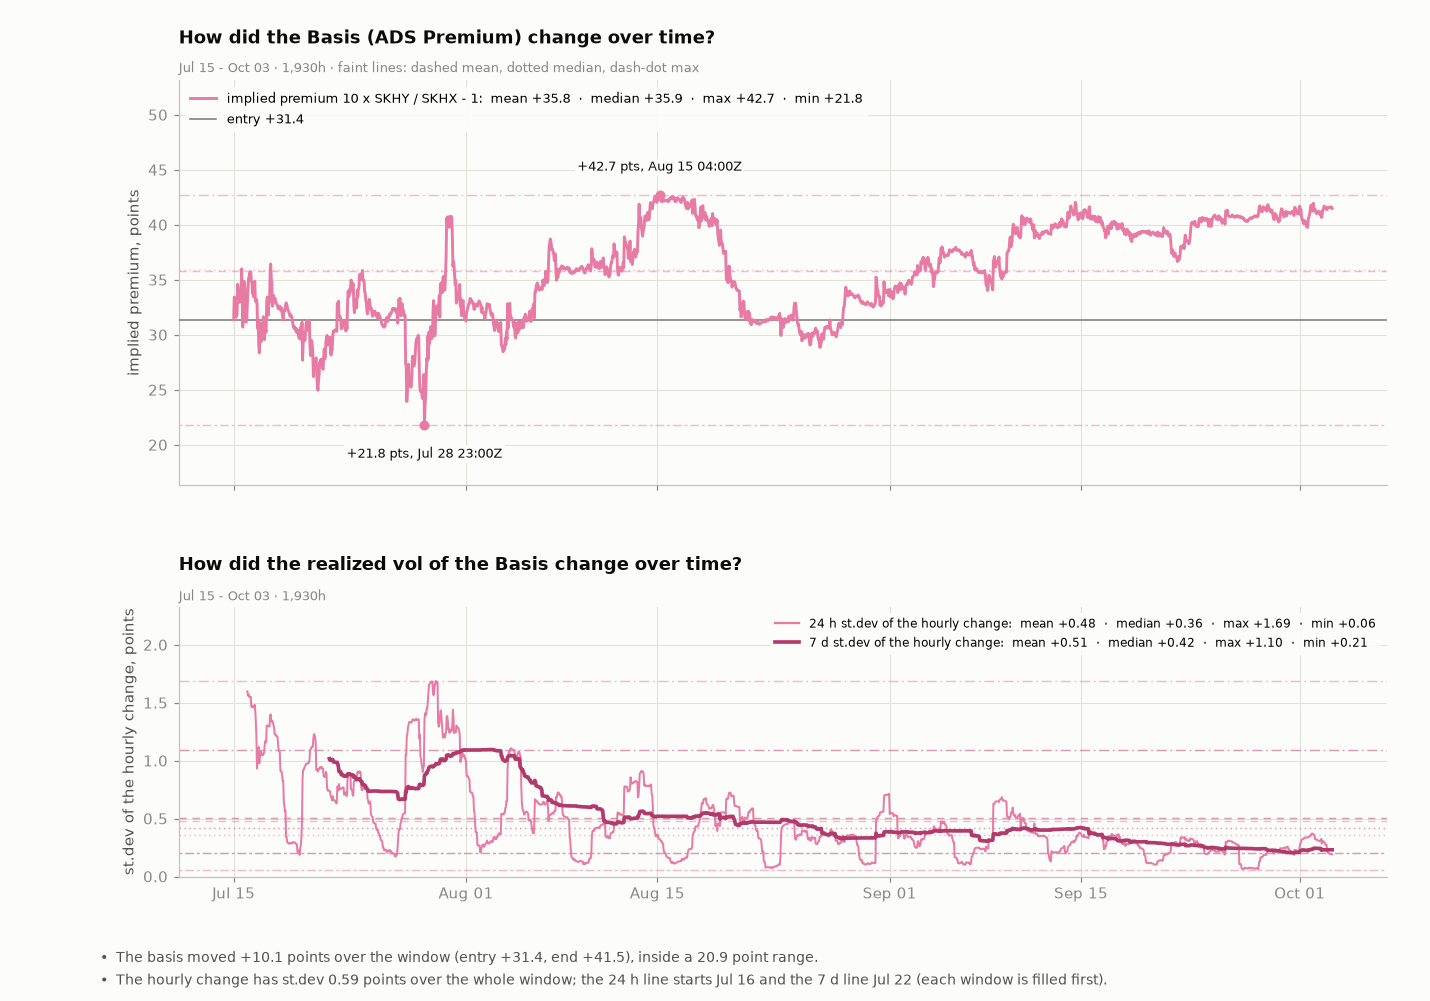

In [11]:
# ---- 5. The basis and its realized vol (one figure, two panels) ----
dP = prem.diff(); V24, V168 = dP.rolling(24).std(), dP.rolling(168).std()
fig, (pa0, pa1) = plt.subplots(2, 1, figsize=(13, 9.1), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
pa0.plot(prem.index, prem, color=C_PREM, linewidth=1.9, zorder=4)
vp = stat3(pa0, prem, C_PREM, with_min=True)
pa0.plot([], [], color=C_PREM, linewidth=1.9, label=tag("implied premium 10 x SKHY / SKHX - 1", vp, 1))
pa0.axhline(P0, color=INK2, linestyle="-", linewidth=1.1, alpha=0.7, zorder=3, label=f"entry {P0:+.1f}")
i_lo, i_hi = prem.idxmin(), prem.idxmax()
for ts_, v_, dy in ((i_lo, prem.min(), -14), (i_hi, prem.max(), 14)):
    pa0.plot([ts_], [v_], "o", color=C_PREM, markersize=5.5, zorder=6)
    pa0.annotate(f"{v_:+.1f} pts, {ts_:%b %d %H:%MZ}", xy=(ts_, v_), xytext=(0, dy), textcoords="offset points", ha="center", va="top" if dy < 0 else "bottom",
                 fontsize=8.5, color=INK, zorder=7, bbox=dict(facecolor=SURF, edgecolor="none", pad=1.4))
pa0.set_ylabel("implied premium, points")
lo2, hi2 = prem.min(), prem.max(); pa0.set_ylim(lo2 - (hi2 - lo2) * 0.26, hi2 + (hi2 - lo2) * 0.50); pa0.legend(loc="upper left", fontsize=8.5, **LEG)
ask(pa0, "How did the Basis (ADS Premium) change over time?", f"{WS} · {KEY}")
pa1.plot(V24.index, V24, color=C_PREM, linewidth=1.3, zorder=4); pa1.plot(V168.index, V168, color=C_PREM_DK, linewidth=2.4, zorder=5)     # the basis family: blue is the SKHY leg's, so it is not used here
v24, v168 = stat3(pa1, V24, C_PREM, with_min=True), stat3(pa1, V168, C_PREM_DK, with_min=True)
pa1.plot([], [], color=C_PREM, linewidth=1.5, label=tag("24 h st.dev of the hourly change", v24, 2)); pa1.plot([], [], color=C_PREM_DK, linewidth=2.4, label=tag("7 d st.dev of the hourly change", v168, 2))
pa1.set_ylabel("st.dev of the hourly change, points"); pa1.set_ylim(0, float(V24.max()) * 1.38); pa1.legend(loc="upper right", fontsize=8.0, **LEG)
ask(pa1, "How did the realized vol of the Basis change over time?", f"{WS}")
pa1.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
finish(fig, [f"The basis moved {prem.iloc[-1] - P0:+.1f} points over the window (entry {P0:+.1f}, end {prem.iloc[-1]:+.1f}), inside a {hi2 - lo2:.1f} point range.",
             f"The hourly change has st.dev {dP.std():.2f} points over the whole window; the 24 h line starts {prem.index[24]:%b %d} and the 7 d line {prem.index[168]:%b %d} (each window is filled first)."], top=0.92, hspace=0.36, right=0.97)
figstyle.show(fig, "fig:s2-basis", FIGURES)
STATS["basis"] = {"entry": float(P0), "end": float(prem.iloc[-1]), "stats": vp, "v24": v24, "v168": v168}

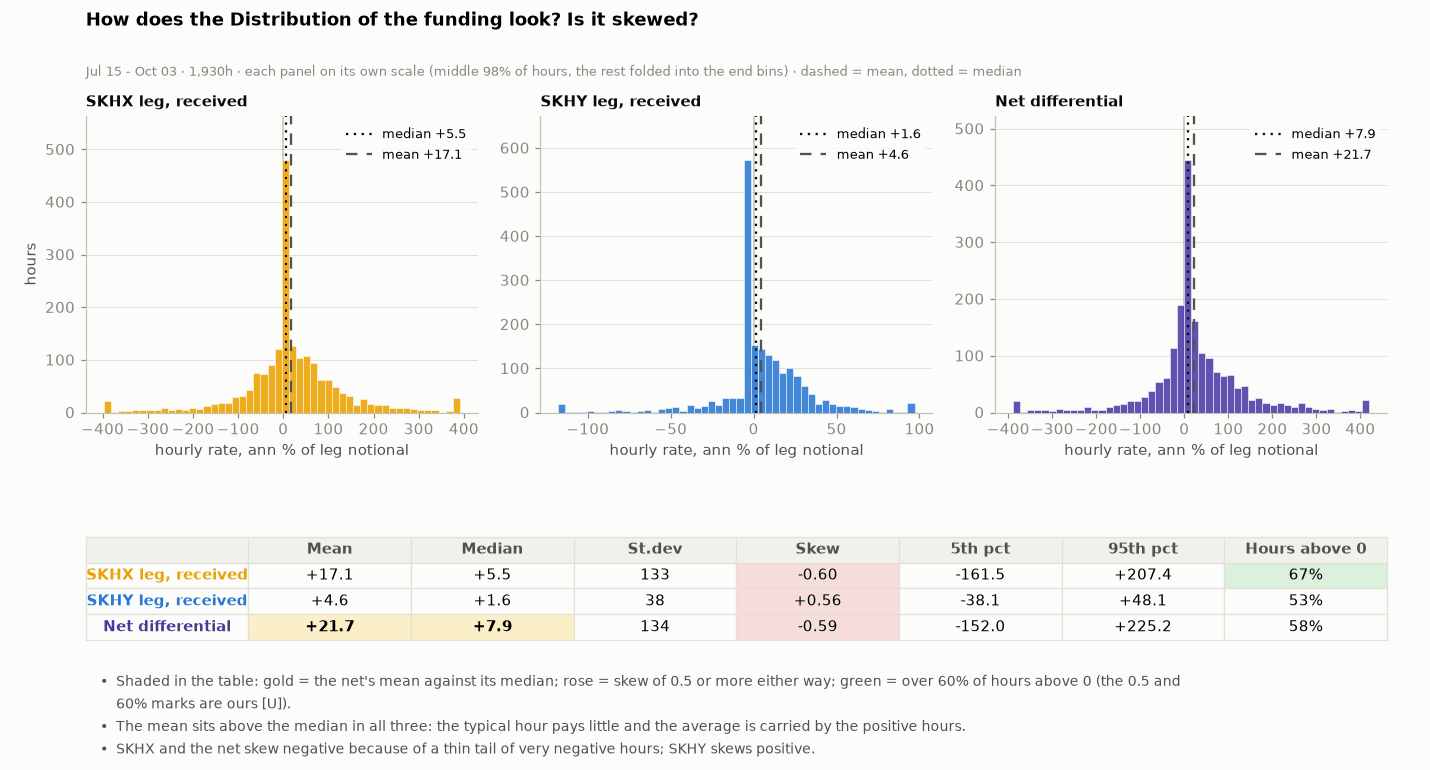

In [12]:
# ---- 6. Distribution: three histograms with ONE table in the same figure ----
PS = HP.funding_persistence(rows, "short_a")
SER = ((fA.iloc[1:], C_A, "SKHX leg, received"), (fB.iloc[1:], C_B, "SKHY leg, received"), (dn, C_NET, "Net differential"))
fig = plt.figure(figsize=(13, 7.0))
bm = figstyle.bullets(fig, ["Shaded in the table: gold = the net's mean against its median; rose = skew of 0.5 or more either way; green = over 60% of hours above 0 (the 0.5 and 60% marks are ours [U]).",
                            "The mean sits above the median in all three: the typical hour pays little and the average is carried by the positive hours.",
                            "SKHX and the net skew negative because of a thin tail of very negative hours; SKHY skews positive."])
gs = fig.add_gridspec(2, 3, height_ratios=[3.3, 1.15], hspace=0.62, wspace=0.16, left=0.06, right=0.97, top=0.85, bottom=bm + 0.02)
axs = [fig.add_subplot(gs[0, i]) for i in range(3)]
axt = fig.add_subplot(gs[1, :]); axt.axis("off")
D = {}
for a_, (s_, col, lab) in zip(axs, SER):
    lo_, hi_ = np.nanpercentile(s_, 1), np.nanpercentile(s_, 99)
    a_.hist(s_.clip(lo_, hi_), bins=np.linspace(lo_, hi_, 51), color=col, alpha=0.88, edgecolor=SURF, linewidth=0.4, zorder=3)
    a_.axvline(0, color=AXIS, linewidth=1, zorder=2)
    a_.axvline(s_.median(), color=INK, linestyle=LS["median"], linewidth=1.5, zorder=5, label=f"median {s_.median():+.1f}")        # the same styles as every other chart: mean dashed, median dotted
    a_.axvline(s_.mean(), color=INK2, linestyle=LS["mean"], linewidth=1.5, zorder=5, label=f"mean {s_.mean():+.1f}")
    a_.set_title(lab, fontsize=10, loc="left", pad=6); a_.set_xlabel("hourly rate, ann % of leg notional"); a_.legend(loc="upper right", fontsize=8.5, **LEG)
    a_.grid(axis="x", visible=False); a_.set_ylim(top=a_.get_ylim()[1] * 1.12)
    D[lab] = {"mean": s_.mean(), "median": s_.median(), "std": s_.std(), "skew": s_.skew(), "p5": np.nanpercentile(s_, 5), "p95": np.nanpercentile(s_, 95),
              "min": s_.min(), "max": s_.max(), "pos": float((s_ > 0).mean() * 100)}
axs[0].set_ylabel("hours")
cols = ["", "Mean", "Median", "St.dev", "Skew", "5th pct", "95th pct", "Hours above 0"]
cells = [[lab, f"{d['mean']:+.1f}", f"{d['median']:+.1f}", f"{d['std']:,.0f}", f"{d['skew']:+.2f}", f"{d['p5']:+.1f}", f"{d['p95']:+.1f}", f"{d['pos']:.0f}%"] for lab, d in D.items()]
tb = axt.table(cellText=cells, colLabels=cols, cellLoc="center", loc="center", bbox=[0, 0, 1, 1])
tb.auto_set_font_size(False); tb.set_fontsize(10)
for (r_, c_), cell in tb.get_celld().items():
    cell.set_edgecolor(GRID); cell.set_linewidth(0.8)
    if r_ == 0:
        cell.set_facecolor("#f1f0ea"); cell.set_text_props(weight="bold", color=INK2)
    else:
        cell.set_facecolor(SURF)
        d_ = list(D.values())[r_ - 1]
        if c_ == 0:
            cell.set_text_props(weight="bold", color=SER[r_ - 1][1]); cell._loc = "left"
        elif r_ == 3 and c_ in (1, 2):                     # the net's mean against its median: the headline gap
            cell.set_facecolor("#fbefc8"); cell.set_text_props(weight="bold")
        elif c_ == 4 and abs(d_["skew"]) >= 0.5:           # visibly skewed
            cell.set_facecolor("#f7dcdc")
        elif c_ == 7 and d_["pos"] > 60:                   # paid in most hours
            cell.set_facecolor("#dcf1dc")
fig_ask(fig, "How does the Distribution of the funding look? Is it skewed?",
        f"{WS} · each panel on its own scale (middle 98% of hours, the rest folded into the end bins) · dashed = mean, dotted = median", 0.85)
figstyle.show(fig, "fig:s2-distribution", FIGURES)
STATS["dist"] = D
STATS["persist"] = {"half_life_h": float(PS["half_life_h"]), "acf24": float(PS["acf"][24])}

## S3 · Core result - Base test

Does it pay at 1x, with nothing amplifying it?

In [13]:
WSH = f"{df.index[0]:%b %d} - {df.index[-1]:%b %d} \u00b7 {len(df):,}h \u00b7 1x cross \u00b7 always-hold \u00b7 costs on"
LS = figstyle.LS
DD_CUT = -1.0                                  # [U] a drawdown episode is worth showing at 1% of equity or deeper

eq = num(df["equity_total"]) / 1e6
uw = (eq / eq.cummax() - 1) * 100
assert abs(uw.min() / 100 - res["max_drawdown"]) < 1e-9
# ---- the drawdown episodes: from the high before, to the hour it is regained (or the end) ----
eps, i, idx, n_ = [], 0, eq.index, len(eq)
while i < n_:
    if uw.iloc[i] < 0:
        j = i
        while j + 1 < n_ and uw.iloc[j + 1] < 0:
            j += 1
        seg = uw.iloc[i:j + 1]
        eps.append({"peak": idx[max(i - 1, 0)], "trough": seg.idxmin(), "end": idx[j], "recovered": j + 1 < n_, "depth": float(seg.min())})
        i = j + 1
    else:
        i += 1
eps.sort(key=lambda e: e["depth"])
EP = [e for e in eps if e["depth"] <= DD_CUT]
for k, e in enumerate(EP, 1):
    e["rank"] = k
    e["days_down"] = (e["trough"] - e["peak"]).total_seconds() / 86400
    e["days_recover"] = (e["end"] - e["trough"]).total_seconds() / 86400

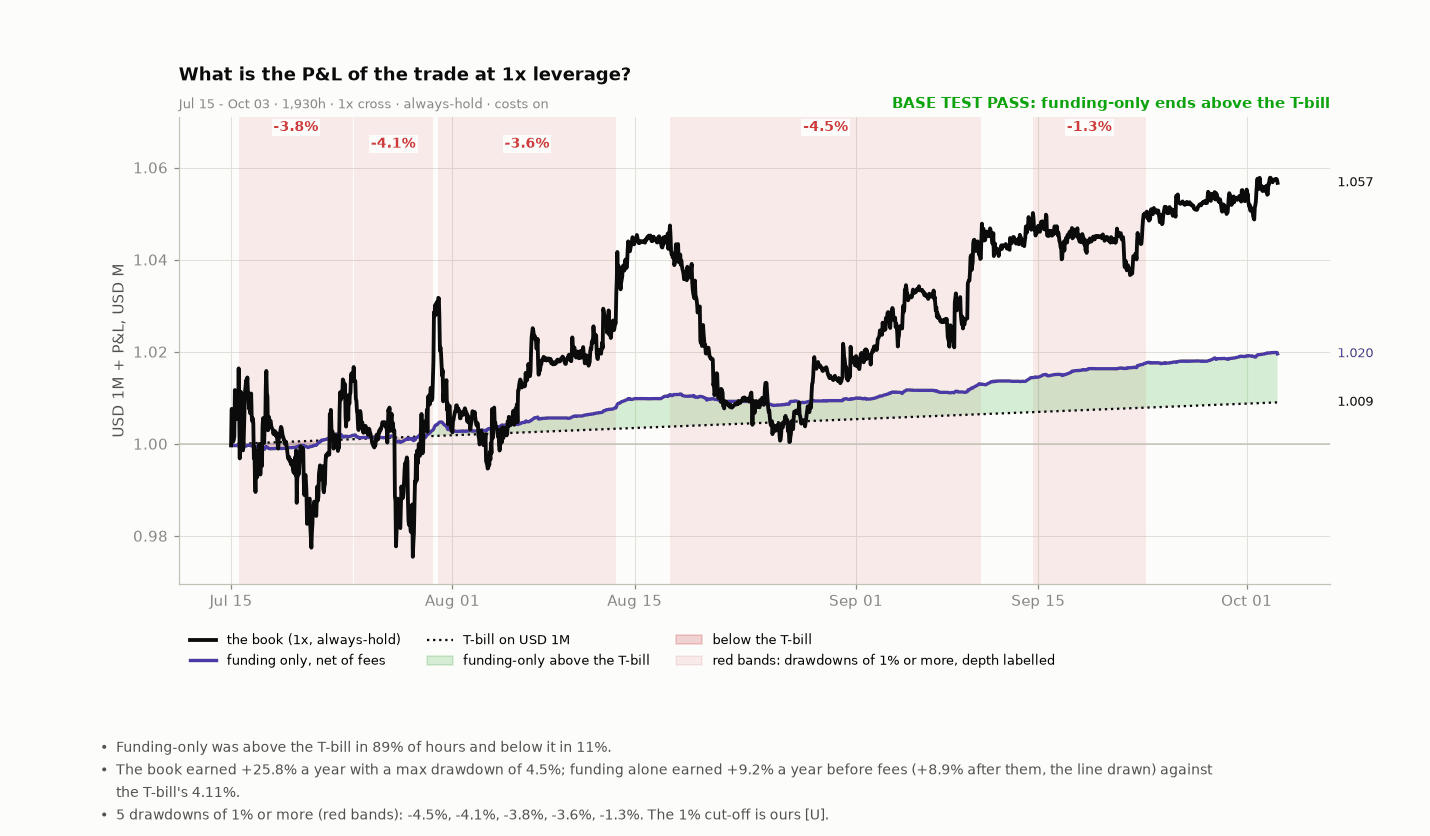

In [14]:
# ---- 1. What is the P&L of the trade at 1x leverage? ----
fund_only = (EQUITY + num(df["cum_funding_net"]) - num(df["cum_fees"]) - num(df["cum_liq_fees"])) / 1e6
tbill = pd.Series(EQUITY * (1 + p1.hurdle_ann * np.asarray((df.index - df.index[0]).total_seconds()) / (365 * 86400)) / 1e6, index=df.index)
share_up = float((fund_only >= tbill).mean() * 100)
G1a = bool(fund_only.iloc[-1] > tbill.iloc[-1])
H1 = 7.6
fig, ax = plt.subplots(figsize=(13, H1))
for e in EP:
    ax.axvspan(e["peak"], e["end"], color=CRIT, alpha=0.09, linewidth=0, zorder=1)
ax.plot(df.index, eq, color=INK, linewidth=2.5, zorder=5, label="the book (1x, always-hold)")
ax.plot(df.index, fund_only, color=C_NET, linewidth=2.2, zorder=4, label="funding only, net of fees")
ax.plot(df.index, tbill, color=INK, linewidth=1.5, linestyle=":", zorder=3, label=f"T-bill on {usdm(EQUITY)}")          # a threshold is ink, dotted (as in S2)
ax.fill_between(df.index, fund_only, tbill, where=(fund_only >= tbill), interpolate=True, color=GOOD, alpha=0.16, linewidth=0, zorder=2)
ax.fill_between(df.index, fund_only, tbill, where=(fund_only < tbill), interpolate=True, color=CRIT, alpha=0.22, linewidth=0, zorder=2)
ax.axhline(1.0, color=AXIS, linewidth=1, zorder=1)
ylo, yhi = ax.get_ylim(); ax.set_ylim(ylo - (yhi - ylo) * 0.02, yhi + (yhi - ylo) * 0.10)
for k, e in enumerate(EP):                                     # the magnitude of each drawdown, on its band
    xm = e["peak"] + (e["end"] - e["peak"]) / 2
    ax.text(xm, yhi + (yhi - ylo) * (0.075 if k % 2 == 0 else 0.035), f"{e['depth']:.1f}%", ha="center", va="center", fontsize=9, color=CRIT, fontweight="bold",
            bbox=dict(facecolor=SURF, edgecolor="none", pad=1.2), zorder=7)
for s_, c_ in ((eq, INK), (fund_only, C_NET), (tbill, INK)):
    ax.annotate(f" {s_.iloc[-1]:.3f}", xy=(1.003, s_.iloc[-1]), xycoords=("axes fraction", "data"), color=c_, fontsize=8.5, va="center", annotation_clip=False)
ax.fill_between([], [], color=GOOD, alpha=0.16, label="funding-only above the T-bill")
ax.fill_between([], [], color=CRIT, alpha=0.22, label="below the T-bill")
ax.fill_between([], [], color=CRIT, alpha=0.09, label="red bands: drawdowns of 1% or more, depth labelled")
ax.text(1.0, 1.012, ("BASE TEST PASS: funding-only ends above the T-bill" if G1a else "BASE TEST FAIL"), transform=ax.transAxes, ha="right", va="bottom",
        color=(GOOD if G1a else CRIT), fontsize=9.5, fontweight="bold")
ax.set_ylabel("USD 1M + P&L, USD M"); ax.legend(loc="upper left", bbox_to_anchor=(0.0, -0.08), ncol=3, fontsize=8.5, frameon=False); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(ax, "What is the P&L of the trade at 1x leverage?", WSH)
bm = figstyle.bullets(fig, [f"Funding-only was above the T-bill in {share_up:.0f}% of hours and below it in {100 - share_up:.0f}%.",
                            f"The book earned {res['ann_pct']:+.1f}% a year with a max drawdown of {abs(res['max_drawdown']) * 100:.1f}%; funding alone earned {res['funding_ann_pct_aum']:+.1f}% a year before fees ({(res['funding_net'] - res['fees'] - res['liq_fees']) / EQUITY * 365 / res['days'] * 100:+.1f}% after them, the line drawn) against the T-bill's {HURDLE_PCT:.2f}%.",
                            f"{len(EP)} drawdowns of 1% or more (red bands): " + ", ".join(f"{e['depth']:.1f}%" for e in EP) + ". The 1% cut-off is ours [U]."])
plt.subplots_adjust(top=0.86, right=0.93, bottom=bm + 1.25 / H1)
figstyle.show(fig, "fig:s3-equity", FIGURES)
STATS["equity"] = {"book_end": float(eq.iloc[-1]), "fund_end": float(fund_only.iloc[-1]), "tbill_end": float(tbill.iloc[-1]), "share_up": share_up,
                   "ann": res["ann_pct"], "fund_ann": res["funding_ann_pct_aum"], "maxdd": res["max_drawdown"] * 100, "pass": G1a, "n_dd_eps": len(EP), "n_all_eps": len(eps),
                   "dd_depths": [round(e["depth"], 2) for e in EP]}

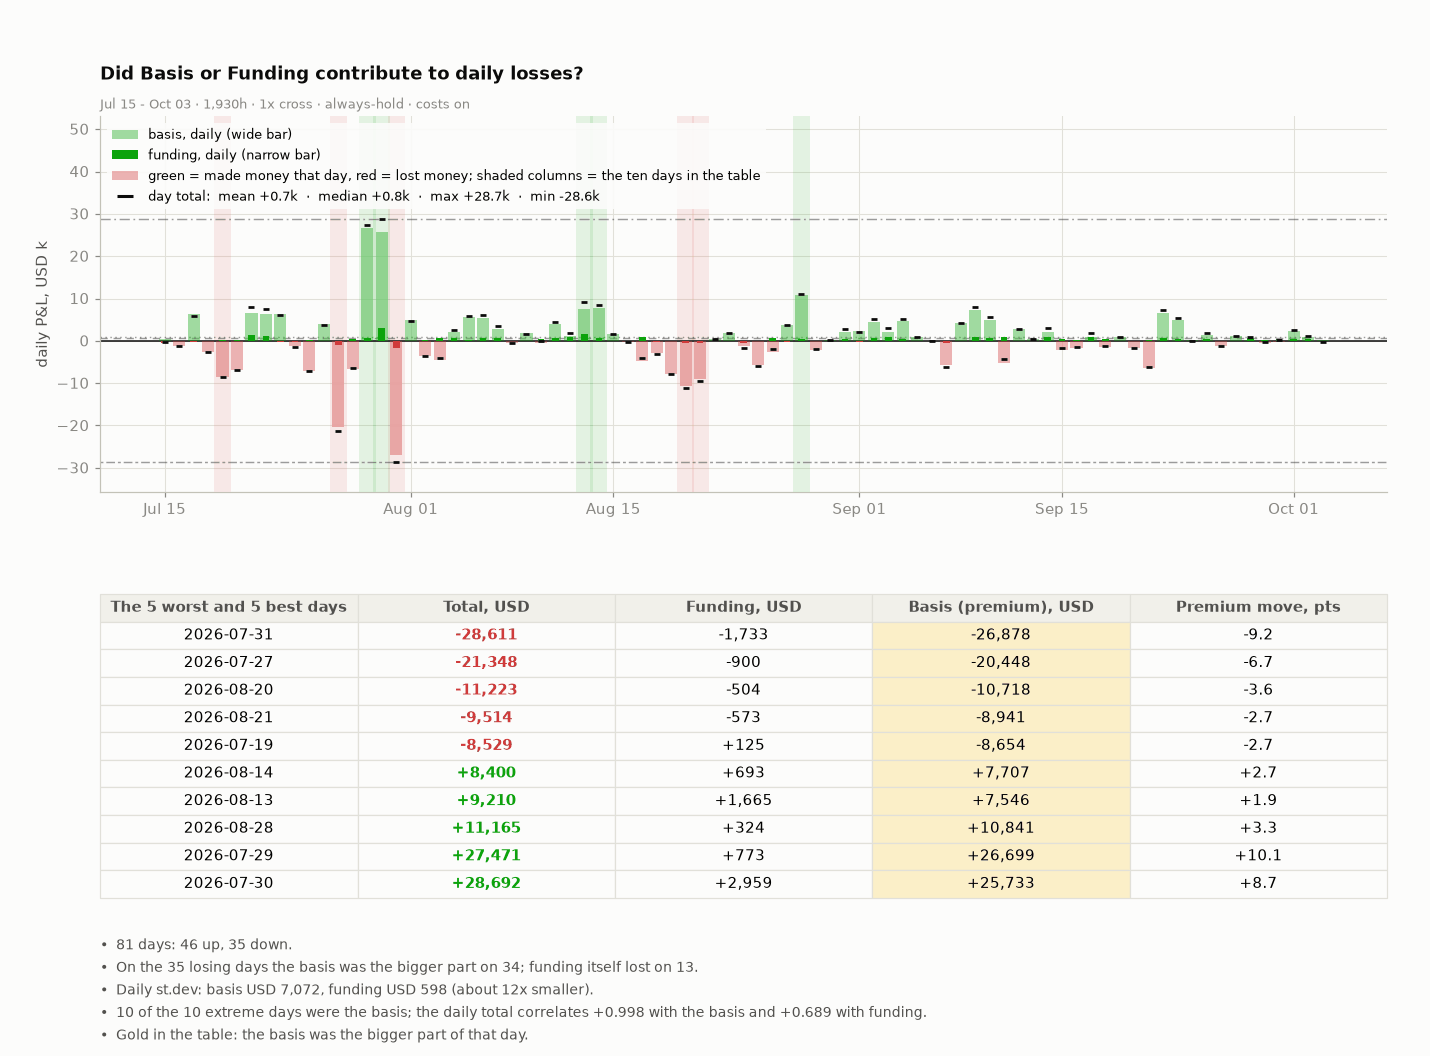

In [15]:
# ---- 4. Did Basis or Funding contribute to daily losses? ----
EXT = pd.concat([DAY.nsmallest(5, "total"), DAY.nlargest(5, "total")]).sort_values("total")
loss = DAY[DAY["total"] < 0]
basis_bigger = int((loss["premium"].abs() > loss["funding"].abs()).sum())
fund_neg = int((loss["funding"] < 0).sum())
n_basis = int((EXT["premium"].abs() > EXT["funding"].abs()).sum())
H4 = 9.6
fig = plt.figure(figsize=(13, H4))
bm = figstyle.bullets(fig, [f"{len(DAY)} days: {(DAY['total'] > 0).sum()} up, {len(loss)} down.",
                            f"On the {len(loss)} losing days the basis was the bigger part on {basis_bigger}; funding itself lost on {fund_neg}.",
                            f"Daily st.dev: basis USD {DAY['premium'].std():,.0f}, funding USD {DAY['funding'].std():,.0f} (about {DAY['premium'].std() / DAY['funding'].std():.0f}x smaller).",
                            f"{n_basis} of the {len(EXT)} extreme days were the basis; the daily total correlates {DAY['total'].corr(DAY['premium']):+.3f} with the basis and {DAY['total'].corr(DAY['funding']):+.3f} with funding.",
                            "Gold in the table: the basis was the bigger part of that day."])
gs = fig.add_gridspec(2, 1, height_ratios=[2.6, 2.1], hspace=0.30, left=0.07, right=0.97, top=0.89, bottom=bm + 0.02)
ax, axt = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]); axt.axis("off")
x = DAY.index
for d_, r_ in EXT.iterrows():                                    # the ten days in the table, shaded on the chart
    ax.axvspan(d_ - pd.Timedelta(hours=14), d_ + pd.Timedelta(hours=14), color=(CRIT if r_["total"] < 0 else GOOD), alpha=0.10, linewidth=0, zorder=1)
ax.bar(x, DAY["premium"] / 1e3, width=pd.Timedelta(hours=20), color=[GOOD if v > 0 else CRIT for v in DAY["premium"]], alpha=0.38, zorder=3)
ax.bar(x, DAY["funding"] / 1e3, width=pd.Timedelta(hours=11), color=[GOOD if v > 0 else CRIT for v in DAY["funding"]], zorder=4)
ax.scatter(x, DAY["total"] / 1e3, s=20, marker="_", color=INK, linewidths=1.8, zorder=5)
tt = DAY["total"] / 1e3
for k, y in (("mean", tt.mean()), ("median", tt.median()), ("max", tt.max()), ("min", tt.min())):
    ax.axhline(y, color=INK, linewidth=0.95, linestyle=LS[k], alpha=0.4, zorder=2)
ax.axhline(0, color=INK, linewidth=1, zorder=2)
_h = [Patch(facecolor=GOOD, alpha=0.38, label="basis, daily (wide bar)"),
      Patch(facecolor=GOOD, label="funding, daily (narrow bar)"),
      Patch(facecolor=CRIT, alpha=0.38, label="green = made money that day, red = lost money; shaded columns = the ten days in the table"),
      plt.Line2D([], [], color=INK, marker="_", markersize=10, markeredgewidth=2, linestyle="none", label=f"day total:  mean {tt.mean():+.1f}k  ·  median {tt.median():+.1f}k  ·  max {tt.max():+.1f}k  ·  min {tt.min():+.1f}k")]
ax.set_ylabel("daily P&L, USD k"); ax.legend(handles=_h, loc="upper left", fontsize=8.5, **LEG); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set_ylim(tt.min() * 1.25, tt.max() * 1.85)
ask(ax, "Did Basis or Funding contribute to daily losses?", f"{WSH}")
cells = [[f"{d:%Y-%m-%d}", f"{r['total']:+,.0f}", f"{r['funding']:+,.0f}", f"{r['premium']:+,.0f}", f"{r['premium_pct']:+.1f}"] for d, r in EXT.iterrows()]
tb = axt.table(cellText=cells, colLabels=["The 5 worst and 5 best days", "Total, USD", "Funding, USD", "Basis (premium), USD", "Premium move, pts"], cellLoc="center", loc="center", bbox=[0, 0, 1, 1])
tb.auto_set_font_size(False); tb.set_fontsize(9.5)
for (r_, c_), cell in tb.get_celld().items():
    cell.set_edgecolor(GRID); cell.set_linewidth(0.8)
    if r_ == 0:
        cell.set_facecolor("#f1f0ea"); cell.set_text_props(weight="bold", color=INK2)
    else:
        row = EXT.iloc[r_ - 1]
        cell.set_facecolor(SURF)
        if c_ == 0:
            cell._loc = "left"
        if c_ == 1:
            cell.set_text_props(color=(GOOD if row["total"] > 0 else CRIT), weight="bold")
        if c_ == 3 and abs(row["premium"]) > abs(row["funding"]):
            cell.set_facecolor("#fbefc8")
figstyle.show(fig, "fig:s3-daily", FIGURES)
STATS["daily"] = {"days": len(DAY), "up": int((DAY['total'] > 0).sum()), "down": len(loss), "n_basis": n_basis, "n_ext": len(EXT), "basis_bigger_on_losing": basis_bigger, "funding_negative_on_losing": fund_neg,
                  "corr_prem": float(DAY['total'].corr(DAY['premium'])), "corr_fund": float(DAY['total'].corr(DAY['funding'])), "ratio": float(DAY['premium'].std() / DAY['funding'].std())}

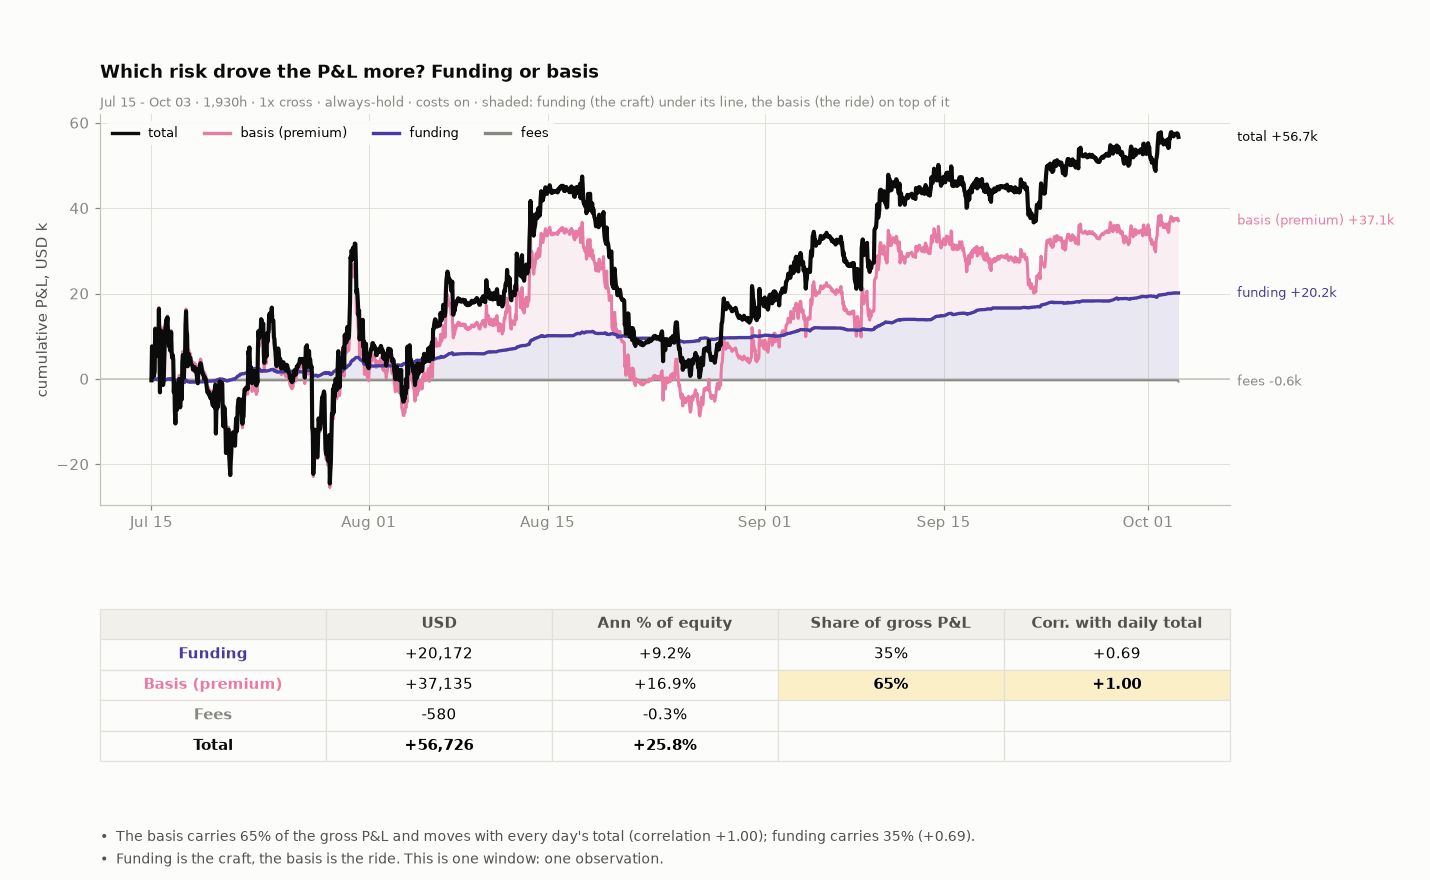

In [16]:
# ---- 2. Which risk drove the P&L more? funding or basis ----
H2 = 8.0
fig = plt.figure(figsize=(13, H2))
bm = figstyle.bullets(fig, [f"The basis carries {res['premium_pnl'] / (res['funding_net'] + res['premium_pnl']) * 100:.0f}% of the gross P&L and moves with every day's total (correlation {DAY['premium'].corr(DAY['total']):+.2f}); funding carries {res['funding_net'] / (res['funding_net'] + res['premium_pnl']) * 100:.0f}% ({DAY['funding'].corr(DAY['total']):+.2f}).",
                            "Funding is the craft, the basis is the ride. This is one window: one observation."])
gs = fig.add_gridspec(2, 1, height_ratios=[3.2, 1.25], hspace=0.38, left=0.07, right=0.86, top=0.87, bottom=bm + 0.45 / H2)
ax, axt = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]); axt.axis("off")
cf, cp = num(df["cum_funding_net"]) / 1e3, num(df["cum_premium_pnl"]) / 1e3
cc = -(num(df["cum_fees"]) + num(df["cum_liq_fees"])) / 1e3
ct = num(df["total_pnl"]) / 1e3
ax.plot(df.index, cp, color=C_PREM, linewidth=2.0, zorder=3); ax.plot(df.index, cf, color=C_NET, linewidth=2.2, zorder=4)
ax.plot(df.index, cc, color=C_COST, linewidth=1.3, zorder=2); ax.plot(df.index, ct, color=INK, linewidth=2.7, zorder=5)
ax.fill_between(df.index, cf, 0, color=C_NET, alpha=0.10, linewidth=0, zorder=1)
ax.fill_between(df.index, cp, cf, where=(cp >= cf), interpolate=True, color=C_PREM, alpha=0.10, linewidth=0, zorder=1)
for s_, c_, nm in ((ct, INK, "total"), (cp, C_PREM, "basis (premium)"), (cf, C_NET, "funding"), (cc, C_COST, "fees")):
    ax.plot([], [], color=c_, linewidth=2.2, label=nm)
    ax.annotate(f" {nm} {s_.iloc[-1]:+,.1f}k", xy=(1.003, s_.iloc[-1]), xycoords=("axes fraction", "data"), color=c_, fontsize=8.5, va="center", annotation_clip=False)
ax.axhline(0, color=AXIS, linewidth=1, zorder=1); ax.set_ylabel("cumulative P&L, USD k"); ax.legend(loc="upper left", ncol=4, fontsize=8.5, **LEG)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(ax, "Which risk drove the P&L more? Funding or basis", f"{WSH} · shaded: funding (the craft) under its line, the basis (the ride) on top of it")
yrs = res["days"] / 365.0
gross = res["funding_net"] + res["premium_pnl"]
corr = {"Funding": DAY["funding"].corr(DAY["total"]), "Basis (premium)": DAY["premium"].corr(DAY["total"])}
tab = [["Funding", res["funding_net"], res["funding_net"] / EQUITY / yrs * 100, res["funding_net"] / gross * 100, corr["Funding"]],
       ["Basis (premium)", res["premium_pnl"], res["premium_pnl"] / EQUITY / yrs * 100, res["premium_pnl"] / gross * 100, corr["Basis (premium)"]],
       ["Fees", -(res["fees"] + res["liq_fees"]), -(res["fees"] + res["liq_fees"]) / EQUITY / yrs * 100, float("nan"), float("nan")],
       ["Total", res["total_pnl"], res["total_pnl"] / EQUITY / yrs * 100, float("nan"), float("nan")]]
cells = [[r[0], f"{r[1]:+,.0f}", f"{r[2]:+.1f}%", ("" if r[3] != r[3] else f"{r[3]:.0f}%"), ("" if r[4] != r[4] else f"{r[4]:+.2f}")] for r in tab]
tb = axt.table(cellText=cells, colLabels=["", "USD", "Ann % of equity", "Share of gross P&L", "Corr. with daily total"], cellLoc="center", loc="center", bbox=[0, 0, 1, 1])
tb.auto_set_font_size(False); tb.set_fontsize(10)
cols_ = {0: C_NET, 1: C_PREM, 2: C_COST, 3: INK}
for (r_, c_), cell in tb.get_celld().items():
    cell.set_edgecolor(GRID); cell.set_linewidth(0.8)
    if r_ == 0:
        cell.set_facecolor("#f1f0ea"); cell.set_text_props(weight="bold", color=INK2)
    else:
        cell.set_facecolor(SURF)
        if c_ == 0:
            cell.set_text_props(weight="bold", color=cols_[r_ - 1]); cell._loc = "left"
        elif r_ == 2 and c_ in (3, 4):
            cell.set_facecolor("#fbefc8"); cell.set_text_props(weight="bold")
        elif r_ == 4:
            cell.set_text_props(weight="bold")
figstyle.show(fig, "fig:s3-pnl", FIGURES)
STATS["pnl"] = {"table": [[r[0]] + [None if (isinstance(v, float) and v != v) else float(v) for v in r[1:]] for r in tab], "funding_share": res["funding_net"] / gross * 100, "premium_share": res["premium_pnl"] / gross * 100,
                "sharpe_d": float(DAY["total"].mean() / DAY["total"].std() * np.sqrt(365)), "calmar": float(res["ann_pct"] / 100 / abs(res["max_drawdown"]))}

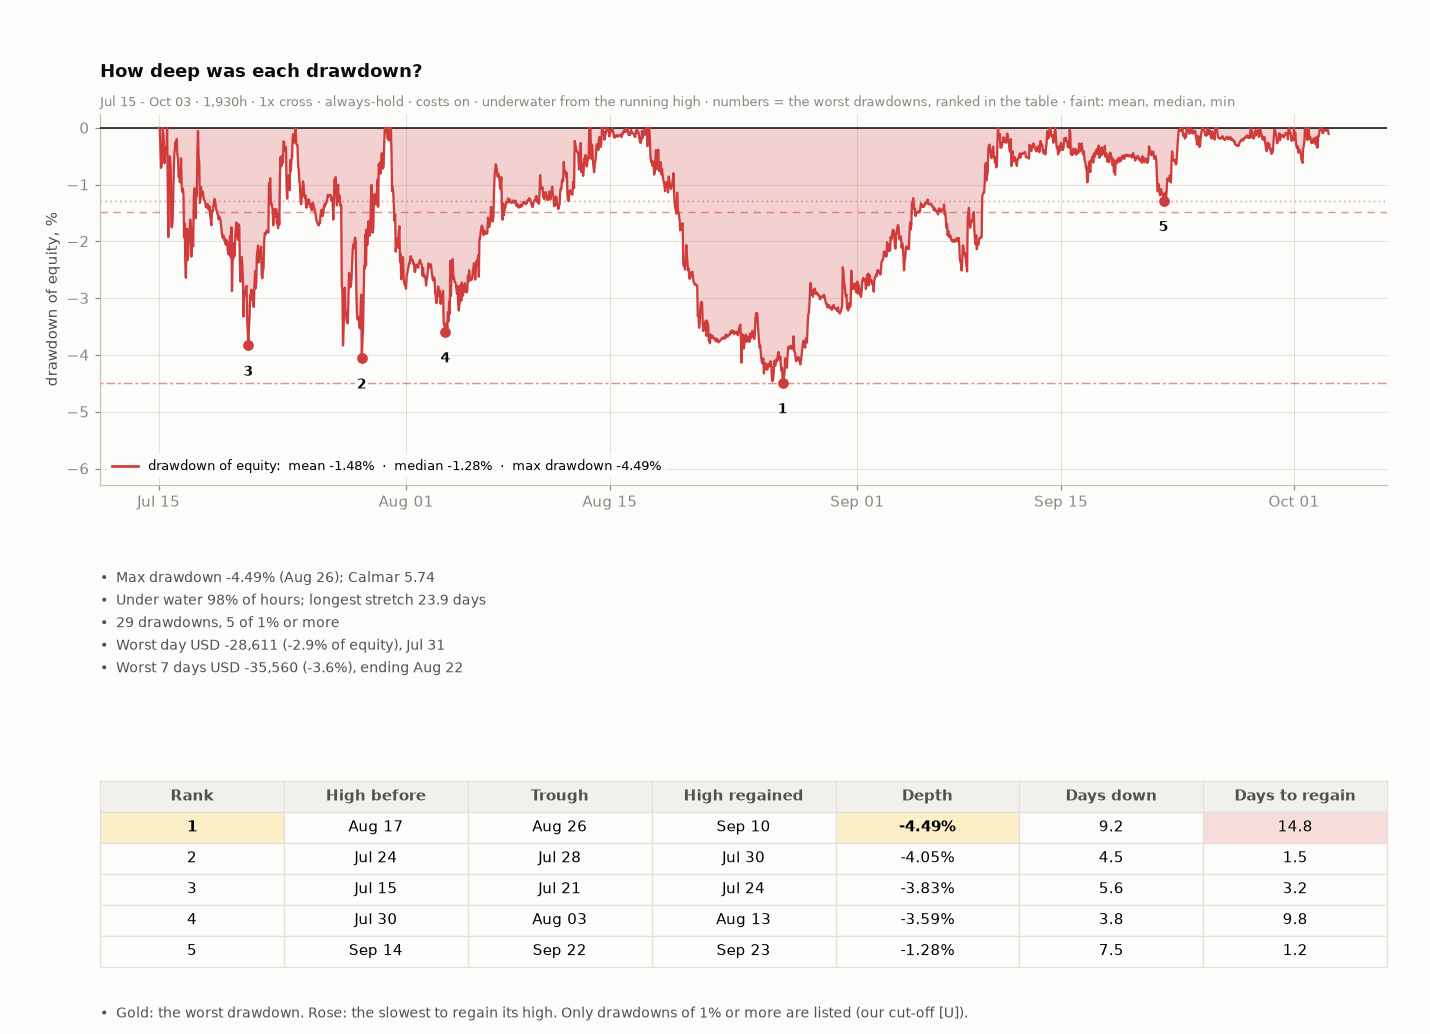

In [17]:
# ---- 3. How deep was each drawdown? the chart, then the statistics in point form, then the worst drawdowns as ONE table inside the figure ----
under = uw < -1e-9
run = (under != under.shift()).cumsum()
longest = int(under.groupby(run).sum().max())
calmar = res["ann_pct"] / 100 / abs(res["max_drawdown"])
wd = DAY["total"].min(); wd_day = DAY["total"].idxmin()
w7 = DAY["total"].rolling(7).sum(); w7min, w7day = w7.min(), w7.idxmin()
H3 = 9.4
fig = plt.figure(figsize=(13, H3))
bm = figstyle.bullets(fig, ["Gold: the worst drawdown. Rose: the slowest to regain its high. Only drawdowns of 1% or more are listed (our cut-off [U])."])
gs = fig.add_gridspec(3, 1, height_ratios=[3.0, 1.0, 1.5], hspace=0.38, left=0.07, right=0.97, top=0.89, bottom=bm + 0.02)
ax, axb, axt = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]), fig.add_subplot(gs[2]); axt.axis("off")
ax.fill_between(df.index, uw, 0, color=CRIT, alpha=0.22, linewidth=0, zorder=2); ax.plot(df.index, uw, color=CRIT, linewidth=1.5, zorder=4)
for k, y in (("mean", uw.mean()), ("median", uw.median()), ("min", uw.min())):
    ax.axhline(y, color=CRIT, linewidth=0.95, linestyle=LS[k], alpha=0.55, zorder=2)
for e in EP:
    ax.plot([e["trough"]], [e["depth"]], "o", color=CRIT, markersize=6, zorder=6)
    ax.annotate(f"{e['rank']}", xy=(e["trough"], e["depth"]), xytext=(0, -13), textcoords="offset points", ha="center", va="top", fontsize=9, color=INK, fontweight="bold",
                bbox=dict(facecolor=SURF, edgecolor="none", pad=1.0), zorder=7)
ax.plot([], [], color=CRIT, linewidth=1.8, label=f"drawdown of equity:  mean {uw.mean():+.2f}%  ·  median {uw.median():+.2f}%  ·  max drawdown {uw.min():+.2f}%")
ax.axhline(0, color=INK, linewidth=1, zorder=3); ax.set_ylabel("drawdown of equity, %"); ax.legend(loc="lower left", fontsize=8.5, **LEG)
ax.set_ylim(uw.min() * 1.4, 0.25); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(ax, "How deep was each drawdown?", f"{WSH} · underwater from the running high · numbers = the worst drawdowns, ranked in the table · faint: mean, median, min")
figstyle.bullets_ax(axb, [f"Max drawdown {uw.min():.2f}% ({uw.idxmin():%b %d}); Calmar {calmar:.2f}",
                          f"Under water {under.mean()*100:.0f}% of hours; longest stretch {longest/24:.1f} days",
                          f"{len(eps)} drawdowns, {len(EP)} of 1% or more",
                          f"Worst day {usd(wd)} ({wd/EQUITY*100:+.1f}% of equity), {wd_day:%b %d}",
                          f"Worst 7 days {usd(w7min)} ({w7min/EQUITY*100:+.1f}%), ending {w7day:%b %d}"])
cells = [[str(e["rank"]), f"{e['peak']:%b %d}", f"{e['trough']:%b %d}", (f"{e['end']:%b %d}" if e["recovered"] else "not yet"), f"{e['depth']:.2f}%", f"{e['days_down']:.1f}", f"{e['days_recover']:.1f}"] for e in EP]
tb = axt.table(cellText=cells, colLabels=["Rank", "High before", "Trough", "High regained", "Depth", "Days down", "Days to regain"], cellLoc="center", loc="center", bbox=[0, 0, 1, 1])
tb.auto_set_font_size(False); tb.set_fontsize(10)
slow = max(range(len(EP)), key=lambda q: EP[q]["days_recover"])
for (r_, c_), cell in tb.get_celld().items():
    cell.set_edgecolor(GRID); cell.set_linewidth(0.8)
    if r_ == 0:
        cell.set_facecolor("#f1f0ea"); cell.set_text_props(weight="bold", color=INK2)
    else:
        cell.set_facecolor(SURF)
        if r_ == 1 and c_ in (0, 4):
            cell.set_facecolor("#fbefc8"); cell.set_text_props(weight="bold")           # the worst drawdown
        if r_ - 1 == slow and c_ == 6:
            cell.set_facecolor("#f7dcdc")                                               # the slowest to regain
figstyle.show(fig, "fig:s3-drawdown", FIGURES)
STATS["drawdown"] = {"mean": float(uw.mean()), "median": float(uw.median()), "min": float(uw.min()), "when": f"{uw.idxmin():%b %d}", "share_under": float(under.mean() * 100), "longest_days": longest / 24,
                     "calmar": float(calmar), "n_eps": len(eps), "n_cut": len(EP), "worst_day": float(wd), "worst_day_pct": float(wd / EQUITY * 100), "worst_7d": float(w7min), "worst_7d_pct": float(w7min / EQUITY * 100),
                     "eps": [{"rank": e["rank"], "peak": f"{e['peak']:%b %d}", "trough": f"{e['trough']:%b %d}", "end": f"{e['end']:%b %d}", "depth": e["depth"], "days_down": e["days_down"], "days_recover": e["days_recover"]} for e in EP]}

In [18]:
from fundplat.quant.core import stats as ST
import numpy as np
_dr = list((DAY["total"] / EQUITY).values)
STATS["risk"] = {"vol": float(np.std(_dr, ddof=1) * np.sqrt(365) * 100), "sharpe": float(ST.sharpe(_dr, 365)), "sortino": float(ST.sortino(_dr, 365)),
                 "calmar": float(res["ann_pct"] / abs(res["max_drawdown"] * 100)), "n_days": len(_dr)}
_cf = pd.Series(res["series"]["cum_funding_net"]).diff().dropna()
STATS["risk"]["pos_funding_hours"] = float((_cf > 0).mean() * 100)

## S4 · Robustness

Is it real: out of sample, statistically significant, after costs? Then: does an exit rule help?

In [19]:
WSH = f"{df.index[0]:%b %d} - {df.index[-1]:%b %d} \u00b7 {len(df):,}h"
WSB = WSH + " \u00b7 1x cross \u00b7 reserve 0 \u00b7 costs on"
TB = figstyle.TABLE
INKc, INK2c = figstyle.NEUTRAL["ink"], figstyle.NEUTRAL["ink2"]




fig_tab, put_table, gold, tint = figstyle.fig_tab, figstyle.put_table, figstyle.gold, figstyle.tint
foot = lambda fig, *lines: figstyle.bullets(fig, [t for t in lines if t])

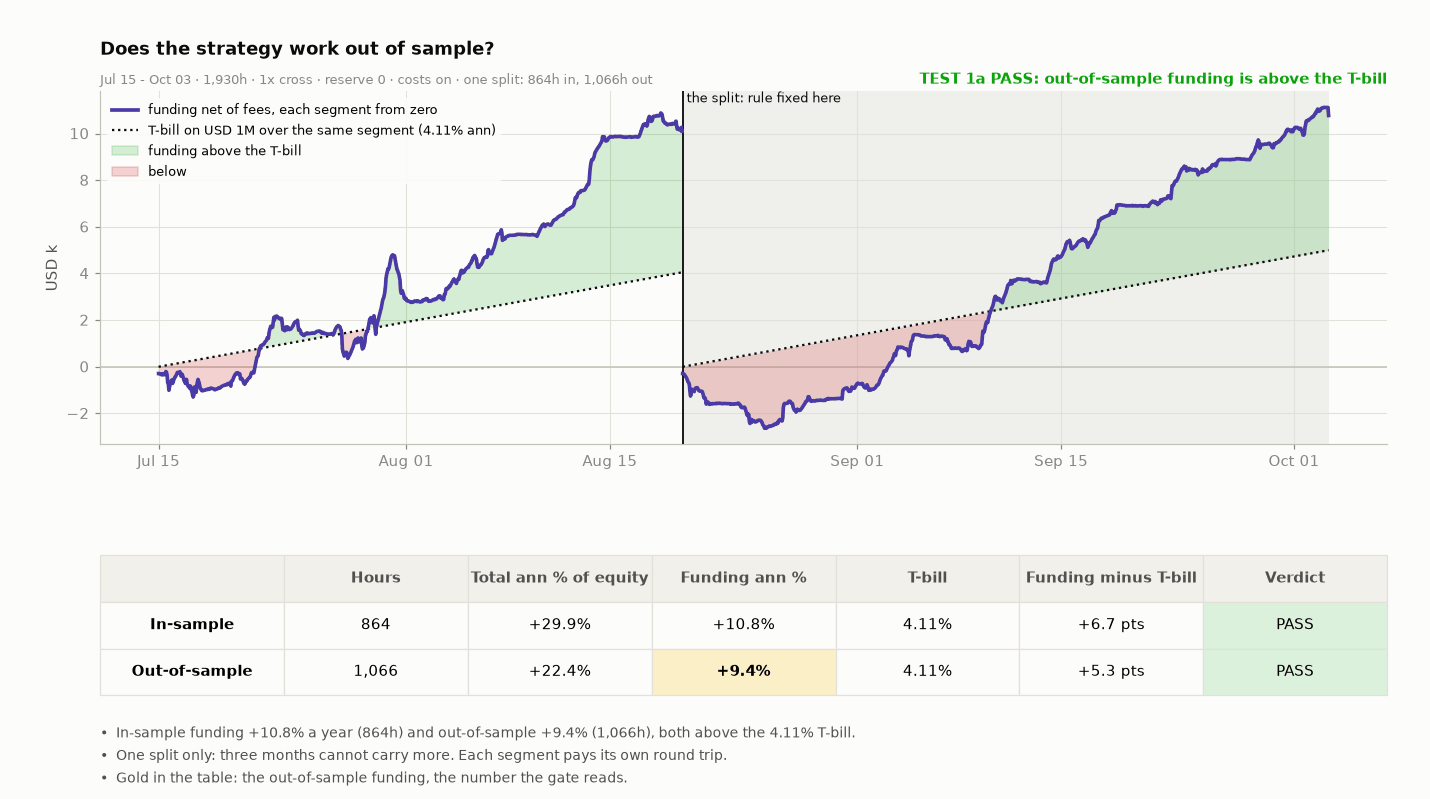

In [20]:
G1a = bool(res["funding_ann_pct_aum"] > HURDLE_PCT)
# ---- 4.1 out of sample ----
rows_in = [r for r in rows if r["time"] < SPLIT]; rows_out = [r for r in rows if r["time"] >= SPLIT]
r_in, r_out = HP.run_pair(rows_in, p1), HP.run_pair(rows_out, p1)
for lab, r_ in (("in-sample", r_in), ("out-of-sample", r_out)):
    assert HP.all_pass(HP.verify_pair(r_)), lab
d_in, d_out = frame(r_in), frame(r_out)
fcum = lambda d: (num(d["cum_funding_net"]) - num(d["cum_fees"]) - num(d["cum_liq_fees"])) / 1e3
tcum = lambda d: EQUITY * p1.hurdle_ann * np.asarray((d.index - d.index[0]).total_seconds()) / (365 * 86400) / 1e3
BUL = [f"In-sample funding {r_in['funding_ann_pct_aum']:+.1f}% a year ({r_in['n_hours']:,}h) and out-of-sample {r_out['funding_ann_pct_aum']:+.1f}% ({r_out['n_hours']:,}h), both above the {HURDLE_PCT:.2f}% T-bill.",
       "One split only: three months cannot carry more. Each segment pays its own round trip.",
       "Gold in the table: the out-of-sample funding, the number the gate reads."]
fig, gs, ax, axt = fig_tab(6.4, (2.9, 1.15), nb=figstyle.nlines(BUL))
split_ts = pd.Timestamp(SPLIT, unit="ms", tz="UTC")
ax.axvspan(split_ts, d_out.index[-1], color=AXIS, alpha=0.22, linewidth=0, zorder=0)
for d, r_, nm in ((d_in, r_in, "in-sample"), (d_out, r_out, "out-of-sample")):
    f_, t_ = fcum(d), pd.Series(tcum(d), index=d.index)
    ax.plot(d.index, f_, color=C_NET, linewidth=2.4, zorder=4)
    ax.plot(d.index, t_, color=INK, linewidth=1.5, linestyle=":", zorder=3)
    ax.fill_between(d.index, f_, t_, where=(f_ >= t_), interpolate=True, color=GOOD, alpha=0.16, linewidth=0, zorder=2)
    ax.fill_between(d.index, f_, t_, where=(f_ < t_), interpolate=True, color=CRIT, alpha=0.22, linewidth=0, zorder=2)
ax.axvline(split_ts, color=INK, linewidth=1.2, zorder=3); ax.text(split_ts, ax.get_ylim()[1], " the split: rule fixed here", color=INK, fontsize=8.5, va="top")
ax.plot([], [], color=C_NET, linewidth=2.4, label="funding net of fees, each segment from zero")
ax.plot([], [], color=INK, linewidth=1.5, linestyle=":", label=f"T-bill on {usdm(EQUITY)} over the same segment ({HURDLE_PCT:.2f}% ann)")
ax.fill_between([], [], color=GOOD, alpha=0.16, label="funding above the T-bill"); ax.fill_between([], [], color=CRIT, alpha=0.22, label="below")
ax.axhline(0, color=AXIS, linewidth=1, zorder=1); ax.set_ylabel("USD k"); ax.legend(loc="upper left", fontsize=8.5, **LEG); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
G2a = bool(r_out["funding_ann_pct_aum"] > HURDLE_PCT)
ax.text(1.0, 1.012, ("TEST 1a PASS: out-of-sample funding is above the T-bill" if G2a else "TEST 1a FAIL"), transform=ax.transAxes, ha="right", va="bottom", color=(GOOD if G2a else CRIT), fontsize=9.5, fontweight="bold")
ask(ax, "Does the strategy work out of sample?", f"{WSB} \u00b7 one split: {r_in['n_hours']:,}h in, {r_out['n_hours']:,}h out")
cells = [[nm, f"{r_['n_hours']:,}", f"{r_['ann_pct']:+.1f}%", f"{r_['funding_ann_pct_aum']:+.1f}%", f"{HURDLE_PCT:.2f}%", f"{r_['funding_ann_pct_aum'] - HURDLE_PCT:+.1f} pts", ("PASS" if r_['funding_ann_pct_aum'] > HURDLE_PCT else "FAIL")]
         for nm, r_ in (("In-sample", r_in), ("Out-of-sample", r_out))]
tb = put_table(axt, cells, ["", "Hours", "Total ann % of equity", "Funding ann %", "T-bill", "Funding minus T-bill", "Verdict"])
gold(tb, 2, 3); tint(tb, 1, 6, "green" if cells[0][6] == "PASS" else "rose"); tint(tb, 2, 6, "green" if cells[1][6] == "PASS" else "rose")
foot(fig, *BUL)
figstyle.show(fig, "fig:s4-oos", FIGURES)
STATS["oos"] = {"in": {"hours": r_in["n_hours"], "ann": r_in["ann_pct"], "fund": r_in["funding_ann_pct_aum"]}, "out": {"hours": r_out["n_hours"], "ann": r_out["ann_pct"], "fund": r_out["funding_ann_pct_aum"]}, "pass": G2a}

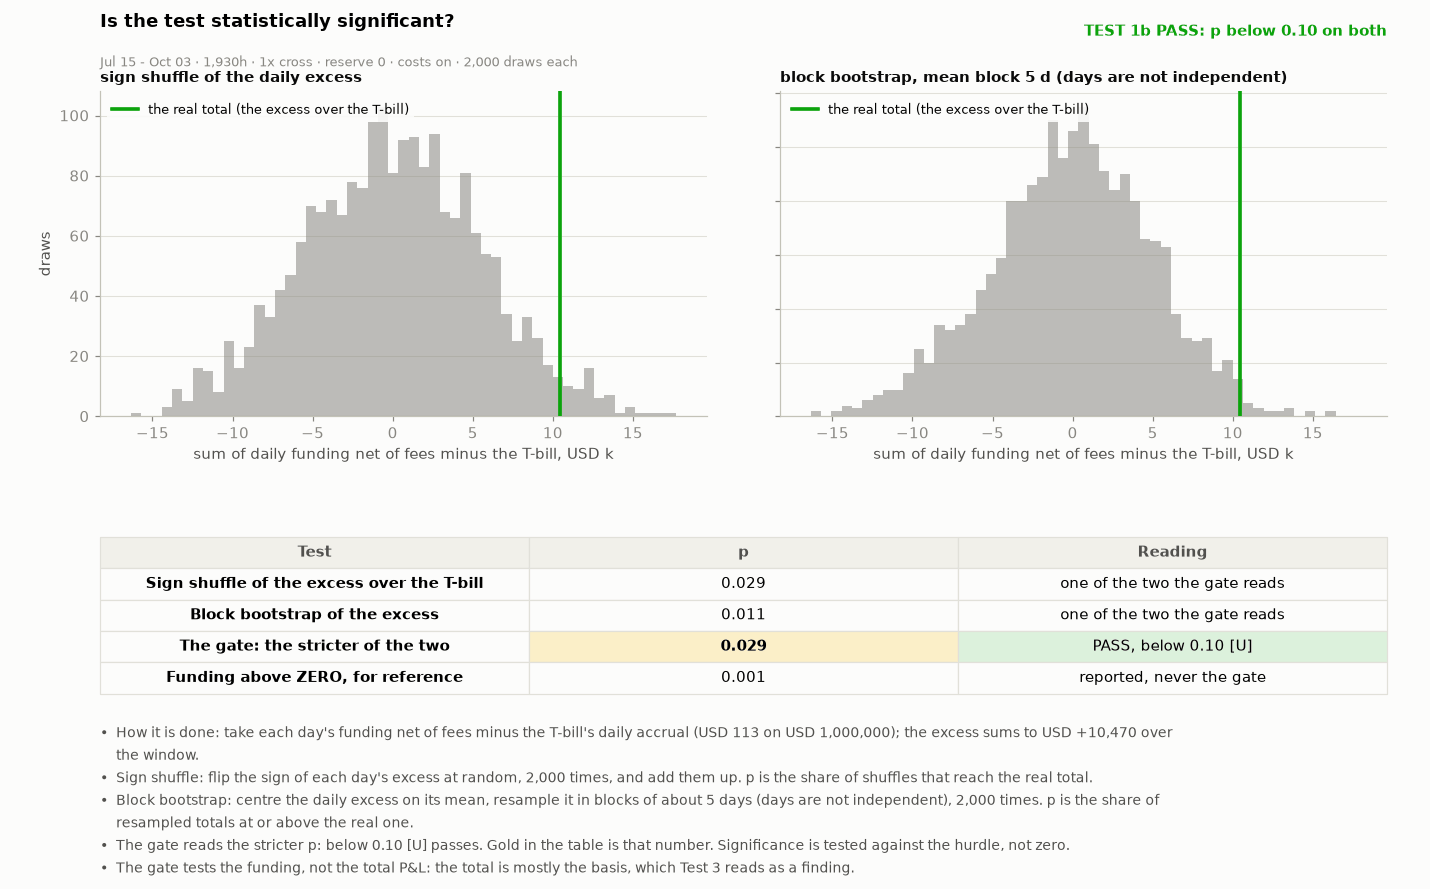

In [21]:
# ---- 4.2 luck, against the hurdle ----
DAY["funding_net_fees"] = DAY["funding"] + DAY["fees"]
HURDLE_DAY = p1.hurdle_ann * EQUITY / 365.0
ex_ = DAY["funding_net_fees"].values - HURDLE_DAY
sh_ = (np.abs(ex_) * np.random.default_rng(SEED + 1).choice([-1.0, 1.0], size=(NSHUF, len(ex_)))).sum(axis=1)
p_sign = float((sh_ >= ex_.sum()).mean())
bt_ = ST.bootstrap_p_one_sided(ex_, BOOT_BLOCK_D, NSHUF, np.random.default_rng(SEED + 2))
v0 = DAY["funding_net_fees"].values
sh0 = (np.abs(v0) * np.random.default_rng(SEED).choice([-1.0, 1.0], size=(NSHUF, len(v0)))).sum(axis=1)
p_zero = float((sh0 >= v0.sum()).mean())
p_gate = max(p_sign, bt_["p"]); G2b = bool(p_gate < 0.10)
BUL = [f"How it is done: take each day's funding net of fees minus the T-bill's daily accrual (USD {HURDLE_DAY:,.0f} on USD {EQUITY:,.0f}); the excess sums to USD {ex_.sum():+,.0f} over the window.",
       f"Sign shuffle: flip the sign of each day's excess at random, {NSHUF:,} times, and add them up. p is the share of shuffles that reach the real total.",
       f"Block bootstrap: centre the daily excess on its mean, resample it in blocks of about {BOOT_BLOCK_D} days (days are not independent), {NSHUF:,} times. p is the share of resampled totals at or above the real one.",
       "The gate reads the stricter p: below 0.10 [U] passes. Gold in the table is that number. Significance is tested against the hurdle, not zero.",
       "The gate tests the funding, not the total P&L: the total is mostly the basis, which Test 3 reads as a finding."]
fig, gs, ax, axt = fig_tab(6.4, (2.7, 1.3), hspace=0.5, nb=figstyle.nlines(BUL))
ax.axis("off"); a1, a2 = fig.add_subplot(gs[0].subgridspec(1, 2, wspace=0.12)[0]), fig.add_subplot(gs[0].subgridspec(1, 2, wspace=0.12)[1])
allv = np.r_[sh_, np.asarray(bt_["sums"]), ex_.sum()] / 1e3; lo_, hi_ = allv.min(), allv.max(); pad = (hi_ - lo_) * 0.06
for a_, null, ttl, p_ in ((a1, sh_ / 1e3, "sign shuffle of the daily excess", p_sign), (a2, np.asarray(bt_["sums"]) / 1e3, f"block bootstrap, mean block {BOOT_BLOCK_D} d (days are not independent)", bt_["p"])):
    a_.hist(null, bins=np.linspace(lo_ - pad, hi_ + pad, 60), color=MUTED, alpha=0.55, zorder=3)
    a_.axvline(ex_.sum() / 1e3, color=GOOD if ex_.sum() > 0 else CRIT, linewidth=2.4, zorder=5, label="the real total (the excess over the T-bill)")
    a_.set_title(ttl, fontsize=10, loc="left", pad=6); a_.set_xlabel("sum of daily funding net of fees minus the T-bill, USD k"); a_.legend(loc="upper left", fontsize=8.5, **LEG); a_.grid(axis="x", visible=False)
    a_.set_xlim(lo_ - pad, hi_ + pad)
a1.set_ylabel("draws"); a2.tick_params(labelleft=False)
a1.text(1.0, 1.16, ("TEST 1b PASS: p below 0.10 on both" if G2b else "TEST 1b FAIL"), transform=a2.transAxes, ha="right", va="bottom", color=(GOOD if G2b else CRIT), fontsize=9.5, fontweight="bold")
fig.suptitle("Is the test statistically significant?", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
fig.text(0.07, 0.925, f"{WSB} \u00b7 {NSHUF:,} draws each", color=MUTED, fontsize=8.5)
cells = [["Sign shuffle of the excess over the T-bill", f"{p_sign:.3f}", "one of the two the gate reads"], ["Block bootstrap of the excess", f"{bt_['p']:.3f}", "one of the two the gate reads"],
         ["The gate: the stricter of the two", f"{p_gate:.3f}", ("PASS, below 0.10 [U]" if G2b else "FAIL, not below 0.10 [U]")], ["Funding above ZERO, for reference", f"{p_zero:.3f}", "reported, never the gate"]]
tb = put_table(axt, cells, ["Test", "p", "Reading"])
gold(tb, 3, 1); tint(tb, 3, 2, "green" if G2b else "rose")
foot(fig, *BUL)
figstyle.show(fig, "fig:s4-significance", FIGURES)
STATS["luck"] = {"p_sign": p_sign, "p_block": float(bt_["p"]), "p_gate": p_gate, "p_zero": p_zero, "excess_usd": float(ex_.sum()), "pass": G2b}

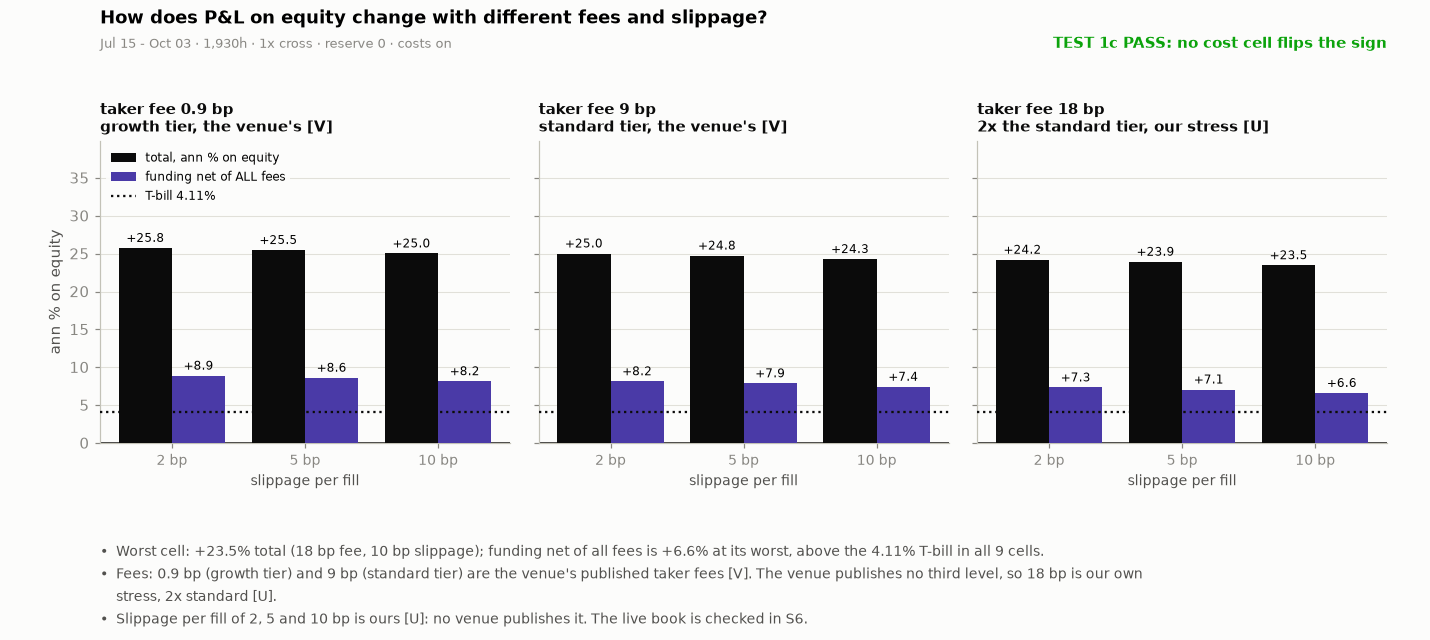

In [22]:
# ---- 4.3 costs: 3 fee levels x 3 slippage levels, three stacked panels ----
FEES = ((refdata.XYZ_TAKER_BPS, "growth tier, the venue's [V]"), (refdata.XYZ_STANDARD_TAKER_BPS, "standard tier, the venue's [V]"), (2 * refdata.XYZ_STANDARD_TAKER_BPS, "2x the standard tier, our stress [U]"))
SLIPS = (2.0, 5.0, 10.0)
SW = {}
for f_, _l in FEES:
    for s_ in SLIPS:
        r_ = HP.run_pair(rows, replace(p1, fee_taker_bps=f_, exec_slippage_bps=s_))
        assert HP.all_pass(HP.verify_pair(r_)), (f_, s_)
        SW[(f_, s_)] = r_
to_ann = 100.0 / EQUITY / res["days"] * 365
TOT = {k: SW[k]["ann_pct"] for k in SW}; FUN = {k: (SW[k]["funding_net"] - SW[k]["fees"] - SW[k]["liq_fees"]) * to_ann for k in SW}
G2c = bool(min(TOT.values()) > 0)
fund_all_above = bool(min(FUN.values()) > HURDLE_PCT)
kw_, kf_ = min(TOT, key=TOT.get), min(FUN, key=FUN.get)
CB = [f"Worst cell: {TOT[kw_]:+.1f}% total ({kw_[0]:g} bp fee, {kw_[1]:g} bp slippage); funding net of all fees is {FUN[kf_]:+.1f}% at its worst, " + ("above" if fund_all_above else "NOT above") + f" the {HURDLE_PCT:.2f}% T-bill in all 9 cells.",
      "Fees: 0.9 bp (growth tier) and 9 bp (standard tier) are the venue's published taker fees [V]. The venue publishes no third level, so 18 bp is our own stress, 2x standard [U].",
      "Slippage per fill of 2, 5 and 10 bp is ours [U]: no venue publishes it. The live book is checked in S6."]
H3x3 = 4.6 + figstyle.nlines(CB) * 0.205 + 0.4
fig, axs = plt.subplots(1, 3, figsize=(13, H3x3), sharey=True)       # side by side: three fee levels across, three slippages in each, so the figure stays short
bm = figstyle.bullets(fig, CB)
for ax_, (f_, lab) in zip(axs, FEES):
    xs = np.arange(len(SLIPS)); vt = [TOT[(f_, s)] for s in SLIPS]; vf = [FUN[(f_, s)] for s in SLIPS]
    b1 = ax_.bar(xs - 0.2, vt, 0.4, color=INKc, zorder=3); b2 = ax_.bar(xs + 0.2, vf, 0.4, color=C_NET, zorder=3)
    ax_.bar_label(b1, fmt="%+.1f", fontsize=8, padding=2); ax_.bar_label(b2, fmt="%+.1f", fontsize=8, padding=2)
    ax_.axhline(HURDLE_PCT, color=INKc, linestyle=":", linewidth=1.5, zorder=4); ax_.axhline(0, color=INKc, linewidth=1)
    ax_.set_xticks(xs); ax_.set_xticklabels([f"{s:g} bp" for s in SLIPS], fontsize=9); ax_.grid(axis="x", visible=False)
    ax_.set_xlabel("slippage per fill", fontsize=9)
    ax_.set_title(f"taker fee {f_:g} bp\n{lab}", fontsize=9.5, loc="left", pad=6)
axs[0].set_ylim(top=max(TOT.values()) * 1.55)
axs[0].set_ylabel("ann % on equity")
axs[0].legend(handles=[Patch(facecolor=INKc, label="total, ann % on equity"), Patch(facecolor=C_NET, label="funding net of ALL fees"), plt.Line2D([], [], color=INKc, linestyle=":", linewidth=1.5, label=f"T-bill {HURDLE_PCT:.2f}%")], loc="upper left", fontsize=8, **LEG)
fig.suptitle("How does P&L on equity change with different fees and slippage?", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
fig.text(0.07, 0.925, f"{WSB}", color=MUTED, fontsize=8.5)
fig.text(0.97, 0.925, ("TEST 1c PASS: no cost cell flips the sign" if G2c else "TEST 1c FAIL"), ha="right", color=(GOOD if G2c else CRIT), fontsize=9.5, fontweight="bold")
plt.subplots_adjust(top=0.78, bottom=bm + 0.75 / H3x3, left=0.07, right=0.97, wspace=0.07)
figstyle.show(fig, "fig:s4-costs", FIGURES)
STATS["costs"] = {"worst_total": min(TOT.values()), "worst_fund": min(FUN.values()), "pass": G2c, "fund_all_above": fund_all_above, "n": len(SW),
                  "cells": [{"fee": f_, "slip": s_, "total": TOT[(f_, s_)], "fund": FUN[(f_, s_)]} for f_, _l in FEES for s_ in SLIPS]}
PASSED = bool(G1a and G2a and G2b and G2c)

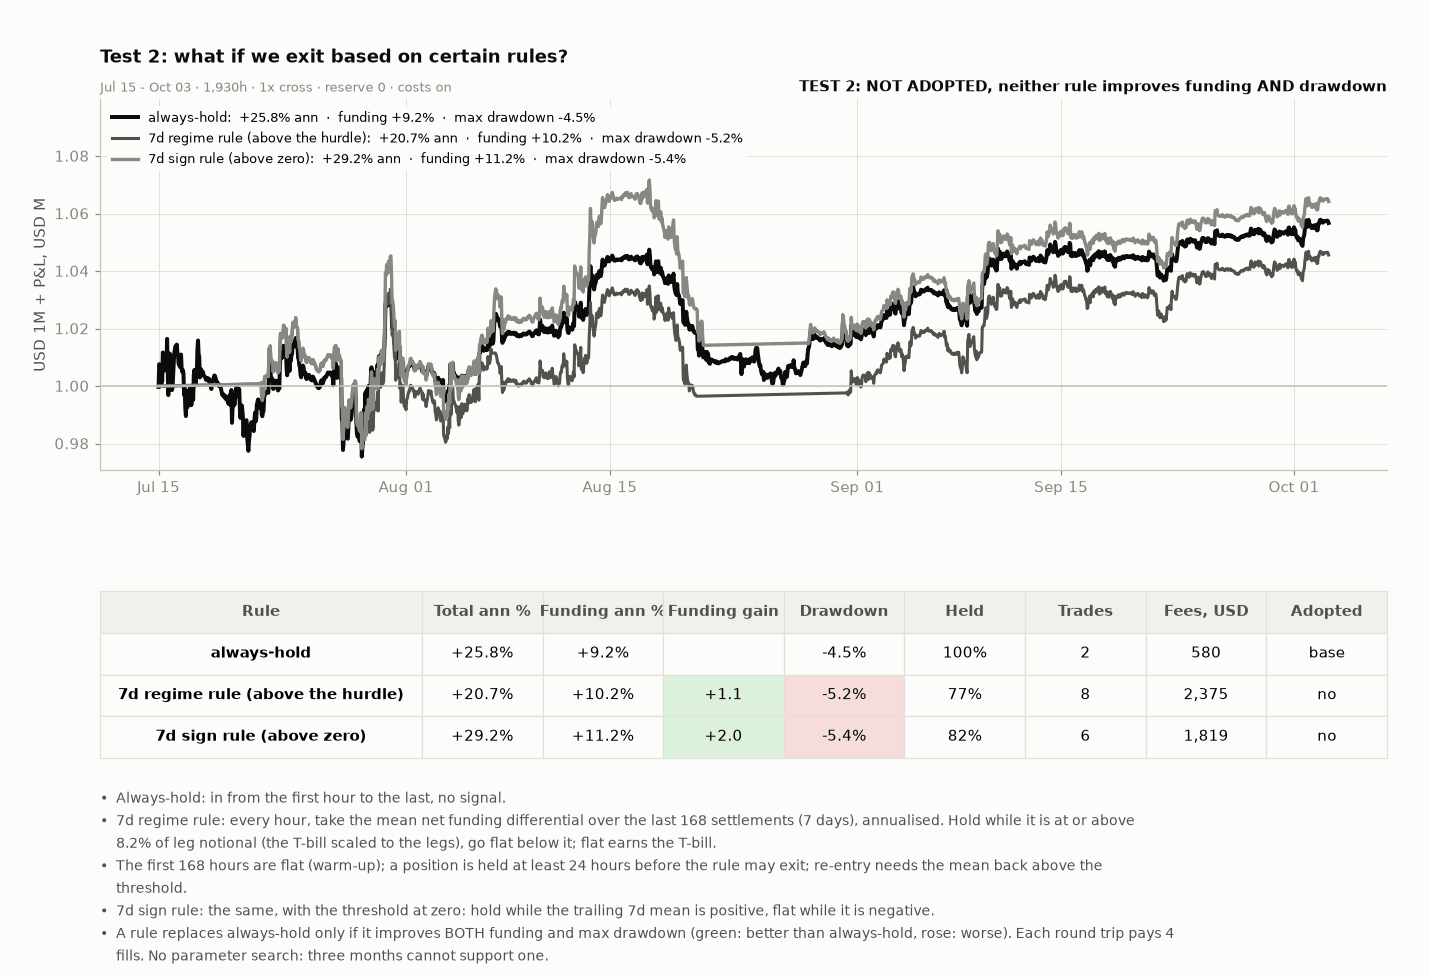

In [23]:
# ---- 4.4 Test 2: a timing rule against always-hold ----
RULES = {"always-hold": res}
for lab, kw in (("7d regime rule (above the hurdle)", dict(regime=True)), ("7d sign rule (above zero)", dict(regime=True, exit_below_ann=0.0))):
    r_ = HP.run_pair(rows, replace(p1, **kw)); assert HP.all_pass(HP.verify_pair(r_)), lab; RULES[lab] = r_
ADOPT = [lab for lab, r_ in RULES.items() if lab != "always-hold" and r_["funding_ann_pct_aum"] > res["funding_ann_pct_aum"] and r_["max_drawdown"] > res["max_drawdown"]]
RULE_USED = ADOPT[0] if ADOPT else "always-hold"
THR = HURDLE_PCT * 2.0 / LEV                         # the T-bill scaled to the legs: 4.11% on the equity = 8.2% of leg notional at 1x
BUL = ["Always-hold: in from the first hour to the last, no signal.",
       f"7d regime rule: every hour, take the mean net funding differential over the last {p1.regime_warmup_h} settlements (7 days), annualised. Hold while it is at or above {THR:.1f}% of leg notional (the T-bill scaled to the legs), go flat below it; flat earns the T-bill.",
       f"The first {p1.regime_warmup_h} hours are flat (warm-up); a position is held at least {p1.min_hold_h} hours before the rule may exit; re-entry needs the mean back above the threshold.",
       "7d sign rule: the same, with the threshold at zero: hold while the trailing 7d mean is positive, flat while it is negative.",
       "A rule replaces always-hold only if it improves BOTH funding and max drawdown (green: better than always-hold, rose: worse). Each round trip pays 4 fills. No parameter search: three months cannot support one."]
fig, gs, ax, axt = fig_tab(7.0, (2.9, 1.3), nb=figstyle.nlines(BUL))
styles ={"always-hold": (INKc, "-", 2.6), "7d regime rule (above the hurdle)": (INK2c, "-", 2.0), "7d sign rule (above zero)": (MUTED, "-", 2.2)}
for lab, r_ in RULES.items():
    d_ = frame(r_); c_, ls_, lw_ = styles[lab]
    ax.plot(d_.index, num(d_["equity_total"]) / 1e6, color=c_, linestyle=ls_, linewidth=lw_, label=f"{lab}:  {r_['ann_pct']:+.1f}% ann  \u00b7  funding {r_['funding_ann_pct_aum']:+.1f}%  \u00b7  max drawdown {r_['max_drawdown']*100:.1f}%")
ax.axhline(1.0, color=AXIS, linewidth=1); ax.set_ylabel("USD 1M + P&L, USD M"); ax.legend(loc="upper left", fontsize=8.5, **LEG); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ylo, yhi = ax.get_ylim(); ax.set_ylim(ylo, yhi + (yhi - ylo) * 0.22)
ax.text(1.0, 1.012, ("TEST 2: a rule is ADOPTED" if ADOPT else "TEST 2: NOT ADOPTED, neither rule improves funding AND drawdown"), transform=ax.transAxes, ha="right", va="bottom", color=INKc, fontsize=9.5, fontweight="bold")
ask(ax, "Test 2: what if we exit based on certain rules?", f"{WSB}")
cells = []
for lab, r_ in RULES.items():
    cells.append([lab, f"{r_['ann_pct']:+.1f}%", f"{r_['funding_ann_pct_aum']:+.1f}%", ("" if lab == "always-hold" else f"{r_['funding_ann_pct_aum'] - res['funding_ann_pct_aum']:+.1f}"), f"{r_['max_drawdown']*100:.1f}%",
                  f"{r_['hold_share']*100:.0f}%", f"{r_['trades']}", f"{r_['fees'] + r_['liq_fees']:,.0f}", ("base" if lab == "always-hold" else ("yes" if lab in ADOPT else "no"))])
tb = put_table(axt, cells, ["Rule", "Total ann %", "Funding ann %", "Funding gain", "Drawdown", "Held", "Trades", "Fees, USD", "Adopted"], size=9.5, first=0.25)
for r_i, (lab, r_) in enumerate(RULES.items(), 1):
    if lab != "always-hold":
        tint(tb, r_i, 4, "rose") if r_["max_drawdown"] <= res["max_drawdown"] else tint(tb, r_i, 4, "green")
        tint(tb, r_i, 3, "green") if r_["funding_ann_pct_aum"] > res["funding_ann_pct_aum"] else tint(tb, r_i, 3, "rose")
foot(fig, *BUL)
figstyle.show(fig, "fig:s4-rules", FIGURES)
STATS["rules"] = {"used": RULE_USED, "adopt": ADOPT, "rows": [{"rule": lab, "ann": r_["ann_pct"], "fund": r_["funding_ann_pct_aum"], "dd": r_["max_drawdown"] * 100, "held": r_["hold_share"] * 100, "trades": r_["trades"]} for lab, r_ in RULES.items()]}

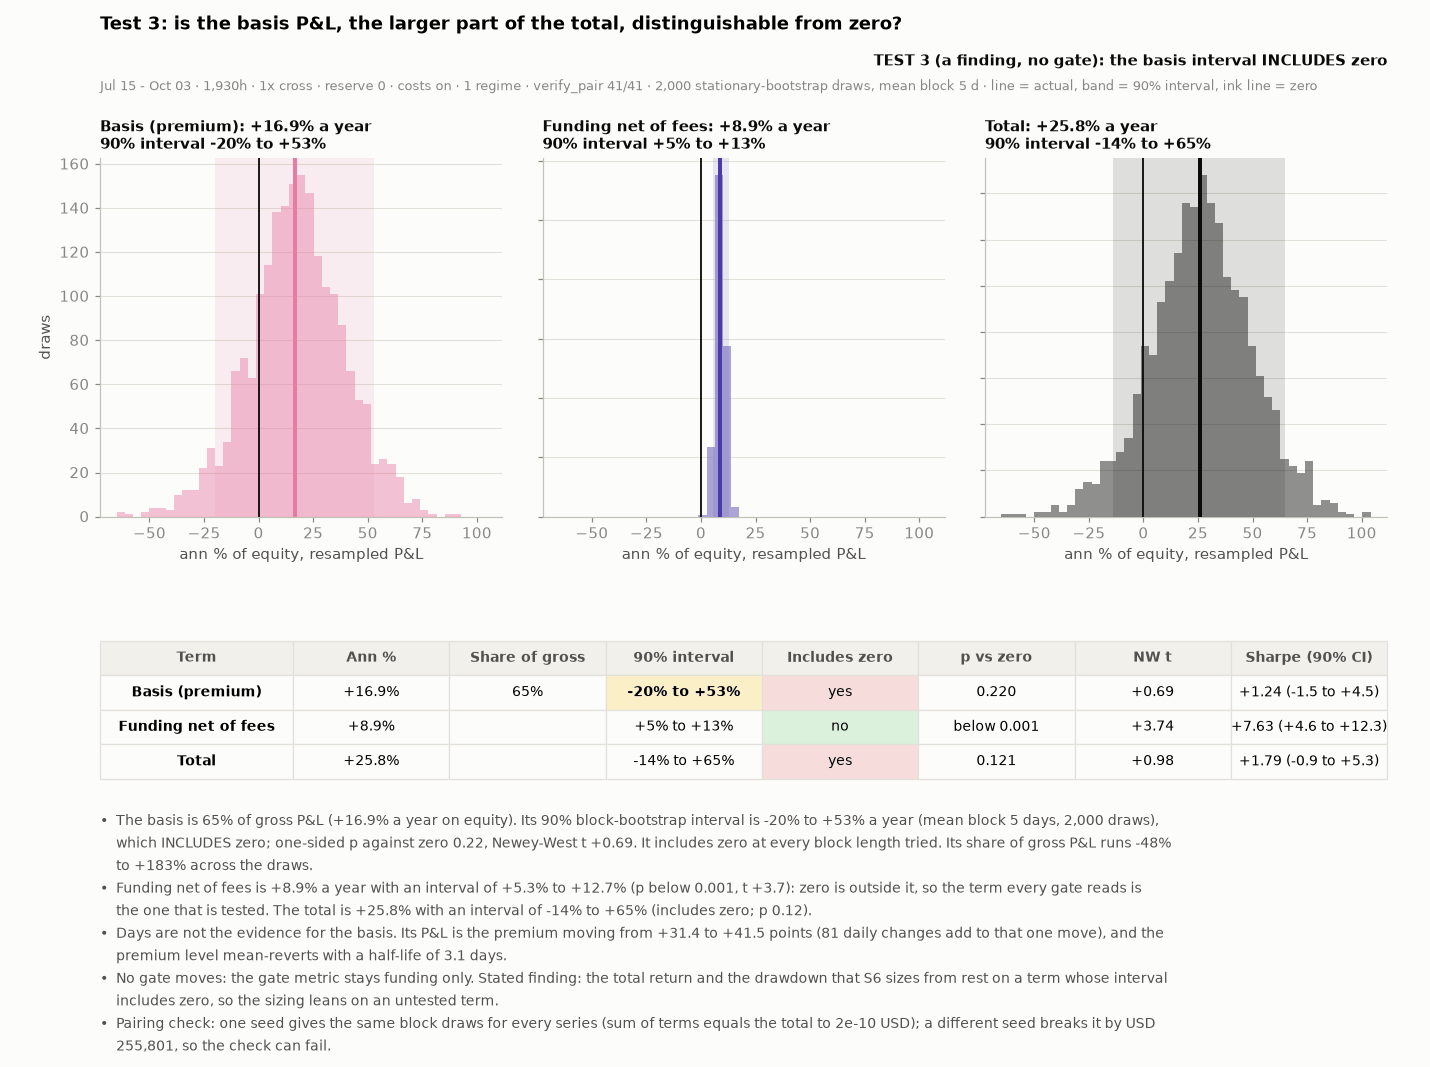

#### Test 3, sensitivity to the block length: 90% interval of the annualised P&L, % of equity

| Mean block, days | 1 | 3 | 5 | 10 | 20 | 40 |
|---|---|---|---|---|---|---|
| Basis (premium) | -30 to +65 | -22 to +58 | -20 to +53 | -15 to +45 | -7 to +40 | -2 to +35 |
| Total | -23 to +76 | -16 to +70 | -14 to +65 | -8 to +56 | +0 to +50 | +5 to +45 |

The interval narrows as the block grows because the circular resample of a series that adds up to one move (the premium's) cannot stray far from that move: a long block is not more information. The headline block is 5 days, the study's own. The total's interval first excludes zero at a mean block of 20 days, where this narrowing is at work. A bootstrap of days cannot say whether the premium drifts; that needs more windows of the premium, not more days in this one.

In [24]:
# ---- 4.6 Test 3: the basis carries most of the P&L and no gate above reads it. A block bootstrap of the daily P&L, term by term: a stated finding, never a gate ----
NBOOT, B_SEED = NSHUF, SEED + 3
Q_LO, Q_HI = (100 - CI_LEVEL) / 2, 100 - (100 - CI_LEVEL) / 2
TERMS = {"Basis (premium)": DAY["premium"].values, "Funding": DAY["funding"].values, "Funding net of fees": DAY["funding_net_fees"].values, "Total": DAY["total"].values}
bs_ = lambda x, B=BOOT_BLOCK_D, seed=B_SEED: np.asarray(ST.stationary_bootstrap_sums(x, B, NBOOT, np.random.default_rng(seed)))
# one seed draws the SAME block indices for every series (they depend on the length only), so the draws are paired across terms and across x and x^2: asserted, then broken on purpose
GAP_OK = float(np.abs(bs_(TERMS["Total"]) - bs_(TERMS["Basis (premium)"]) - bs_(TERMS["Funding net of fees"])).max())
GAP_BAD = float(np.abs(bs_(TERMS["Total"]) - bs_(TERMS["Basis (premium)"], seed=B_SEED + 99) - bs_(TERMS["Funding net of fees"])).max())
assert GAP_OK < 1e-6 and GAP_BAD > 1.0, (GAP_OK, GAP_BAD)
N3 = len(DAY)
T3 = {}
for nm_, x_ in TERMS.items():
    S_ = bs_(x_)
    lo_, hi_ = np.percentile(S_, [Q_LO, Q_HI])
    sr_b = (S_ / N3) / np.sqrt((bs_(x_ ** 2) - S_ ** 2 / N3) / (N3 - 1)) * np.sqrt(365)
    nw_ = ST.newey_west(list(x_))
    T3[nm_] = {"usd": float(x_.sum()), "ann": float(x_.sum() * to_ann), "lo": float(lo_ * to_ann), "hi": float(hi_ * to_ann), "zero_in": bool(lo_ <= 0 <= hi_), "draws": S_ * to_ann,
               "p_zero": float(ST.bootstrap_p_one_sided(x_, BOOT_BLOCK_D, NBOOT, np.random.default_rng(B_SEED + 1))["p"]), "nw_t": float(nw_["t"]),
               "sharpe": float(ST.sharpe(list(x_ / EQUITY), 365)),
               "sr_lo": float(np.percentile(sr_b, Q_LO)), "sr_hi": float(np.percentile(sr_b, Q_HI))}
GROSS = res["funding_net"] + res["premium_pnl"]
T3["Basis (premium)"]["share"], T3["Funding"]["share"] = res["premium_pnl"] / GROSS * 100, res["funding_net"] / GROSS * 100
Sp_, Sf_ = bs_(TERMS["Basis (premium)"]), bs_(TERMS["Funding"])
SHARE = np.percentile(Sp_ / (Sp_ + Sf_) * 100, [Q_LO, 50, Q_HI])
P_BASIS_LE0 = float((Sp_ <= 0).mean())
SENS = {nm_: {B_: [float(v_ * to_ann) for v_ in np.percentile(bs_(TERMS[nm_], B=B_), [Q_LO, Q_HI])] for B_ in BLOCKS_D} for nm_ in ("Basis (premium)", "Total")}
ZERO_ALL = all(lo_ <= 0 <= hi_ for lo_, hi_ in SENS["Basis (premium)"].values())
FIRST_EXCL = next((b_ for b_ in BLOCKS_D if not SENS["Total"][b_][0] <= 0 <= SENS["Total"][b_][1]), None)
# the basis P&L is the move of the premium level from entry to exit times the per-leg notional: asserted, because the telescoping is the reason the days are not independent evidence
tele = res["premium_pnl"] / (EQUITY / 2.0); dlog = float(np.log((1 + prem.iloc[-1] / 100) / (1 + P0 / 100)))
assert abs(tele - dlog) / abs(tele) < 0.02, (tele, dlog)
AR = ST.ar1_fit(list(prem.values)); HALF_D = AR["half_life"] / 24.0
B3, F3, T3t = T3["Basis (premium)"], T3["Funding net of fees"], T3["Total"]
pfmt_ = lambda p_: "below 0.001" if p_ < 0.0005 else f"{p_:.3f}"          # a bootstrap p of 0 in 2,000 draws is a bound, not a zero
BUL = [f"The basis is {B3['share']:.0f}% of gross P&L ({B3['ann']:+.1f}% a year on equity). Its {CI_LEVEL}% block-bootstrap interval is {B3['lo']:+.0f}% to {B3['hi']:+.0f}% a year (mean block {BOOT_BLOCK_D} days, {NBOOT:,} draws), which " + ("INCLUDES zero" if B3["zero_in"] else "excludes zero") + f"; one-sided p against zero {B3['p_zero']:.2f}, Newey-West t {B3['nw_t']:+.2f}. " + ("It includes zero at every block length tried." if ZERO_ALL else "It does not include zero at every block length tried.") + f" Its share of gross P&L runs {SHARE[0]:+.0f}% to {SHARE[2]:+.0f}% across the draws.",
       f"Funding net of fees is {F3['ann']:+.1f}% a year with an interval of {F3['lo']:+.1f}% to {F3['hi']:+.1f}% (p {pfmt_(F3['p_zero'])}, t {F3['nw_t']:+.1f}): " + ("zero is outside it, so the term every gate reads is the one that is tested." if not F3["zero_in"] else "zero is inside it.") + f" The total is {T3t['ann']:+.1f}% with an interval of {T3t['lo']:+.0f}% to {T3t['hi']:+.0f}% (" + ("includes zero" if T3t["zero_in"] else "excludes zero") + f"; p {T3t['p_zero']:.2f}).",
       f"Days are not the evidence for the basis. Its P&L is the premium moving from {P0:+.1f} to {prem.iloc[-1]:+.1f} points ({N3} daily changes add to that one move), and the premium level mean-reverts with a half-life of {HALF_D:.1f} days.",
       "No gate moves: the gate metric stays funding only. Stated finding: " + ("the total return and the drawdown that S6 sizes from rest on a term whose interval includes zero, so the sizing leans on an untested term." if B3["zero_in"] else "the basis interval excludes zero at the study's block length."),
       f"Pairing check: one seed gives the same block draws for every series (sum of terms equals the total to {GAP_OK:.0e} USD); a different seed breaks it by USD {GAP_BAD:,.0f}, so the check can fail."]
fig, gs, ax, axt = fig_tab(7.2, (2.6, 1.0), top=0.80, hspace=0.5, nb=figstyle.nlines(BUL))
ax.axis("off"); sg_ = gs[0].subgridspec(1, 3, wspace=0.10); axs3 = [fig.add_subplot(sg_[i]) for i in range(3)]
allv_ = np.concatenate([T3[k_]["draws"] for k_ in ("Basis (premium)", "Funding net of fees", "Total")]); lo3, hi3 = allv_.min(), allv_.max(); pad3 = (hi3 - lo3) * 0.05
for a_, nm_, col_ in zip(axs3, ("Basis (premium)", "Funding net of fees", "Total"), (C_PREM, C_NET, INK)):
    t_ = T3[nm_]
    a_.hist(t_["draws"], bins=np.linspace(lo3 - pad3, hi3 + pad3, 50), color=col_, alpha=0.45, zorder=3)
    a_.axvspan(t_["lo"], t_["hi"], color=col_, alpha=0.12, linewidth=0, zorder=1)
    a_.axvline(0, color=INK, linewidth=1.2, zorder=4); a_.axvline(t_["ann"], color=col_, linewidth=2.6, zorder=5)
    a_.set_title(f"{nm_}: {t_['ann']:+.1f}% a year\n{CI_LEVEL}% interval {t_['lo']:+.0f}% to {t_['hi']:+.0f}%", fontsize=9.5, loc="left", pad=6)
    a_.set_xlabel("ann % of equity, resampled P&L"); a_.set_xlim(lo3 - pad3, hi3 + pad3); a_.grid(axis="x", visible=False)
    if a_ is not axs3[0]:
        a_.tick_params(labelleft=False)
axs3[0].set_ylabel("draws")
fig.text(0.97, 0.935, ("TEST 3 (a finding, no gate): the basis interval INCLUDES zero" if B3["zero_in"] else "TEST 3 (a finding, no gate): the basis interval excludes zero"), ha="right", va="bottom", color=INKc, fontsize=9.5, fontweight="bold")
fig.suptitle("Test 3: is the basis P&L, the larger part of the total, distinguishable from zero?", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
fig.text(0.07, 0.915, f"{WSB} · 1 regime · verify_pair {NCHK}/{NCHK} · {NBOOT:,} stationary-bootstrap draws, mean block {BOOT_BLOCK_D} d · line = actual, band = {CI_LEVEL}% interval, ink line = zero", color=MUTED, fontsize=8.5)
cells = [[nm_, f"{T3[nm_]['ann']:+.1f}%", ("" if "share" not in T3[nm_] else f"{T3[nm_]['share']:.0f}%"), f"{T3[nm_]['lo']:+.0f}% to {T3[nm_]['hi']:+.0f}%", ("yes" if T3[nm_]["zero_in"] else "no"), pfmt_(T3[nm_]['p_zero']), f"{T3[nm_]['nw_t']:+.2f}",
          f"{T3[nm_]['sharpe']:+.2f} ({T3[nm_]['sr_lo']:+.1f} to {T3[nm_]['sr_hi']:+.1f})"] for nm_ in ("Basis (premium)", "Funding net of fees", "Total")]
tb = put_table(axt, cells, ["Term", "Ann %", "Share of gross", f"{CI_LEVEL}% interval", "Includes zero", "p vs zero", "NW t", f"Sharpe ({CI_LEVEL}% CI)"], size=9, first=0.15)
gold(tb, 1, 3); tint(tb, 1, 4, "rose" if B3["zero_in"] else "green"); tint(tb, 2, 4, "rose" if F3["zero_in"] else "green"); tint(tb, 3, 4, "rose" if T3t["zero_in"] else "green")
foot(fig, *BUL)
figstyle.show(fig, "fig:s4-basis-test", FIGURES)
display(Markdown(
    f"#### Test 3, sensitivity to the block length: {CI_LEVEL}% interval of the annualised P&L, % of equity\n\n"
    "| Mean block, days | " + " | ".join(str(b_) for b_ in BLOCKS_D) + " |\n|---|" + "---|" * len(BLOCKS_D) + "\n" +
    "\n".join(f"| {nm_} | " + " | ".join(f"{SENS[nm_][b_][0]:+.0f} to {SENS[nm_][b_][1]:+.0f}" for b_ in BLOCKS_D) + " |" for nm_ in SENS) + "\n\n"
    f"The interval narrows as the block grows because the circular resample of a series that adds up to one move (the premium's) cannot stray far from that move: a long block is not more information. The headline block is {BOOT_BLOCK_D} days, the study's own. "
    + (f"The total's interval first excludes zero at a mean block of {FIRST_EXCL} days, where this narrowing is at work. " if FIRST_EXCL else "The total's interval includes zero at every block length tried. ")
    + "A bootstrap of days cannot say whether the premium drifts; that needs more windows of the premium, not more days in this one."))
STATS["basis_test"] = {"terms": {k_: {kk_: vv_ for kk_, vv_ in v_.items() if kk_ != "draws"} for k_, v_ in T3.items()}, "share_ci": [float(v_) for v_ in SHARE], "p_basis_le0": P_BASIS_LE0, "sens": SENS, "zero_all": ZERO_ALL, "block": BOOT_BLOCK_D,
                       "ci_level": CI_LEVEL, "n": N3, "half_life_d": float(HALF_D), "p0": float(P0), "p_end": float(prem.iloc[-1]), "gap_ok": GAP_OK, "gap_bad": GAP_BAD}

## S5 · Risk and diagnostics

How does the hedge behave, and what moves: the premium basis (the listing basis) or the perp basis?

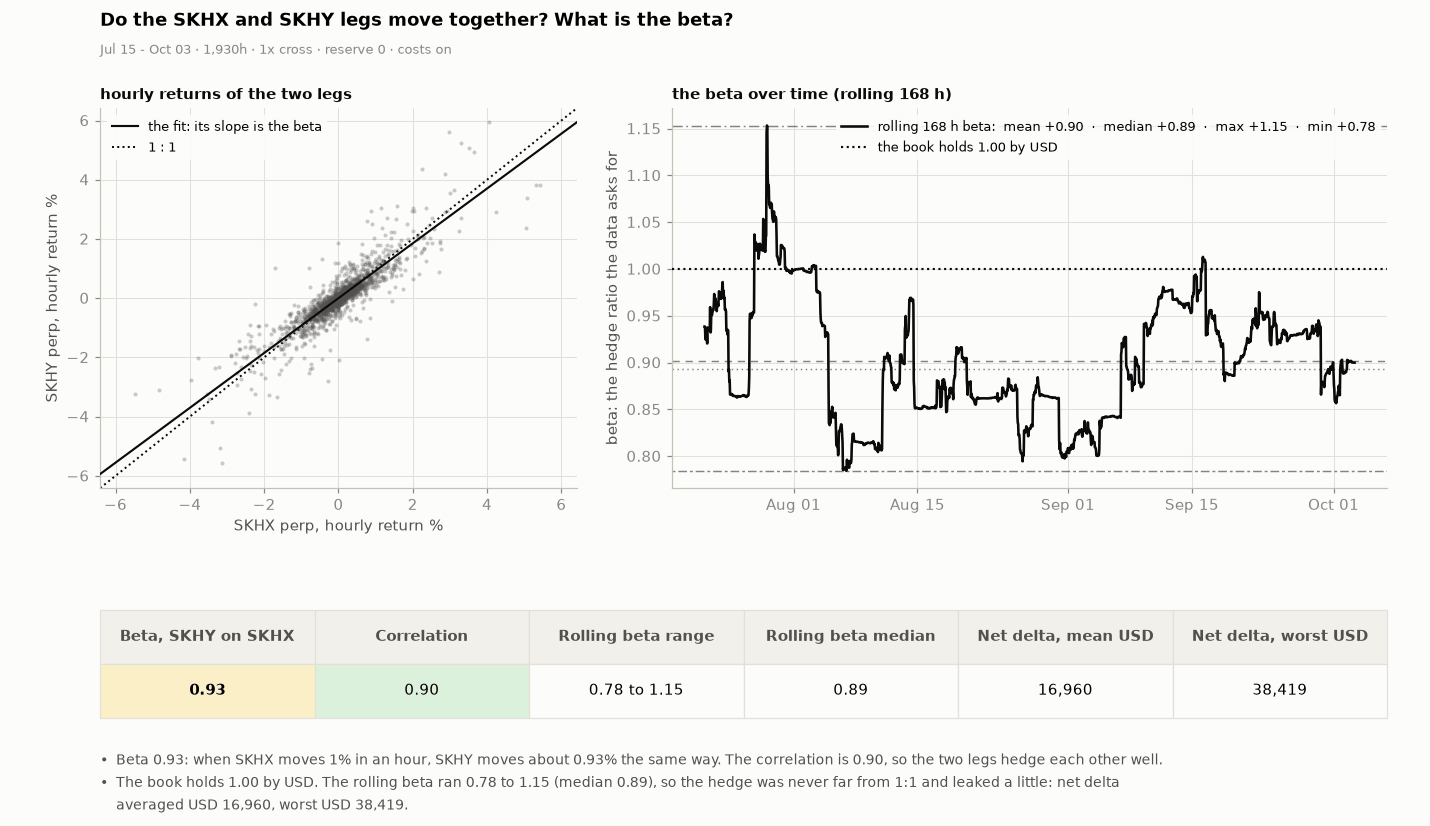

In [25]:
# ---- hedge
rt_ = pd.to_datetime([r["time"] for r in rows], unit="ms", utc=True)
lrA = np.log(pd.Series([r["A_perp"] for r in rows], index=rt_)).diff(); lrB = np.log(pd.Series([r["B_perp"] for r in rows], index=rt_)).diff()
ok_ = lrA.notna() & lrB.notna()
beta_all = float(np.polyfit(lrA[ok_], lrB[ok_], 1)[0]); corr_all = float(lrA[ok_].corr(lrB[ok_]))
hr_ = pd.Series(ST.rolling_slope(list(lrB.fillna(0.0)), list(lrA.fillna(0.0)), HEDGE_WIN_H), index=rt_).dropna()
nd_ = pd.Series(res["series"]["net_delta_usd"]).abs()
HB = [f"Beta {beta_all:.2f}: when SKHX moves 1% in an hour, SKHY moves about {beta_all:.2f}% the same way. The correlation is {corr_all:.2f}, so the two legs hedge each other well.",
      f"The book holds 1.00 by USD. The rolling beta ran {hr_.min():.2f} to {hr_.max():.2f} (median {hr_.median():.2f}), so the hedge was never far from 1:1 and leaked a little: net delta averaged USD {nd_.mean():,.0f}, worst USD {nd_.max():,.0f}."]
HH = 6.6 + figstyle.nlines(HB) * 0.205 + 0.3
fig = plt.figure(figsize=(13, HH))
bm = figstyle.bullets(fig, HB)
gs = fig.add_gridspec(2, 2, height_ratios=[3.0, 0.85], width_ratios=[1, 1.5], hspace=0.5, wspace=0.16, left=0.07, right=0.97, top=1 - 0.15 * 6.6 / HH, bottom=bm + 0.02)
h0, h1 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]); axt = fig.add_subplot(gs[1, :]); axt.axis("off")
lim_ = float(np.nanpercentile(np.abs(np.r_[lrA[ok_], lrB[ok_]]) * 100, 99.7)); xx_ = np.array([-lim_, lim_])
h0.scatter(lrA[ok_] * 100, lrB[ok_] * 100, s=7, color=INK2c, alpha=0.3, linewidths=0, zorder=3)
h0.plot(xx_, beta_all * xx_, color=INKc, linewidth=1.4, zorder=4, label=f"the fit: its slope is the beta"); h0.plot(xx_, xx_, color=INKc, linewidth=1.3, linestyle=":", zorder=2, label="1 : 1")
h0.set_xlim(-lim_, lim_); h0.set_ylim(-lim_, lim_); h0.set_xlabel("SKHX perp, hourly return %"); h0.set_ylabel("SKHY perp, hourly return %"); h0.legend(loc="upper left", fontsize=8.5, **LEG)
h0.set_title("hourly returns of the two legs", fontsize=10, loc="left", pad=6)
h1.plot(hr_.index, hr_, color=INKc, linewidth=1.7, zorder=4); v_h = figstyle.stat_lines(h1, hr_, INKc, with_min=True)
h1.axhline(1.0, color=INKc, linestyle=":", linewidth=1.4, zorder=3)
h1.plot([], [], color=INKc, linewidth=1.7, label=figstyle.tag(f"rolling {HEDGE_WIN_H} h beta", v_h, 2)); h1.plot([], [], color=INKc, linestyle=":", linewidth=1.4, label="the book holds 1.00 by USD")
h1.set_ylabel("beta: the hedge ratio the data asks for"); h1.legend(loc="upper right", fontsize=8.5, **LEG); h1.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
h1.set_title(f"the beta over time (rolling {HEDGE_WIN_H} h)", fontsize=10, loc="left", pad=6)
fig.suptitle("Do the SKHX and SKHY legs move together? What is the beta?", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
fig.text(0.07, 1 - 0.075 * 6.6 / HH, f"{WSB}", color=MUTED, fontsize=8.5)
cells = [[f"{beta_all:.2f}", f"{corr_all:.2f}", f"{hr_.min():.2f} to {hr_.max():.2f}", f"{hr_.median():.2f}", f"{nd_.mean():,.0f}", f"{nd_.max():,.0f}"]]
tb = axt.table(cellText=cells, colLabels=["Beta, SKHY on SKHX", "Correlation", "Rolling beta range", "Rolling beta median", "Net delta, mean USD", "Net delta, worst USD"], cellLoc="center", loc="center", bbox=[0, 0, 1, 1]); tb.set_fontsize(10); figstyle.style_table(tb)
gold(tb, 1, 0)
tint(tb, 1, 1, "green") if corr_all >= 0.8 else None
figstyle.show(fig, "fig:s5-hedge", FIGURES)
STATS["hedge"] = {"beta": beta_all, "corr": corr_all, "hr_min": float(hr_.min()), "hr_max": float(hr_.max()), "hr_median": float(hr_.median()), "nd_mean": float(nd_.mean()), "nd_max": float(nd_.max())}

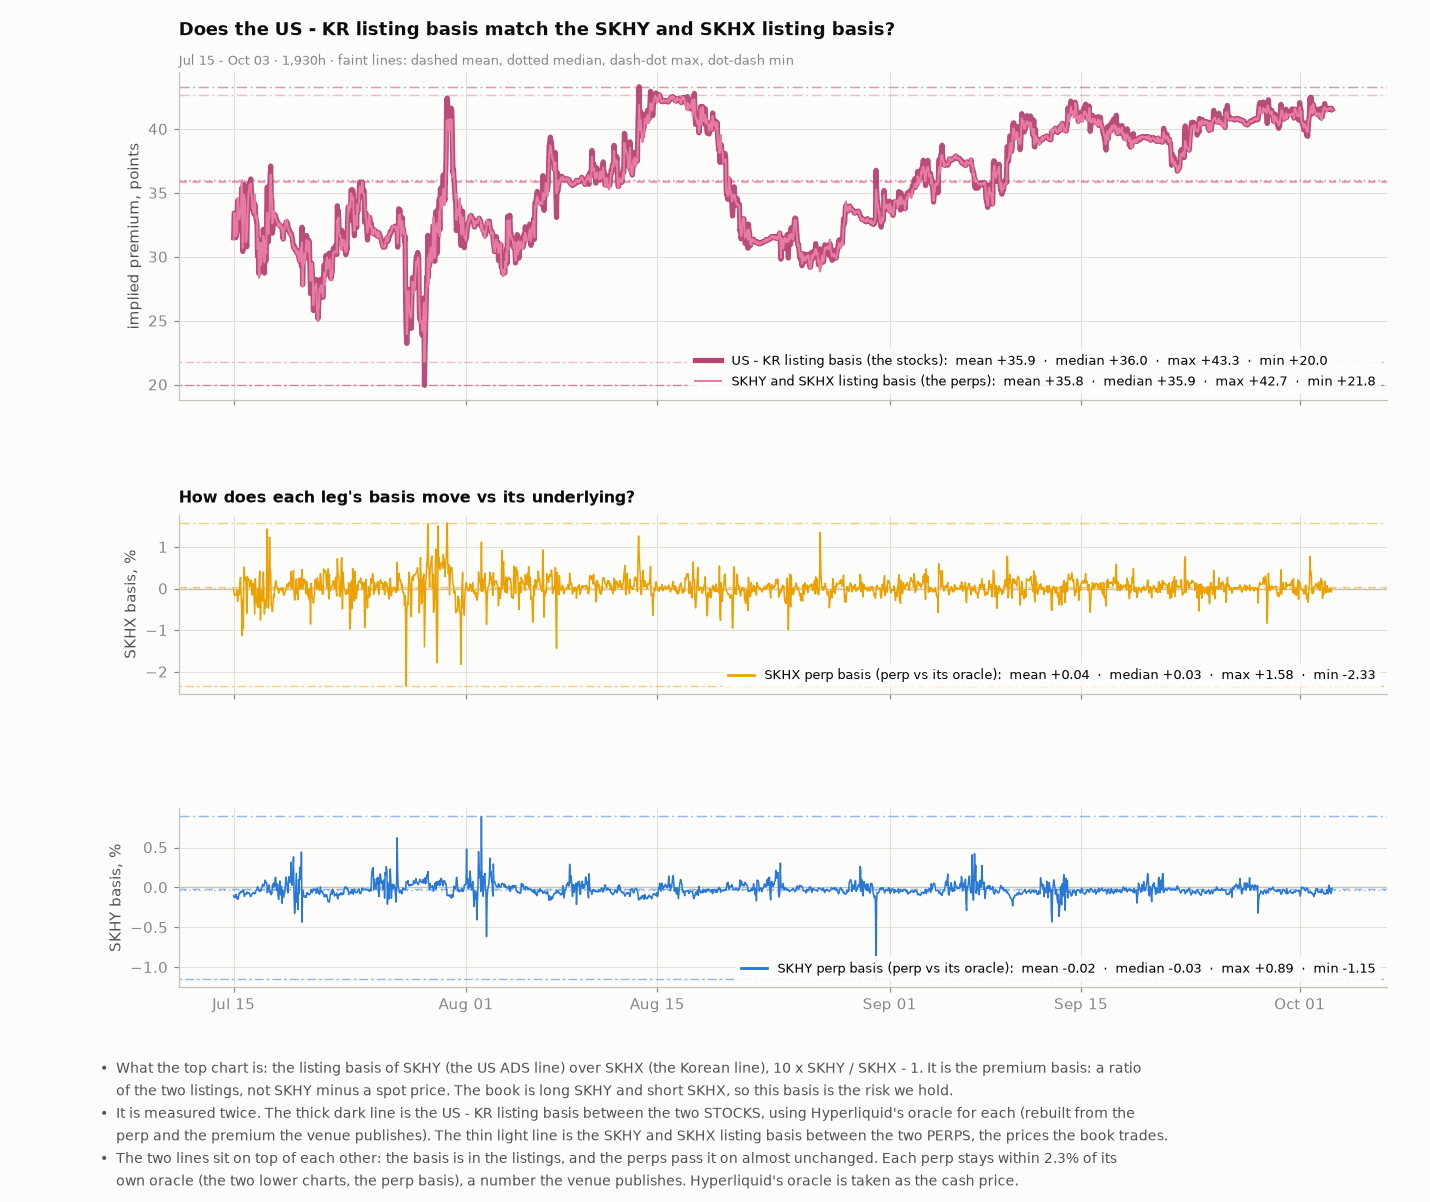

In [26]:
P_perp = pd.Series([(10 * r["B_perp"] / r["A_perp"] - 1) * 100 for r in rows], index=rt_); P_orc = pd.Series([(10 * r["B_oracle"] / r["A_oracle"] - 1) * 100 for r in rows], index=rt_)
bA_ = pd.Series([r["A_premium"] * 100 for r in rows], index=rt_); bB_ = pd.Series([r["B_premium"] * 100 for r in rows], index=rt_)
ID_RES = float(((1 + P_perp / 100) - (1 + P_orc / 100) * (1 + bB_ / 100) / (1 + bA_ / 100)).abs().max()); assert ID_RES < 1e-6, ID_RES
NP, NO = "SKHY and SKHX listing basis (the perps)", "US - KR listing basis (the stocks)"
bmax = max(abs(bA_.min()), abs(bA_.max()), abs(bB_.min()), abs(bB_.max()))
SB = ["What the top chart is: the listing basis of SKHY (the US ADS line) over SKHX (the Korean line), 10 x SKHY / SKHX - 1. It is the premium basis: a ratio of the two listings, not SKHY minus a spot price. The book is long SKHY and short SKHX, so this basis is the risk we hold.",
      "It is measured twice. The thick dark line is the US - KR listing basis between the two STOCKS, using Hyperliquid's oracle for each (rebuilt from the perp and the premium the venue publishes). The thin light line is the SKHY and SKHX listing basis between the two PERPS, the prices the book trades.",
      f"The two lines sit on top of each other: the basis is in the listings, and the perps pass it on almost unchanged. Each perp stays within {bmax:.1f}% of its own oracle (the two lower charts, the perp basis), a number the venue publishes. Hyperliquid's oracle is taken as the cash price."]
HS = 9.4 + figstyle.nlines(SB) * 0.205 + 0.3
fig, (c0, c1, c2) = plt.subplots(3, 1, figsize=(13, HS), sharex=True, gridspec_kw={"height_ratios": [2.2, 1.2, 1.2]})
c0.plot(P_orc.index, P_orc, color=C_PREM_DK, linewidth=3.4, zorder=3, alpha=0.9); c0.plot(P_perp.index, P_perp, color=C_PREM, linewidth=1.3, zorder=4)
vp2, vp1 = figstyle.stat_lines(c0, P_orc, C_PREM_DK, with_min=True), figstyle.stat_lines(c0, P_perp, C_PREM, with_min=True)
c0.plot([], [], color=C_PREM_DK, linewidth=3.4, label=figstyle.tag(NO, vp2, 1)); c0.plot([], [], color=C_PREM, linewidth=1.3, label=figstyle.tag(NP, vp1, 1))
c0.set_ylabel("implied premium, points"); c0.legend(loc="lower right", fontsize=8.5, **LEG)
ask(c0, "Does the US - KR listing basis match the SKHY and SKHX listing basis?", f"{WSH} · faint lines: dashed mean, dotted median, dash-dot max, dot-dash min")
c1.plot(bA_.index, bA_, color=C_A, linewidth=1.0, zorder=4)
vba = figstyle.stat_lines(c1, bA_, C_A, with_min=True)
c1.plot([], [], color=C_A, linewidth=1.8, label=figstyle.tag("SKHX perp basis (perp vs its oracle)", vba, 2))
c1.axhline(0, color=AXIS, linewidth=0.9); c1.set_ylabel("SKHX basis, %"); c1.legend(loc="lower right", fontsize=8.5, **LEG)
c1.set_title("How does each leg's basis move vs its underlying?", fontsize=10.5, loc="left", pad=8, fontweight="bold")
c2.plot(bB_.index, bB_, color=C_B, linewidth=1.0, zorder=4)
vbb = figstyle.stat_lines(c2, bB_, C_B, with_min=True)
c2.plot([], [], color=C_B, linewidth=1.8, label=figstyle.tag("SKHY perp basis (perp vs its oracle)", vbb, 2))
c2.axhline(0, color=AXIS, linewidth=0.9); c2.set_ylabel("SKHY basis, %"); c2.legend(loc="lower right", fontsize=8.5, **LEG); c2.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
bm = figstyle.bullets(fig, SB)
plt.subplots_adjust(hspace=0.5, right=0.97, top=0.94, bottom=bm + 0.5 / HS)
figstyle.show(fig, "fig:s5-basis-sources", FIGURES)
STATS["basis_sources"] = {"id_res": ID_RES, "perp": vp1, "oracle": vp2, "A": vba, "B": vbb}

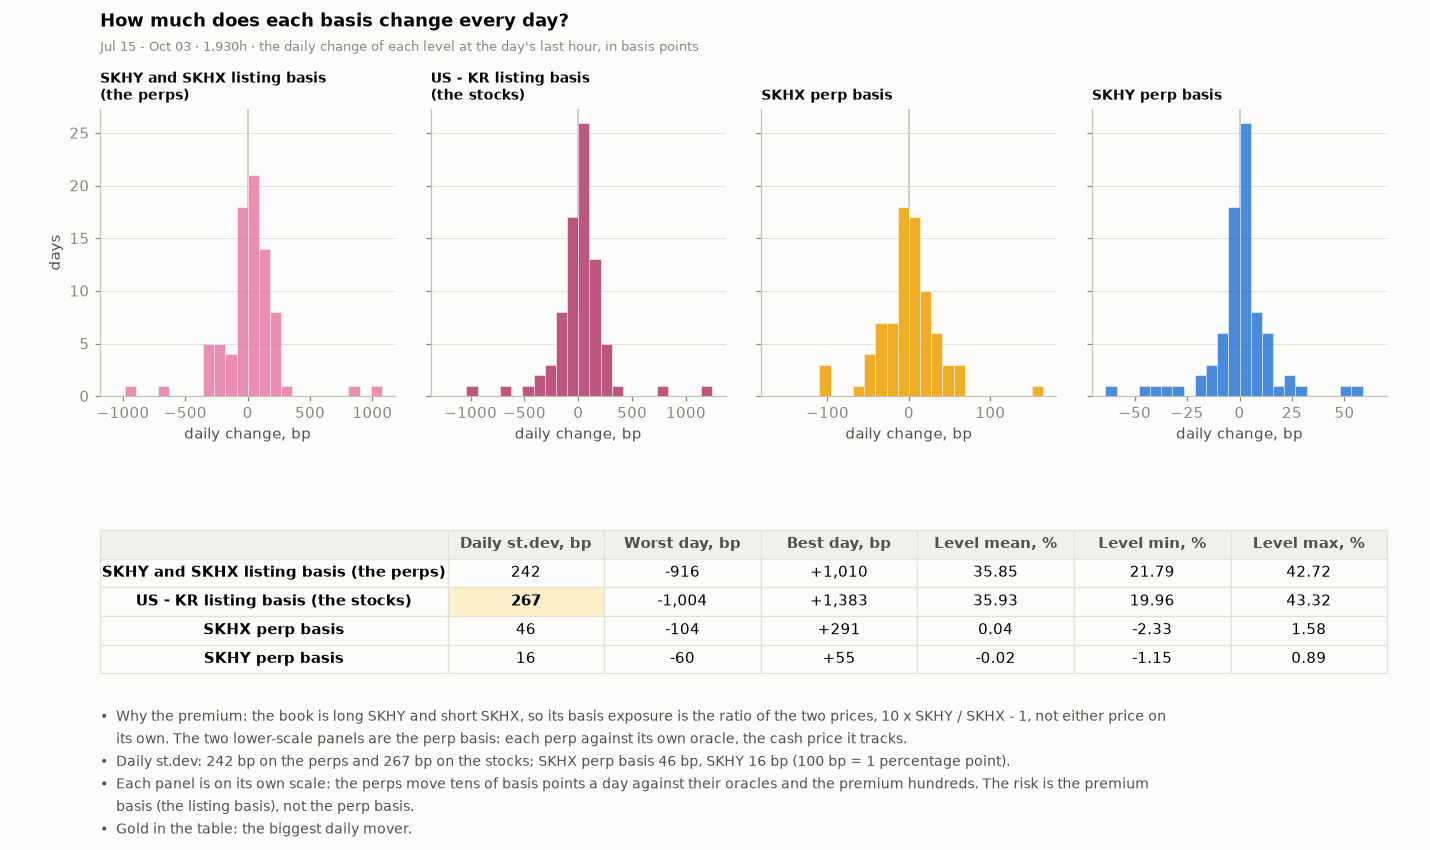

In [27]:
# ---- daily moves, in basis points: the perp bases move tens of bp, the premium hundreds, so each panel gets its own scale ----
dch_ = lambda x: x.resample("1D").last().diff().dropna() * 100          # percentage points -> basis points
SER_ = [("SKHY and SKHX listing basis (the perps)", P_perp, C_PREM), ("US - KR listing basis (the stocks)", P_orc, C_PREM_DK), ("SKHX perp basis", bA_, C_A), ("SKHY perp basis", bB_, C_B)]
MV = {lab: {"std": float(dch_(x).std()), "worst": float(dch_(x).min()), "best": float(dch_(x).max()), "lmean": float(x.mean()), "lmin": float(x.min()), "lmax": float(x.max())} for lab, x, _ in SER_}
MB = ["Why the premium: the book is long SKHY and short SKHX, so its basis exposure is the ratio of the two prices, 10 x SKHY / SKHX - 1, not either price on its own. The two lower-scale panels are the perp basis: each perp against its own oracle, the cash price it tracks.",
      f"Daily st.dev: {MV['SKHY and SKHX listing basis (the perps)']['std']:,.0f} bp on the perps and {MV['US - KR listing basis (the stocks)']['std']:,.0f} bp on the stocks; SKHX perp basis {MV['SKHX perp basis']['std']:,.0f} bp, SKHY {MV['SKHY perp basis']['std']:,.0f} bp (100 bp = 1 percentage point).",
      "Each panel is on its own scale: the perps move tens of basis points a day against their oracles and the premium hundreds. The risk is the premium basis (the listing basis), not the perp basis.",
      "Gold in the table: the biggest daily mover."]
HM = 6.2 + figstyle.nlines(MB) * 0.205 + 0.3
fig = plt.figure(figsize=(13, HM))
bm = figstyle.bullets(fig, MB)
gs = fig.add_gridspec(2, 4, height_ratios=[2.6, 1.3], hspace=0.62, wspace=0.12, left=0.07, right=0.97, top=1 - 0.16 * 6.2 / HM, bottom=bm + 0.02)
axs = [fig.add_subplot(gs[0, 0])]
axs += [fig.add_subplot(gs[0, i], sharey=axs[0]) for i in range(1, 4)]; axt = fig.add_subplot(gs[1, :]); axt.axis("off")
for a_, (lab, x, col) in zip(axs, SER_):
    v = dch_(x); lim = float(np.nanpercentile(np.abs(v), 99)) * 1.15
    a_.hist(v.clip(-lim, lim), bins=np.linspace(-lim, lim, 25), color=col, alpha=0.85, edgecolor=SURF, linewidth=0.4, zorder=3)
    a_.axvline(0, color=AXIS, linewidth=1); a_.set_title(lab.replace(" (", chr(10) + "(", 1).replace(" vs ", chr(10) + "vs "), fontsize=9, loc="left", pad=6); a_.set_xlabel("daily change, bp"); a_.grid(axis="x", visible=False)
axs[0].set_ylabel("days")
for a_ in axs[1:]:
    a_.tick_params(labelleft=False)
fig.suptitle("How much does each basis change every day?", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
fig.text(0.07, 1 - 0.075 * 6.2 / HM, f"{WSH} · the daily change of each level at the day's last hour, in basis points", color=MUTED, fontsize=8.5)
cells = [[lab, f"{m['std']:,.0f}", f"{m['worst']:+,.0f}", f"{m['best']:+,.0f}", f"{m['lmean']:.2f}", f"{m['lmin']:.2f}", f"{m['lmax']:.2f}"] for lab, m in MV.items()]
tb = put_table(axt, cells, ["", "Daily st.dev, bp", "Worst day, bp", "Best day, bp", "Level mean, %", "Level min, %", "Level max, %"], size=9.5, first=0.27)
big = max(range(len(cells)), key=lambda q: MV[cells[q][0]]["std"]); gold(tb, big + 1, 1)
figstyle.show(fig, "fig:s5-basis-moves", FIGURES)
STATS["basis_moves"] = MV

In [28]:
# ---- S5 the tails and the drawdown spells of the sized book beside the 1x book: stats.tail_stats and stats.drawdown_spells on the P&L the engine booked ----
r3_ = HP.run_pair(rows, replace(p1, leverage=float(SIZED_X)))
c3_ = HP.verify_pair(r3_); assert HP.all_pass(c3_) and len(c3_) == NCHK
d3_ = frame(r3_); D3_ = daily(d3_)
SERS = {"1x total": DAY["total"], f"{SIZED_X}x total": D3_["total"], "1x basis": DAY["premium"], "1x funding": DAY["funding"]}
TAIL = {k_: ST.tail_stats(list(v_ / EQUITY)) for k_, v_ in SERS.items()}
sp1_ = sorted(ST.drawdown_spells(list(num(df["equity_total"])), list(df.index.to_pydatetime())), key=lambda s: s["depth"])
sp3_ = sorted(ST.drawdown_spells(list(num(d3_["equity_total"])), list(d3_.index.to_pydatetime())), key=lambda s: s["depth"])
# the spells the tail block finds at 1x ARE the S3 episodes (same hours, same depths): asserted, and the comparator is broken once on purpose against the 3x book
EP_GAP = max(abs(a_["depth"] - b_["depth"] / 100) for a_, b_ in zip(sp1_, eps)); EP_BAD = max(abs(a_["depth"] - b_["depth"]) for a_, b_ in zip(sp1_, sp3_))
assert len(sp1_) == len(eps) and EP_GAP < 1e-9 and EP_BAD > 1e-3, (len(sp1_), len(eps), EP_GAP, EP_BAD)
SHOW3 = [s_ for s_ in sp3_ if s_["depth"] * 100 <= DD_CUT]
dd3 = -sp3_[0]["depth"] * 100
t3x = TAIL[f"{SIZED_X}x total"]; HEAD3 = DD_LIMIT_PCT - dd3; WD3 = -t3x["worst"] * 100
at3 = lambda i_: d3_.index[i_]
tt_ = lambda d_: [f"{d_[k_] * 100:+.2f}%" for k_ in ("VaR 95%", "CVaR 95%")] + [f"{d_['skew']:+.2f}", f"{d_['kurtosis']:.1f}", f"{d_['worst'] * 100:+.2f}%", f"{d_['best'] * 100:+.2f}%", f"{d_['n']}"]
W5 = D3_.nsmallest(5, "total"); DEEP4 = ", ".join(f"{-q_['depth'] * 100:.1f}%" for q_ in sp3_[:4]); N_TAIL = sum(1 for v_ in SERS[f"{SIZED_X}x total"] / EQUITY if v_ <= t3x["VaR 95%"])
display(Markdown(
    f"#### Tails and drawdown spells of the sized book ({SIZED_X}x) beside the 1x book\n\n"
    f"{WSB.replace('1x cross', 'cross')} · 1 regime · verify_pair {NCHK}/{NCHK} · daily P&L as % of equity, {len(DAY)} days\n\n"
    "| Daily P&L | VaR 95% | CVaR 95% | Skew | Kurtosis (normal = 3) | Worst day | Best day | Days |\n|---|---|---|---|---|---|---|---|\n"
    + "\n".join(f"| {k_} | " + " | ".join(tt_(v_)) + " |" for k_, v_ in TAIL.items()) + "\n\n"
    f"| The {len(W5)} worst days at {SIZED_X}x | Total, % of equity | Basis | Funding |\n|---|---|---|---|\n"
    + "\n".join(f"| {d_:%Y-%m-%d} | {r_['total'] / EQUITY * 100:+.2f}% | {r_['premium'] / EQUITY * 100:+.2f}% | {r_['funding'] / EQUITY * 100:+.2f}% |" for d_, r_ in W5.iterrows()) + "\n\n"
    f"| Drawdown spells at {SIZED_X}x, {-DD_CUT:g}% or deeper | High before | Trough | Depth | Days under water | Days to regain |\n|---|---|---|---|---|---|\n"
    + "\n".join(f"| {q_} | {d3_.index[s_['peak_i']]:%b %d} | {d3_.index[s_['trough_i']]:%b %d} | {s_['depth'] * 100:.2f}% | {s_['days']:.1f} | " + ("not yet" if s_["recovery_days"] is None else f"{s_['recovery_days']:.1f}") + " |" for q_, s_ in enumerate(SHOW3, 1)) + "\n\n"
    f"- The 5% tail holds {N_TAIL} of {len(DAY)} days, so VaR and CVaR rest on a handful of days; the kurtosis of {TAIL['1x total']['kurtosis']:.1f} (a normal reads 3) says the days that matter are the rare large ones.\n"
    f"- Drawdown at {SIZED_X}x: {dd3:.2f}% against the {DD_LIMIT_PCT:.0f}% limit, {HEAD3:.2f} points of headroom. The worst single day at {SIZED_X}x is {WD3:.2f}% of equity, so the headroom is {HEAD3 / WD3:.2f} of the worst day already seen. The deepest spells ran {DEEP4}.\n"
    f"- Longest time under water {ST.max_dd_days(list(num(d3_['equity_total'])), list(d3_.index.to_pydatetime())):.1f} days; the deepest spell took {ST.recovery_days(list(num(d3_['equity_total'])), list(d3_.index.to_pydatetime())):.1f} days to regain its high.\n"
    f"- The spells at 1x are the S3 episodes (depths agree to {EP_GAP:.0e}); against the {SIZED_X}x book they differ by {EP_BAD * 100:.1f} points, so the comparison can fail.\n"
    f"- The {SIZED_X}x drawdown is ONE realised path. A distribution of it needs a path resample that fundplat does not have (stationary_bootstrap_sums returns sums only): board item B-0478."))
STATS["tails"] = {"tail": TAIL, "dd3": float(dd3), "headroom": float(HEAD3), "worst_day3": float(WD3), "n_spells3": len(sp3_), "spells3": [{"depth": s_["depth"] * 100, "days": s_["days"], "recovery": s_["recovery_days"]} for s_ in SHOW3],
                  "max_dd_days3": float(ST.max_dd_days(list(num(d3_["equity_total"])), list(d3_.index.to_pydatetime()))), "ep_gap": float(EP_GAP), "ep_bad": float(EP_BAD)}

#### Tails and drawdown spells of the sized book (3x) beside the 1x book

Jul 15 - Oct 03 · 1,930h · cross · reserve 0 · costs on · 1 regime · verify_pair 41/41 · daily P&L as % of equity, 81 days

| Daily P&L | VaR 95% | CVaR 95% | Skew | Kurtosis (normal = 3) | Worst day | Best day | Days |
|---|---|---|---|---|---|---|---|
| 1x total | -0.85% | -1.58% | +0.09 | 8.9 | -2.86% | +2.87% | 81 |
| 3x total | -2.56% | -4.75% | +0.09 | 8.9 | -8.58% | +8.61% | 81 |
| 1x basis | -0.87% | -1.51% | +0.09 | 8.7 | -2.69% | +2.67% | 81 |
| 1x funding | -0.05% | -0.09% | +0.89 | 8.1 | -0.17% | +0.30% | 81 |

| The 5 worst days at 3x | Total, % of equity | Basis | Funding |
|---|---|---|---|
| 2026-07-31 | -8.58% | -8.06% | -0.52% |
| 2026-07-27 | -6.40% | -6.13% | -0.27% |
| 2026-08-20 | -3.37% | -3.22% | -0.15% |
| 2026-08-21 | -2.85% | -2.68% | -0.17% |
| 2026-07-19 | -2.56% | -2.60% | +0.04% |

| Drawdown spells at 3x, 1% or deeper | High before | Trough | Depth | Days under water | Days to regain |
|---|---|---|---|---|---|
| 1 | Aug 17 | Aug 26 | -12.35% | 24.0 | 14.8 |
| 2 | Jul 24 | Jul 28 | -11.78% | 6.1 | 1.6 |
| 3 | Jul 15 | Jul 21 | -11.13% | 8.8 | 3.2 |
| 4 | Jul 30 | Aug 03 | -10.16% | 13.7 | 9.9 |
| 5 | Sep 14 | Sep 22 | -3.51% | 8.7 | 1.2 |
| 6 | Aug 13 | Aug 13 | -2.16% | 0.8 | 0.5 |
| 7 | Jul 15 | Jul 15 | -2.08% | 0.2 | 0.1 |
| 8 | Sep 10 | Sep 11 | -1.85% | 3.6 | 2.7 |
| 9 | Jul 15 | Jul 15 | -1.82% | 0.3 | 0.2 |
| 10 | Oct 01 | Oct 01 | -1.67% | 0.8 | 0.2 |
| 11 | Sep 28 | Sep 29 | -1.24% | 2.6 | 1.2 |

- The 5% tail holds 5 of 81 days, so VaR and CVaR rest on a handful of days; the kurtosis of 8.9 (a normal reads 3) says the days that matter are the rare large ones.
- Drawdown at 3x: 12.35% against the 15% limit, 2.65 points of headroom. The worst single day at 3x is 8.58% of equity, so the headroom is 0.31 of the worst day already seen. The deepest spells ran 12.4%, 11.8%, 11.1%, 10.2%.
- Longest time under water 24.0 days; the deepest spell took 14.8 days to regain its high.
- The spells at 1x are the S3 episodes (depths agree to 1e-16); against the 3x book they differ by 7.9 points, so the comparison can fail.
- The 3x drawdown is ONE realised path. A distribution of it needs a path resample that fundplat does not have (stationary_bootstrap_sums returns sums only): board item B-0478.

## S6 · Decision

If it passed: what size, can it be filled, what are the limits? Information only if S3 and S4 failed.

In [29]:
from matplotlib.patches import Patch
WSH = f"{df.index[0]:%b %d} - {df.index[-1]:%b %d} \u00b7 {len(df):,}h"
WSB = WSH + " \u00b7 1x cross \u00b7 reserve 0 \u00b7 costs on"

GR = {}
for L in LEVS:
    for R in RESV:
        r_ = HP.run_pair(rows, replace(p1, leverage=float(L), reserve_mult=float(R))); c_ = HP.verify_pair(r_)
        assert HP.all_pass(c_) and len(c_) == 41, (L, R); GR[(L, R)] = r_
LAD = {L: (GR[(L, 0.0)], frame(GR[(L, 0.0)])) for L in LEVS}
def wick_room(r_):
    v = np.array([np.inf if x is None else float(x) for x in r_["series"]["dist_wick_pct"]]); k = int(v.argmax() if False else v.argmin())
    Pw = rows[k]["B_lo"] * 10 / rows[k]["A_hi"] * 100 - 100
    return pts(Pw, v[k] / 100.0), Pw, k
ROOM_ENTRY = {L: pts(P0, 1.0 / L - MMR) for L in LEVS}
WICKPT, KW = {}, {}
for L in LEVS:
    WICKPT[L], _, KW[L] = wick_room(LAD[L][0])
CLOSEPT = {}
for L in LEVS:
    d_ = LAD[L][1]; i_b = num(d_["dist_book_pct"]).idxmin()
    CLOSEPT[L] = pts(float(num(d_["implied_premium_pct"]).loc[i_b]), LAD[L][0]["min_dist_book_pct"] / 100.0)
adv_A = np.array([rows[i]["A_hi"] / rows[i - 1]["A_perp"] - 1.0 for i in range(1, len(rows))]) * 100
adv_B = np.array([1.0 - rows[i]["B_lo"] / rows[i - 1]["B_perp"] for i in range(1, len(rows))]) * 100
joint = 0.5 * (adv_A + adv_B); kJ = int(joint.argmax()); WORST_JOINT = float(joint[kJ])
WICK_PTS_REQ = pts(P0, WORST_JOINT / 100.0); REQ_PTS = STOP_PTS + WICK_PTS_REQ
WORST_NARROW = float(-(prem - P0).min())
FEE_USD = {(L, R): EQUITY * L / (1 + R) * ENTRY_BPS / 1e4 for L in LEVS for R in RESV}
PLACEABLE = {(L, R): EQUITY / (1 + R) - FEE_USD[(L, R)] >= EQUITY * L / (1 + R) / MAXLEV for L in LEVS for R in RESV}
OKR = [L for L in LEVS if ROOM_ENTRY[L] > REQ_PTS and LAD[L][0]["max_drawdown"] * 100 > -DD_LIMIT_PCT and LAD[L][0]["liquidations"] == 0 and WICKPT[L] > STOP_PTS and PLACEABLE[(L, 0.0)]]
L_PICK = max(OKR) if OKR else None; SIZED = bool(PASSED and L_PICK); N_PICK = (L_PICK or 1) * EQUITY / 2
NLIQ = int(sum(r_["liquidations"] for r_ in GR.values()))
STATS["grid"] = {"n": len(GR), "nliq": NLIQ}

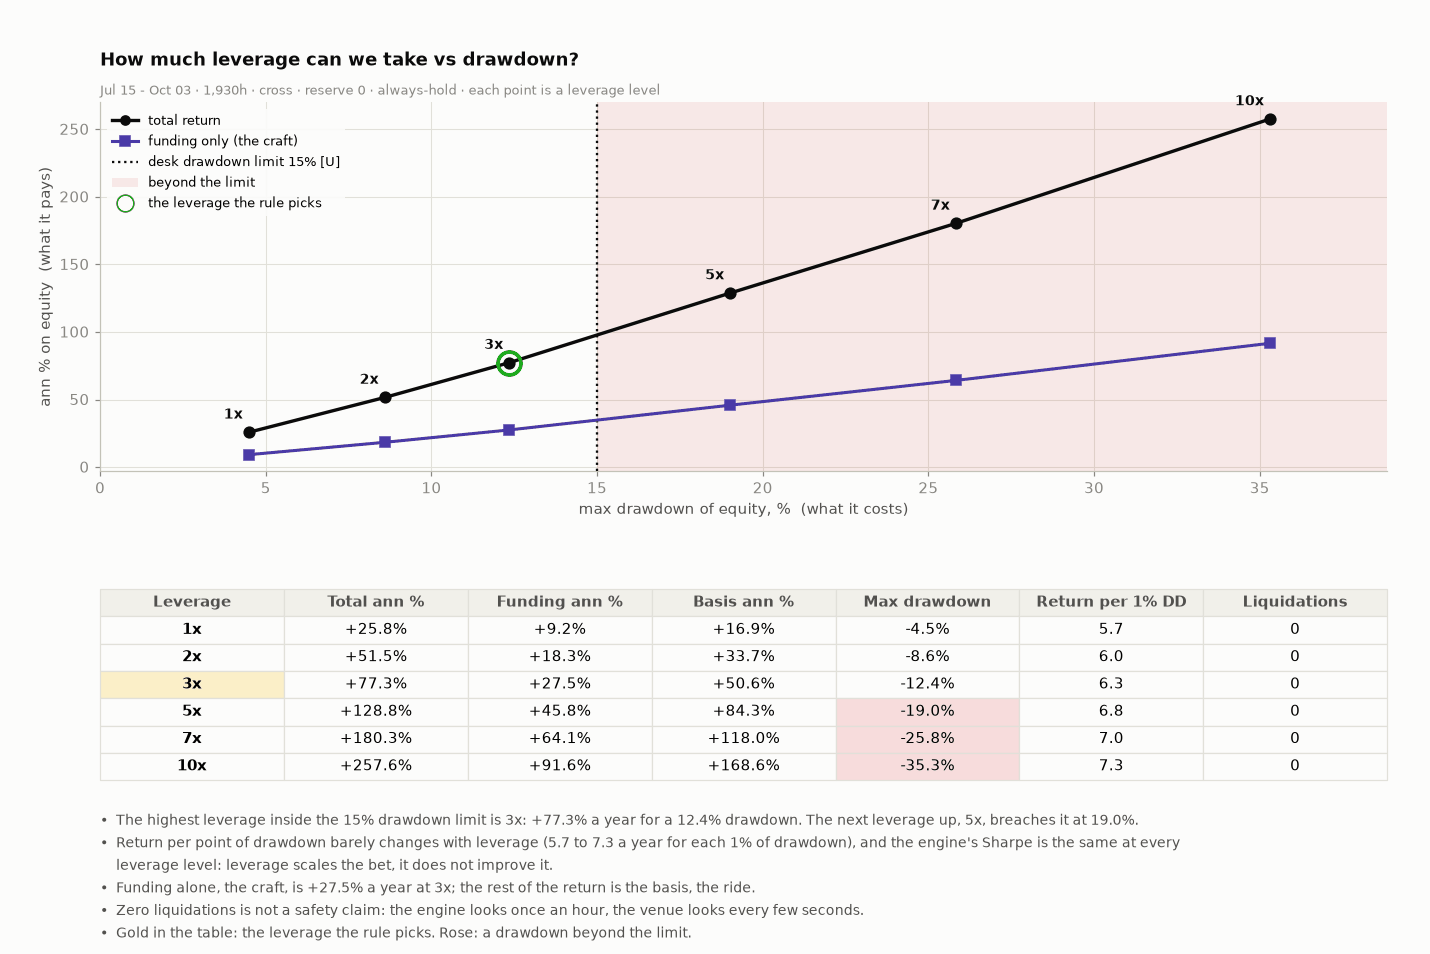

In [30]:
# ---- 6.1 what does each leverage level buy for its drawdown? the return against the cost, with the desk limit marked ----
sh_set = {round(LAD[L][0]["sharpe"], 2) for L in LEVS}; assert len(sh_set) == 1, sh_set
SHARPE = sh_set.pop()
CAL = {L: LAD[L][0]["ann_pct"] / abs(LAD[L][0]["max_drawdown"] * 100) for L in LEVS}
DDX = {L: -LAD[L][0]["max_drawdown"] * 100 for L in LEVS}
above = [L for L in LEVS if DDX[L] > DD_LIMIT_PCT]
LB = [f"The highest leverage inside the {DD_LIMIT_PCT:.0f}% drawdown limit is {L_PICK}x: {LAD[L_PICK][0]['ann_pct']:+.1f}% a year for a {DDX[L_PICK]:.1f}% drawdown. " + (f"The next leverage up, {above[0]}x, breaches it at {DDX[above[0]]:.1f}%." if above else ""),
      f"Return per point of drawdown barely changes with leverage ({min(CAL.values()):.1f} to {max(CAL.values()):.1f} a year for each 1% of drawdown), and the engine's Sharpe is the same at every leverage level: leverage scales the bet, it does not improve it.",
      f"Funding alone, the craft, is {LAD[L_PICK][0]['funding_ann_pct_aum']:+.1f}% a year at {L_PICK}x; the rest of the return is the basis, the ride.",
      "Zero liquidations is not a safety claim: the engine looks once an hour, the venue looks every few seconds.",
      "Gold in the table: the leverage the rule picks. Rose: a drawdown beyond the limit."]
fig, gs, ax, axt = fig_tab(7.2, (2.9, 1.5), hspace=0.42, nb=figstyle.nlines(LB))
xv = [DDX[L] for L in LEVS]
ax.axvspan(DD_LIMIT_PCT, max(xv) * 1.1, color=CRIT, alpha=0.10, linewidth=0, zorder=1)
ax.axvline(DD_LIMIT_PCT, color=INKc, linestyle=":", linewidth=1.5, zorder=3)
yt = [LAD[L][0]["ann_pct"] for L in LEVS]; yf = [LAD[L][0]["funding_ann_pct_aum"] for L in LEVS]
ax.plot(xv, yt, "o-", color=INKc, linewidth=2.2, markersize=7, zorder=4); ax.plot(xv, yf, "s-", color=C_NET, linewidth=2.0, markersize=6, zorder=4)
for L, a_, b_ in zip(LEVS, xv, yt):
    ax.annotate(f"{L}x", xy=(a_, b_), xytext=(-4, 9), textcoords="offset points", fontsize=9, fontweight="bold", color=INKc, ha="right", zorder=6)
if L_PICK:
    ax.plot([DDX[L_PICK]], [LAD[L_PICK][0]["ann_pct"]], "o", color=GOOD, markersize=15, markerfacecolor="none", markeredgecolor=GOOD, markeredgewidth=2.4, zorder=5)
ax.set_xlim(0, max(xv) * 1.1); ax.set_xlabel("max drawdown of equity, %  (what it costs)"); ax.set_ylabel("ann % on equity  (what it pays)")
ax.legend(handles=[plt.Line2D([], [], color=INKc, marker="o", linewidth=2.2, label="total return"), plt.Line2D([], [], color=C_NET, marker="s", linewidth=2.0, label="funding only (the craft)"),
                   plt.Line2D([], [], color=INKc, linestyle=":", linewidth=1.5, label=f"desk drawdown limit {DD_LIMIT_PCT:.0f}% [U]"), Patch(facecolor=CRIT, alpha=0.10, label="beyond the limit"),
                   plt.Line2D([], [], color=GOOD, marker="o", markerfacecolor="none", markersize=11, linestyle="none", label="the leverage the rule picks")], loc="upper left", fontsize=8.5, **LEG)
ask(ax, "How much leverage can we take vs drawdown?", f"{WSH} · cross · reserve 0 · always-hold · each point is a leverage level")
cells = [[f"{L}x", f"{LAD[L][0]['ann_pct']:+.1f}%", f"{LAD[L][0]['funding_ann_pct_aum']:+.1f}%", f"{LAD[L][0]['premium_ann_pct_aum']:+.1f}%", f"{LAD[L][0]['max_drawdown']*100:.1f}%", f"{CAL[L]:.1f}", f"{LAD[L][0]['liquidations']}"] for L in LEVS]
tb = put_table(axt, cells, ["Leverage", "Total ann %", "Funding ann %", "Basis ann %", "Max drawdown", "Return per 1% DD", "Liquidations"], size=9.5)
for i_, L in enumerate(LEVS, 1):
    if LAD[L][0]["max_drawdown"] * 100 <= -DD_LIMIT_PCT:
        tint(tb, i_, 4, "rose")
    if L == L_PICK:
        gold(tb, i_, 0)
foot(fig, *LB)
figstyle.show(fig, "fig:s6-ladder", FIGURES)
STATS["ladder"] = {str(L): {"ann": LAD[L][0]["ann_pct"], "fund": LAD[L][0]["funding_ann_pct_aum"], "prem": LAD[L][0]["premium_ann_pct_aum"], "dd": LAD[L][0]["max_drawdown"] * 100, "liq": LAD[L][0]["liquidations"], "calmar": CAL[L]} for L in LEVS}
STATS["ladder_meta"] = {"sharpe": SHARPE, "calmar_min": min(CAL.values()), "calmar_max": max(CAL.values()), "next_breach": above[0] if above else None}

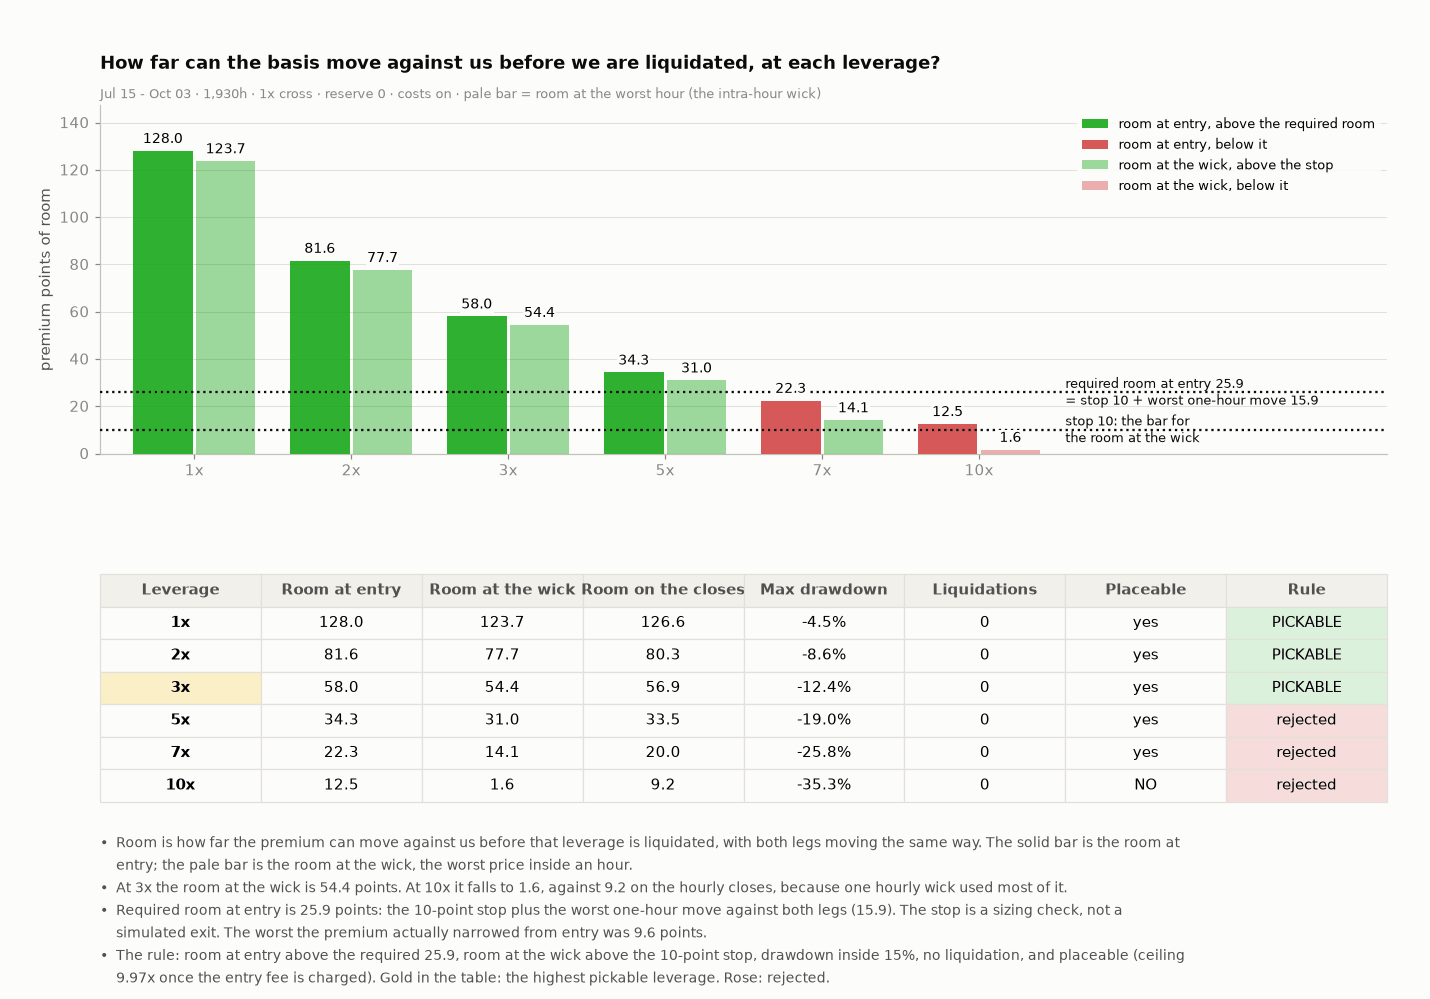

In [31]:
# ---- 6.2 how far can the basis move against us before a leverage level is liquidated? ----
RB = ["Room is how far the premium can move against us before that leverage is liquidated, with both legs moving the same way. The solid bar is the room at entry; the pale bar is the room at the wick, the worst price inside an hour.",
      f"At {L_PICK}x the room at the wick is {WICKPT[L_PICK]:.1f} points. At {LEVS[-1]}x it falls to {WICKPT[LEVS[-1]]:.1f}, against {CLOSEPT[LEVS[-1]]:.1f} on the hourly closes, because one hourly wick used most of it.",
      f"Required room at entry is {REQ_PTS:.1f} points: the {STOP_PTS:.0f}-point stop plus the worst one-hour move against both legs ({WICK_PTS_REQ:.1f}). The stop is a sizing check, not a simulated exit. The worst the premium actually narrowed from entry was {WORST_NARROW:.1f} points.",
      f"The rule: room at entry above the required {REQ_PTS:.1f}, room at the wick above the {STOP_PTS:.0f}-point stop, drawdown inside {DD_LIMIT_PCT:.0f}%, no liquidation, and placeable (ceiling {L_MAX_PLACEABLE:.2f}x once the entry fee is charged). Gold in the table: the highest pickable leverage. Rose: rejected."]
fig, gs, ax, axt = fig_tab(7.4, (2.6, 1.7), hspace=0.42, nb=figstyle.nlines(RB))
xs = np.arange(len(LEVS)); wick = [WICKPT[L] for L in LEVS]; entry = [ROOM_ENTRY[L] for L in LEVS]
b_e = ax.bar(xs - 0.2, entry, 0.38, color=[GOOD if e > REQ_PTS else CRIT for e in entry], alpha=0.85, zorder=3)
b_w = ax.bar(xs + 0.2, wick, 0.38, color=[GOOD if w > STOP_PTS else CRIT for w in wick], alpha=0.40, zorder=3)
for t_ in ax.bar_label(b_e, labels=[f"{e:.1f}" for e in entry], fontsize=9, padding=3) + ax.bar_label(b_w, labels=[f"{w:.1f}" for w in wick], fontsize=9, padding=3):
    t_.set_bbox(dict(facecolor=SURF, edgecolor="none", pad=0.8)); t_.set_zorder(6)
ax.axhline(REQ_PTS, color=INKc, linestyle=":", linewidth=1.5, zorder=4); ax.axhline(STOP_PTS, color=INKc, linestyle=":", linewidth=1.5, zorder=4)
ax.set_xlim(-0.6, len(LEVS) + 1.6)                       # the bar labels sit in the margin right of the last rung, clear of the bars
ax.text(len(LEVS) - 0.45, REQ_PTS, f"required room at entry {REQ_PTS:.1f}\n= stop {STOP_PTS:.0f} + worst one-hour move {WICK_PTS_REQ:.1f}", ha="left", va="center", fontsize=8.5, color=INKc)
ax.text(len(LEVS) - 0.45, STOP_PTS, f"stop {STOP_PTS:.0f}: the bar for\nthe room at the wick", ha="left", va="center", fontsize=8.5, color=INKc)
ax.set_xticks(xs); ax.set_xticklabels([f"{L}x" for L in LEVS]); ax.set_ylabel("premium points of room"); ax.set_ylim(0, max(entry) * 1.15); ax.grid(axis="x", visible=False)
ax.legend(handles=[Patch(facecolor=GOOD, alpha=0.85, label="room at entry, above the required room"), Patch(facecolor=CRIT, alpha=0.85, label="room at entry, below it"),
                   Patch(facecolor=GOOD, alpha=0.40, label="room at the wick, above the stop"), Patch(facecolor=CRIT, alpha=0.40, label="room at the wick, below it")], loc="upper right", fontsize=8.5, **LEG)
ask(ax, "How far can the basis move against us before we are liquidated, at each leverage?", f"{WSB} · pale bar = room at the worst hour (the intra-hour wick)")
cells = [[f"{L}x", f"{ROOM_ENTRY[L]:.1f}", f"{WICKPT[L]:.1f}", f"{CLOSEPT[L]:.1f}", f"{LAD[L][0]['max_drawdown']*100:.1f}%", f"{LAD[L][0]['liquidations']}", ("yes" if PLACEABLE[(L, 0.0)] else "NO"), ("PICKABLE" if L in OKR else "rejected")] for L in LEVS]
tb = put_table(axt, cells, ["Leverage", "Room at entry", "Room at the wick", "Room on the closes", "Max drawdown", "Liquidations", "Placeable", "Rule"], size=9.5)
for i_, L in enumerate(LEVS, 1):
    tint(tb, i_, 7, "green" if L in OKR else "rose")
    if L == L_PICK:
        gold(tb, i_, 0)
foot(fig, *RB)
figstyle.show(fig, "fig:s6-room", FIGURES)
STATS["room"] = {"req": REQ_PTS, "wick_req": WICK_PTS_REQ, "p0": float(P0), "worst_narrow": WORST_NARROW, "l_pick": L_PICK, "sized": SIZED, "passed": PASSED, "ceiling": L_MAX_PLACEABLE,
                 "rungs": {str(L): {"entry": ROOM_ENTRY[L], "wick": WICKPT[L], "closes": CLOSEPT[L], "placeable": bool(PLACEABLE[(L, 0.0)]), "ok": L in OKR} for L in LEVS}, "nliq": NLIQ}

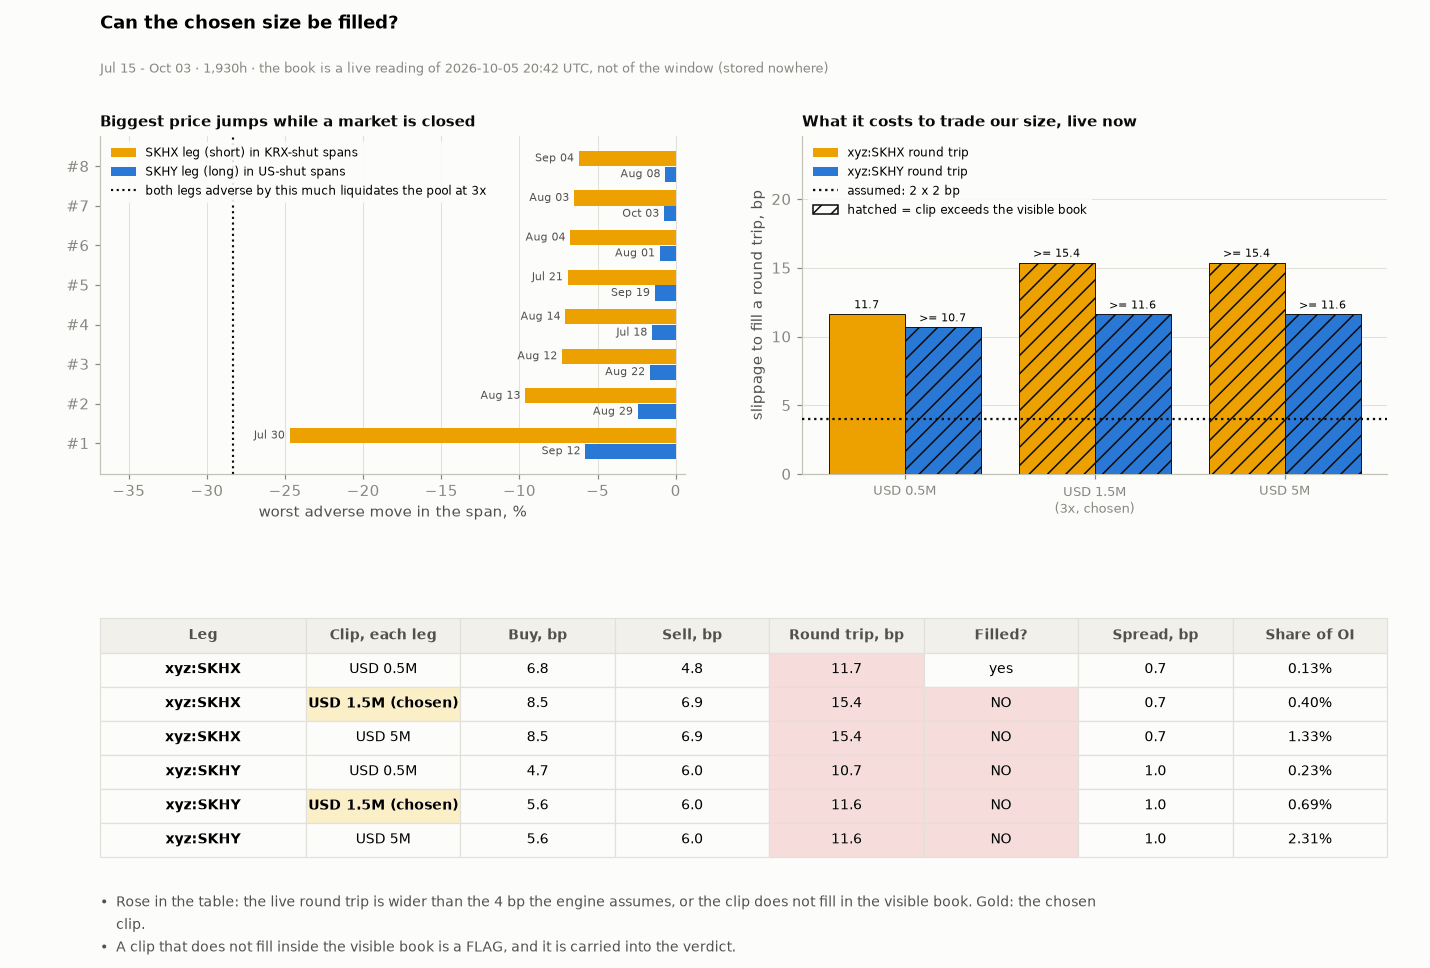

In [32]:
# ---- 6.3 can it be filled? closed-session gaps, and the live book (a reading of NOW, stored nowhere) ----
gA = HP.leg_session_gaps(rows, "A", "krx"); gB = HP.leg_session_gaps(rows, "B", "us")
gaA = sorted([g for g in gA if "up_pct" in g], key=lambda g: -g["up_pct"])[:8]; gaB = sorted([g for g in gB if "down_pct" in g], key=lambda g: g["down_pct"])[:8]
advA_g = [-g["up_pct"] for g in gaA]; advB_g = [g["down_pct"] for g in gaB]
dayof = lambda g: dt.datetime.fromtimestamp(g["start"] / 1000, dt.timezone.utc).strftime("%b %d")
SIZES = tuple(sorted({round(L * EQUITY / 2) for L in (1, L_PICK or 1, 10)}))
try:
    BD = HP.book_depth((COIN_A, COIN_B), sizes=SIZES); SNAP = DATA.hl_dex_bulk_funding("xyz")
except Exception as e:
    BD, SNAP = {}, {}; print("live read unavailable:", repr(e))
EX = []
for c_, x_ in (BD or {}).items():
    if x_:
        for sz in SIZES:
            f_ = x_["fills"][sz]
            EX.append({"coin": c_, "clip": sz, "buy": f_["buy"]["slippage_bps"], "sell": f_["sell"]["slippage_bps"], "filled": bool(f_["buy"]["filled"] and f_["sell"]["filled"]), "rt": f_["buy"]["slippage_bps"] + f_["sell"]["slippage_bps"], "spread": x_["spread_bps"] or 0})
fig = plt.figure(figsize=(13, 8.8))
bm = figstyle.bullets(fig, [f"Rose in the table: the live round trip is wider than the {2*p1.exec_slippage_bps:g} bp the engine assumes, or the clip does not fill in the visible book. Gold: the chosen clip.",
                            "A clip that does not fill inside the visible book is a FLAG, and it is carried into the verdict."])
gs = fig.add_gridspec(2, 2, height_ratios=[2.7, 1.9], hspace=0.5, wspace=0.2, left=0.07, right=0.97, top=0.86, bottom=bm + 0.02)
s0, s1 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]); axt = fig.add_subplot(gs[1, :]); axt.axis("off")
ys = np.arange(len(advA_g))
s0.barh(ys + 0.2, advA_g, height=0.38, color=C_A, zorder=3); s0.barh(np.arange(len(advB_g)) - 0.2, advB_g, height=0.38, color=C_B, zorder=3)
for i, (v, g) in enumerate(zip(advA_g, gaA)):
    s0.text(v - 0.3, i + 0.2, dayof(g), ha="right", va="center", fontsize=7.5, color=INK2c)
for i, (v, g) in enumerate(zip(advB_g, gaB)):
    s0.text(v - 0.3, i - 0.2, dayof(g), ha="right", va="center", fontsize=7.5, color=INK2c)
liq_line = -(1.0 / (L_PICK or 1) - MMR) * 100
s0.axvline(liq_line, color=INKc, linestyle=":", linewidth=1.4, zorder=2)
s0.set_yticks(ys); s0.set_yticklabels([f"#{i+1}" for i in ys]); s0.set_xlabel("worst adverse move in the span, %"); s0.grid(axis="y", visible=False)
s0.set_xlim(min(min(advA_g), min(advB_g), liq_line) * 1.3, 0.6)
s0.legend(handles=[Patch(facecolor=C_A, label="SKHX leg (short) in KRX-shut spans"), Patch(facecolor=C_B, label="SKHY leg (long) in US-shut spans"), plt.Line2D([], [], color=INKc, linestyle=":", linewidth=1.4, label=f"both legs adverse by this much liquidates the pool at {L_PICK}x")], loc="upper left", fontsize=8, **LEG)
s0.set_title("Biggest price jumps while a market is closed", fontsize=10, loc="left", pad=6)
if EX:
    EXd = pd.DataFrame(EX)
    for j, c_ in enumerate((COIN_A, COIN_B)):
        sub = EXd[EXd["coin"] == c_]; okf = sub["filled"].tolist()
        b = s1.bar(np.arange(len(sub)) + (j - 0.5) * 0.4, sub["rt"], 0.4, color=[C_A, C_B][j], hatch=["" if f else "//" for f in okf], edgecolor=INKc, linewidth=0.6, zorder=3)
        s1.bar_label(b, labels=[(f"{v:.1f}" if f else f">= {v:.1f}") for v, f in zip(sub["rt"], okf)], fontsize=7.5, padding=2)
    s1.axhline(2 * p1.exec_slippage_bps, color=INKc, linestyle=":", linewidth=1.5, zorder=4)
    s1.set_xticks(np.arange(len(SIZES))); s1.set_xticklabels([usdm(s) + (f"\n({L_PICK}x, chosen)" if s == round(N_PICK) else "") for s in SIZES], fontsize=8.5)
    s1.set_ylabel("slippage to fill a round trip, bp"); s1.set_ylim(top=EXd["rt"].max() * 1.6); s1.grid(axis="x", visible=False)
    s1.legend(handles=[Patch(facecolor=C_A, label="xyz:SKHX round trip"), Patch(facecolor=C_B, label="xyz:SKHY round trip"), plt.Line2D([], [], color=INKc, linestyle=":", linewidth=1.5, label=f"assumed: 2 x {p1.exec_slippage_bps:g} bp"),
                       Patch(facecolor=SURF, hatch="//", edgecolor=INKc, label="hatched = clip exceeds the visible book")], loc="upper left", fontsize=8, **LEG)
    s1.set_title("What it costs to trade our size, live now", fontsize=10, loc="left", pad=6)
    cells = [[r["coin"], usdm(r["clip"]) + (" (chosen)" if r["clip"] == round(N_PICK) else ""), f"{r['buy']:.1f}", f"{r['sell']:.1f}", f"{r['rt']:.1f}", ("yes" if r["filled"] else "NO"), f"{r['spread']:.1f}", (f"{r['clip']/SNAP[r['coin']]['oi_usd']*100:.2f}%" if SNAP else "")] for r in EX]
    tb = put_table(axt, cells, ["Leg", "Clip, each leg", "Buy, bp", "Sell, bp", "Round trip, bp", "Filled?", "Spread, bp", "Share of OI"], size=9, first=0.16)
    for i_, r in enumerate(EX, 1):
        tint(tb, i_, 4, "rose" if r["rt"] > 2 * p1.exec_slippage_bps else "green")
        if not r["filled"]:
            tint(tb, i_, 5, "rose")
        if r["clip"] == round(N_PICK):
            gold(tb, i_, 1)
else:
    s1.axis("off"); axt.text(0.5, 0.5, "live book read unavailable at this run", ha="center")
fig.suptitle("Can the chosen size be filled?", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
fig.text(0.07, 0.925, f"{WSH} \u00b7 the book is a live reading of {dt.datetime.now(dt.timezone.utc):%Y-%m-%d %H:%M} UTC, not of the window (stored nowhere)", color=MUTED, fontsize=8.5)
figstyle.show(fig, "fig:s6-fill", FIGURES)
filled_ok = bool(EX) and all(r["filled"] for r in EX if r["clip"] == round(N_PICK))
worst_rt = max((r["rt"] for r in EX if r["clip"] == round(N_PICK)), default=None)
STATS["fill"] = {"clip": N_PICK, "filled_ok": filled_ok, "worst_rt": worst_rt, "assumed": 2 * p1.exec_slippage_bps, "rows": EX, "oi": {c: SNAP[c]["oi_usd"] for c in (COIN_A, COIN_B)} if SNAP else {},
                 "gapsA": [(dayof(g), -g["up_pct"]) for g in gaA[:3]], "gapsB": [(dayof(g), g["down_pct"]) for g in gaB[:3]]}

## S7 · Verdict

The gates, the conclusion and the manifest are rendered below from the run's own objects.

In [33]:
# ---- what the verdict (S7) needs, so none of its numbers is typed ----
MONNET = pd.DataFrame(FS["monthly"]).T["net_mean_ann_pct"]
r_pick = LAD[L_PICK][0] if L_PICK else res
STATS["verdict"] = {"window_from": f"{df.index[0]:%Y-%m-%d %H:%M}Z", "window_to": f"{df.index[-1]:%Y-%m-%d %H:%M}Z", "days": res["days"], "months": int(len(MONNET)), "verify": f"verify_pair {NCHK}/{NCHK} ALL PASS",
                    "hurdle": HURDLE_PCT, "fund_ann": res["funding_ann_pct_aum"], "ann": res["ann_pct"], "maxdd": res["max_drawdown"] * 100, "funding_share": res["funding_share_of_gross"] * 100,
                    "pick": L_PICK, "pick_per_leg": N_PICK, "pick_entry": ROOM_ENTRY[L_PICK] if L_PICK else None, "pick_wick": WICKPT[L_PICK] if L_PICK else None,
                    "pick_wick_when": (f"{LAD[L_PICK][1].index[KW[L_PICK]]:%Y-%m-%d %H:%M}Z" if L_PICK else None), "pick_dd": r_pick["max_drawdown"] * 100, "pick_fund": r_pick["funding_ann_pct_aum"],
                    "pick_margin": EQUITY * L_PICK / MAXLEV if L_PICK else None, "entry_bps": ENTRY_BPS, "maxlev": MAXLEV, "equity": EQUITY, "stop": STOP_PTS, "dd_limit": DD_LIMIT_PCT,
                    "wick_10x": WICKPT[LEVS[-1]], "closes_10x": CLOSEPT[LEVS[-1]]}

In [34]:
# ---- the next bet, as two FIXED windows that open after this study's data ends (B-0283). The metric is computed over exactly the registered hours and printed under the
# ---- name the pre-flight uses, so record.py and remeasure.py can read it back. Before a window has closed it prints "open"; a number appears only for a complete window.
FWD_T0 = ms_(FWD_FROM)
assert FWD_T0 > END_MS, "the forward window must open after the pinned study window ends"
pF = replace(p1, leverage=float(FWD_LEV))
FWD = {}
for key_, h_ in (("fwd7d", FWD_H), ("fwd30d", FWD30_H)):
    w_ = [r_ for r_ in rows_all if FWD_T0 <= r_["time"] < FWD_T0 + h_ * HOUR]
    whole_ = len(w_) == h_ and all(b_["time"] - a_["time"] == HOUR for a_, b_ in zip(w_, w_[1:]))
    out_ = {"from": FWD_FROM, "hours": h_, "stored": len(w_), "complete": whole_, "to": f"{dt.datetime.fromtimestamp((FWD_T0 + h_ * HOUR) / 1000, dt.timezone.utc):%Y-%m-%d %H:%M}"}
    if whole_:
        rf_ = HP.run_pair(w_, pF); cf_ = HP.verify_pair(rf_)
        assert HP.all_pass(cf_), {k_: v_ for k_, v_ in cf_.items() if not v_[0]}
        out_.update({"funding_net_usd": rf_["funding_net"], "funding_ann_pct": rf_["funding_ann_pct_aum"], "positive": int(rf_["funding_net"] > 0)})
    FWD[key_] = out_
# ---- the band's source: the pinned window cut into non-overlapping blocks of the bet's own horizon, counted back from its end ----
def blocks_(h_):
    out_, i_ = [], len(rows)
    while i_ - h_ >= 0:
        out_.append(HP.run_pair(rows[i_ - h_:i_], pF)["funding_ann_pct_aum"]); i_ -= h_
    return out_[::-1]
WK, MO = np.array(blocks_(FWD_H)), np.array(blocks_(FWD30_H))
RUN_ = LAD[int(FWD_LEV)][0]["funding_ann_pct_aum"]                       # the whole pinned window, the running mean the naive forecast would use
WK_SD = float(WK.std(ddof=1)); SE_ = WK_SD / np.sqrt(FWD30_H / FWD_H)    # a 30 d mean of week-sized blocks that do not persist (lag-1 below) has the weekly st.dev / sqrt(30 d / 7 d)
LAG1 = float(np.corrcoef(WK[:-1], WK[1:])[0, 1])
BAND30 = (RUN_ - SE_, RUN_ + SE_)
# the naive forecasts of a week, scored on the same weeks: the running mean of the weeks before it, the week before, zero
miss_ = {"running mean": np.mean([abs(WK[i_] - WK[:i_].mean()) for i_ in range(1, len(WK))]), "last week": np.mean([abs(WK[i_] - WK[i_ - 1]) for i_ in range(1, len(WK))]), "zero": np.mean(np.abs(WK[1:]))}
STATS["forward"] = {"lev": FWD_LEV, "fwd7d": FWD["fwd7d"], "fwd30d": FWD["fwd30d"], "weeks": WK.tolist(), "months": MO.tolist(), "running": RUN_, "wk_sd": WK_SD, "se30": SE_, "lag1": LAG1,
                    "band30": BAND30, "wk_pos": int((WK > 0).sum()), "miss": {k_: float(v_) for k_, v_ in miss_.items()}}
display(Markdown(
    f"#### The registered forward windows, {FWD_LEV:g}x book\n\n"
    f"| Window | Opens | Closes | Hours stored | Registered bet |\n|---|---|---|---|---|\n"
    f"| 168 h | {FWD_FROM}Z | {FWD['fwd7d']['to']}Z | {FWD['fwd7d']['stored']} of {FWD_H} | funding is positive (the sign) |\n"
    f"| 30 d | {FWD_FROM}Z | {FWD['fwd30d']['to']}Z | {FWD['fwd30d']['stored']} of {FWD30_H} | funding {BAND30[0]:.1f}% to {BAND30[1]:.1f}% a year on equity |\n\n"
    f"Where the numbers come from, on the pinned window of {len(rows):,} hours: {len(WK)} whole weeks of the {FWD_LEV:g}x book had a mean of {WK.mean():+.1f}% and a st.dev of {WK_SD:.1f} points a year, "
    f"and {int((WK > 0).sum())} of the {len(WK)} were positive; one week against the next correlates {LAG1:+.2f}. A week is not predictable, so the 30-day band is the whole-window mean ({RUN_:.1f}%) "
    f"plus and minus one standard error of a 30-day mean ({SE_:.1f} points = {WK_SD:.1f} / sqrt({FWD30_H / FWD_H:.2f})). The {len(MO)} whole 30-day blocks before the window ended came in at "
    + " and ".join(f"{m_:.1f}%" for m_ in MO) + ". "
    f"Scored on the same weeks, the running mean missed by {miss_['running mean']:.1f} points, last week by {miss_['last week']:.1f} and zero by {miss_['zero']:.1f}. "
    "The band is a one-standard-error range [U]: about two times in three. One window, one regime."))
for key_, name_ in (("fwd7d", "funding_positive"), ("fwd30d", "funding_ann_pct")):
    f_ = FWD[key_]
    val_ = (f"{f_['positive']}" if key_ == "fwd7d" else f"{f_['funding_ann_pct']:.2f}") if f_["complete"] else f"open ({f_['stored']} of {f_['hours']} hours stored)"
    print(f"{key_}_{name_}={val_}")

#### The registered forward windows, 3x book

| Window | Opens | Closes | Hours stored | Registered bet |
|---|---|---|---|---|
| 168 h | 2026-10-05 00:00Z | 2026-10-12 00:00Z | 21 of 168 | funding is positive (the sign) |
| 30 d | 2026-10-05 00:00Z | 2026-11-04 00:00Z | 21 of 720 | funding 14.2% to 40.7% a year on equity |

Where the numbers come from, on the pinned window of 1,930 hours: 11 whole weeks of the 3x book had a mean of +35.3% and a st.dev of 27.5 points a year, and 10 of the 11 were positive; one week against the next correlates -0.05. A week is not predictable, so the 30-day band is the whole-window mean (27.5%) plus and minus one standard error of a 30-day mean (13.3 points = 27.5 / sqrt(4.29)). The 2 whole 30-day blocks before the window ended came in at 33.5% and 39.7%. Scored on the same weeks, the running mean missed by 23.1 points, last week by 27.9 and zero by 36.5. The band is a one-standard-error range [U]: about two times in three. One window, one regime.

fwd7d_funding_positive=open (21 of 168 hours stored)
fwd30d_funding_ann_pct=open (21 of 720 hours stored)


In [35]:
R4 = STATS
V4, O4, L4, C4, RU4, RM4, FL4, HG4, FW4 = R4["verdict"], R4["oos"], R4["luck"], R4["costs"], R4["rules"], R4["room"], R4["fill"], R4["hedge"], R4["forward"]
PASS = lambda b: "PASS" if b else "FAIL"
_rules = {r["rule"]: r for r in RU4["rows"]}
_sign = _rules["7d sign rule (above zero)"]; _base = _rules["always-hold"]
_fill_reading = (f"{FL4['worst_rt']:.1f} bp round trip on the worst leg against {FL4['assumed']:g} bp assumed; the {FL4['clip']/1e6:g}M clip "
                 f"{'fills' if FL4['filled_ok'] else 'does NOT fill'} in the visible book")
_fill_ok = bool(FL4["filled_ok"] and FL4["worst_rt"] is not None and FL4["worst_rt"] <= FL4["assumed"])
_LAD = R4["ladder"]; _pk = str(V4["pick"])
GATES = [
    ("Base test", "Does the carry beat a T-bill when nothing amplifies it?", f"Funding alone earned {V4['fund_ann']:+.1f}% a year against {V4['hurdle']:.2f}%", PASS(V4["fund_ann"] > V4["hurdle"]), "a period where funding falls below the T-bill"),
    ("Test 1a", "Does it still work after the split?", f"Yes: {O4['out']['fund']:+.1f}% a year on the later data, still above the T-bill", PASS(O4["pass"]), "a second split that reverses it"),
    ("Test 1b", "Is the funding earned over the T-bill statistically significant?", f"Yes: p = {L4['p_gate']:.3f} against a cut of 0.10", PASS(L4["pass"]), "funding turning two-sided from day to day, which widens the null"),
    ("Test 1c", "Do costs eat it?", f"No: the worst of {C4['n']} fee and slippage mixes still earned {C4['worst_total']:+.1f}% a year", PASS(C4["pass"]), "higher fees and thinner books than we tested"),
    ("Test 2", "Does exiting on a rule help?",
     (f"No: the better rule earned {_sign['fund'] - _base['fund']:+.1f} points more funding but drew down more ({_sign['dd']:.1f}% against {_base['dd']:.1f}%)" if not RU4["adopt"] else f"Yes: {RU4['used']} improved both"),
     "INFO" if not RU4["adopt"] else "PASS", "a longer window in which a rule stops sitting out the basis"),
    ("Sizing", f"Is there enough room before liquidation at {V4['pick']}x?", f"{V4['pick_entry']:.1f} points at entry against {RM4['req']:.1f} required; {V4['pick_wick']:.1f} at the worst hour ({V4['pick_wick_when']}) against the {V4['stop']:.0f}-point stop", PASS(bool(V4["pick"])), "a bigger price jump than we saw"),
    ("Sizing", f"Does the drawdown stay inside our limit at {V4['pick']}x?", f"{V4['pick_dd']:.1f}% against a {V4['dd_limit']:.0f}% limit", PASS(bool(V4["pick"])), "a basis unwind deeper than the one seen"),
    ("Sizing", "Will the venue accept the order?", f"{V4['pick']}x needs USD {V4['pick_margin']:,.0f} of margin against USD {V4['equity']:,.0f} of equity", "PASS" if RM4["rungs"][str(V4["pick"])]["placeable"] else "FLAG", f"a leverage level above {RM4['ceiling']:.2f}x, where the entry fee no longer fits beside the {V4['maxlev']}x margin"),
    ("Fill", "Can we trade this size at the cost we assumed?", f"No: today the live book wants {FL4['worst_rt']:.1f} bp to turn it round against {FL4['assumed']:g} bp assumed, and the {FL4['clip']/1e6:g}M clip " + ("fills" if FL4["filled_ok"] else "does not fill in the visible book"), "PASS" if _fill_ok else "FLAG", "more depth in the book"),
]
_g = ["| Test | The question | What we found | Result | What would change our mind |", "|---|---|---|---|---|"] + [f"| {a} | {b} | {c} | {d} | {e} |" for a, b, c, d, e in GATES]
VERDICT_MD = "\n".join([
    "**In short.** We tested one simple trade: short SKHX and long SKHY in equal dollars, hold it, and collect the difference in funding.", "",
    f"**What we found.** Over {V4['days']:.0f} days at 1x it earned {V4['ann']:+.1f}% a year. Funding on its own paid {V4['fund_ann']:+.1f}% against {V4['hurdle']:.2f}% on a T-bill, and that held up on the later half of the data, after higher fees and wider slippage, and is statistically significant against the T-bill. "
    f"But funding was only {V4['funding_share']:.0f}% of the profit: the other {100 - V4['funding_share']:.0f}% came from the basis, which is what swings from day to day.", "",
    f"**What size.** The largest size that stays inside our rules is {V4['pick']}x, USD {V4['pick_per_leg']:,.0f} on each leg on USD {V4['equity']:,.0f} of equity. If this window repeated it would earn about {_LAD[_pk]['ann']:+.0f}% a year with a drawdown of {abs(_LAD[_pk]['dd']):.1f}% against our {V4['dd_limit']:.0f}% limit. "
    f"The next size up, {R4['ladder_meta']['next_breach']}x, breaks that limit, and 10x cannot even be placed on the venue.", "",
    f"**The catch.** The live book cannot take that size at the cost we assumed. Turning round USD {V4['pick_per_leg']:,.0f} on each leg costs about {FL4['worst_rt']:.1f} bp today against {FL4['assumed']:g} bp assumed, and the clip does not fill in the visible book. "
    f"So {V4['pick']}x is a ceiling the drawdown limit allows, not a size we could trade today.", "",
    f"Window: {V4['window_from']} to {V4['window_to']}, {R4['hours']:,} hours ({V4['days']:.1f} days, {V4['months']} calendar months): one window, one regime, one observation. {V4['verify']}.", "",
] + _g + ["",
    f"**What we do next.** Two forecasts are written down before the windows open, both from {FWD_FROM} UTC and both for the {FWD_LEV:g}x book. Over the first {FWD_H} hours, funding should be positive (it was positive in {FW4['wk_pos']} of the {len(FW4['weeks'])} whole weeks so far). "
    f"Over the first {FWD30_H // 24} days it should come in between {FW4['band30'][0]:.1f}% and {FW4['band30'][1]:.1f}% a year. A single week cannot be forecast in size (st.dev {FW4['wk_sd']:.0f} points, one week against the next {FW4['lag1']:+.2f}), so the week gets the sign and the month gets the range. "
    f"The desk registers both; this page computes them over exactly those hours and prints them. We can be wrong, and one more month is still one observation.", "",
    "**What could mislead us**", "",
    f"- One window, one regime. The leverage-by-reserve table in the Appendix re-slices the same {R4['hours']:,} hours, so it is not {R4['grid']['n']} separate results.",
    f"- No liquidations does not mean safe. At 10x the room at the worst hour was {V4['wick_10x']:.1f} points, not the {V4['closes_10x']:.1f} the hourly closes show; the engine looks once an hour and the venue looks every few seconds; what a liquidation would really fill at is not modelled.",
    f"- The {V4['stop']:.0f}-point stop is a rule for choosing the size (a leverage level must keep that much room). The backtest never exits early: it only exits at the end of the window.",
    f"- The bet is the premium basis (the listing basis): Hyperliquid's oracle, taken as the cash price, puts the ADS {R4['basis_moves']['US - KR listing basis (the stocks)']['lmin']:.0f}% to {R4['basis_moves']['US - KR listing basis (the stocks)']['lmax']:.0f}% above the Korean share over the window, and the perps pass it on. Why the ADS trades that far above the share is not tested here.",
])

display(Markdown(VERDICT_MD))

**In short.** We tested one simple trade: short SKHX and long SKHY in equal dollars, hold it, and collect the difference in funding.

**What we found.** Over 80 days at 1x it earned +25.8% a year. Funding on its own paid +9.2% against 4.11% on a T-bill, and that held up on the later half of the data, after higher fees and wider slippage, and is statistically significant against the T-bill. But funding was only 35% of the profit: the other 65% came from the basis, which is what swings from day to day.

**What size.** The largest size that stays inside our rules is 3x, USD 1,500,000 on each leg on USD 1,000,000 of equity. If this window repeated it would earn about +77% a year with a drawdown of 12.4% against our 15% limit. The next size up, 5x, breaks that limit, and 10x cannot even be placed on the venue.

**The catch.** The live book cannot take that size at the cost we assumed. Turning round USD 1,500,000 on each leg costs about 15.4 bp today against 4 bp assumed, and the clip does not fill in the visible book. So 3x is a ceiling the drawdown limit allows, not a size we could trade today.

Window: 2026-07-15 00:00Z to 2026-10-03 09:00Z, 1,930 hours (80.4 days, 4 calendar months): one window, one regime, one observation. verify_pair 41/41 ALL PASS.

| Test | The question | What we found | Result | What would change our mind |
|---|---|---|---|---|
| Base test | Does the carry beat a T-bill when nothing amplifies it? | Funding alone earned +9.2% a year against 4.11% | PASS | a period where funding falls below the T-bill |
| Test 1a | Does it still work after the split? | Yes: +9.4% a year on the later data, still above the T-bill | PASS | a second split that reverses it |
| Test 1b | Is the funding earned over the T-bill statistically significant? | Yes: p = 0.029 against a cut of 0.10 | PASS | funding turning two-sided from day to day, which widens the null |
| Test 1c | Do costs eat it? | No: the worst of 9 fee and slippage mixes still earned +23.5% a year | PASS | higher fees and thinner books than we tested |
| Test 2 | Does exiting on a rule help? | No: the better rule earned +2.0 points more funding but drew down more (-5.4% against -4.5%) | INFO | a longer window in which a rule stops sitting out the basis |
| Sizing | Is there enough room before liquidation at 3x? | 58.0 points at entry against 25.9 required; 54.4 at the worst hour (2026-07-15 04:00Z) against the 10-point stop | PASS | a bigger price jump than we saw |
| Sizing | Does the drawdown stay inside our limit at 3x? | -12.4% against a 15% limit | PASS | a basis unwind deeper than the one seen |
| Sizing | Will the venue accept the order? | 3x needs USD 300,000 of margin against USD 1,000,000 of equity | PASS | a leverage level above 9.97x, where the entry fee no longer fits beside the 10x margin |
| Fill | Can we trade this size at the cost we assumed? | No: today the live book wants 15.4 bp to turn it round against 4 bp assumed, and the 1.5M clip does not fill in the visible book | FLAG | more depth in the book |

**What we do next.** Two forecasts are written down before the windows open, both from 2026-10-05 00:00 UTC and both for the 3x book. Over the first 168 hours, funding should be positive (it was positive in 10 of the 11 whole weeks so far). Over the first 30 days it should come in between 14.2% and 40.7% a year. A single week cannot be forecast in size (st.dev 27 points, one week against the next -0.05), so the week gets the sign and the month gets the range. The desk registers both; this page computes them over exactly those hours and prints them. We can be wrong, and one more month is still one observation.

**What could mislead us**

- One window, one regime. The leverage-by-reserve table in the Appendix re-slices the same 1,930 hours, so it is not 24 separate results.
- No liquidations does not mean safe. At 10x the room at the worst hour was 1.6 points, not the 9.2 the hourly closes show; the engine looks once an hour and the venue looks every few seconds; what a liquidation would really fill at is not modelled.
- The 10-point stop is a rule for choosing the size (a leverage level must keep that much room). The backtest never exits early: it only exits at the end of the window.
- The bet is the premium basis (the listing basis): Hyperliquid's oracle, taken as the cash price, puts the ADS 20% to 43% above the Korean share over the window, and the perps pass it on. Why the ADS trades that far above the share is not tested here.

In [36]:
# ---- S7 what the card's caveats need: the pick asserts, the basis term and the sample, read from the cells above ----
assert V4["pick"] == SIZED_X and L_PICK == SIZED_X, (V4["pick"], SIZED_X)                       # the S5 tail block ran the rung S6 picks
assert abs(GR[(SIZED_X, 0.0)]["total_pnl"] - r3_["total_pnl"]) < 1e-6 and abs(STATS["tails"]["dd3"] + GR[(SIZED_X, 0.0)]["max_drawdown"] * 100) < 1e-9
r_tot = list(DAY["total"] / EQUITY)
PSR0 = float(ST.psr(r_tot))
SBT = STATS["basis_test"]; BT_ = SBT["terms"]["Basis (premium)"]; SHARE_B = BT_["share"]
EVID_CAVEATS = [
    f"the premium basis is {SHARE_B:.0f}% of gross P&L and its {CI_LEVEL}% block-bootstrap interval ({BT_['lo']:+.0f}% to {BT_['hi']:+.0f}% a year on equity, mean block {SBT['block']} days) " + ("includes zero: the sizing leans on an untested term" if BT_["zero_in"] else "excludes zero"),
    "the pair, the four-leg and the discretionary studies share the window and the perp legs: one result, not three",
    f"the {SIZED_X}x drawdown of {STATS['tails']['dd3']:.1f}% is one realised path with no distribution (B-0478)"]
STATS["evidence"] = {"psr": PSR0}

In [37]:
# ---- the research summary card (fundplat.quant.core.summary_card): the fixed carry card, every value read from the run's own objects above; the manifest carries it and the last cell draws it ----
S3D = STATS["drawdown"]
pct = lambda x, sign=True, d=1: f"{x:+.{d}f}%" if sign else f"{x:.{d}f}%"
pick_ = str(V4["pick"])
prem_share = res["premium_pnl"] / res["total_pnl"] * 100
entry_, end_ = STATS["basis"]["entry"], STATS["basis"]["end"]
CM_ = STATS["basis_moves"]
LB_ = CM_["US - KR listing basis (the stocks)"]
fees_ann_ = STATS["ladder"]["1"]["ann"] - STATS["ladder"]["1"]["fund"] - STATS["ladder"]["1"]["prem"]
mk = lambda metric, value, bar="", verdict="", key=None, gate=None: {"metric": metric, "value": value, "bar": bar, "verdict": verdict, **({"key": key} if key else {}), **({"gate": gate} if gate else {})}     # key: the manifest metric the value reads; gate: the gate the verdict is
CARD = {
    "question": "Is it profitable to long SKHY and short SKHX to collect funding? What is the basis risk historically? How much can we make?",
    "answer": (f"{pick_}x, a ceiling the {V4['dd_limit']:.0f}% drawdown limit allows, not a size to trade today: the live book fills at {FL4['worst_rt']:.1f} bp round trip against {FL4['assumed']:.0f} bp modelled. "
               f"Most of the 1x return ({pct(STATS['ladder']['1']['ann'])}) is premium-basis drift ({pct(STATS['ladder']['1']['prem'])}), not funding ({pct(STATS['ladder']['1']['fund'])})."),
    "implementation": [("Trade", "Long xyz:SKHY, short xyz:SKHX"), ("Venue", "Hyperliquid xyz, cross margin"), ("Capital", f"USD {V4['equity'] / 1e6:.1f}M, held to the window end"),
                       ("Costs", f"{p1.fee_taker_bps:g} bp fee [V], {p1.exec_slippage_bps:g} bp slippage [U]"), ("Limits", f"stop {V4['stop']:.0f} premium points [U], drawdown {V4['dd_limit']:.0f}% [U]"),
                       ("Window", f"{V4['window_from'][:10]} to {V4['window_to'][:10]}, {int(res['n_hours']):,} h, 1 regime")],
    "big": [dict(mk("Funding carry, ann.", pct(V4["fund_ann"]), f"hurdle {V4['hurdle']:.1f}%", "PASS", key="funding_ann_pct", gate="G1"), scope="1x"),
            dict(mk("Return, ann.", pct(STATS["ladder"][pick_]["ann"])), scope=f"{pick_}x"),
            dict(mk("Maximum drawdown", pct(STATS["ladder"][pick_]["dd"], False), f"limit {V4['dd_limit']:.0f}%", "PASS"), scope=f"{pick_}x"),
            dict(mk("Round-trip slippage, live book", f"{FL4['worst_rt']:.1f} bp", f"modelled {FL4['assumed']:.0f} bp", "FLAG" if not (FL4["filled_ok"] and FL4["worst_rt"] <= FL4["assumed"]) else "PASS", gate="G9"), scope=f"{pick_}x")],
    "blocks": [
        {"title": "Return, 1x, ann.", "rows": [mk("Funding carry", pct(STATS["ladder"]["1"]["fund"]), f"hurdle {V4['hurdle']:.1f}%", "PASS" if STATS["ladder"]["1"]["fund"] > V4["hurdle"] else "FAIL", key="funding_ann_pct", gate="G1"),
                                                mk("Basis P&L", pct(STATS["ladder"]["1"]["prem"]), key="basis_ann_pct"), mk("Transaction costs", pct(fees_ann_), key="fees_ann_pct"), mk("Total return", pct(STATS["ladder"]["1"]["ann"]), key="ann_return_pct"),
                                                mk("Net P&L, USD", f"{res['total_pnl']:+,.0f}")]},
        {"title": "Risk, 1x", "rows": [mk("Volatility, ann.", pct(STATS["risk"]["vol"], False), key="ann_vol_pct"), mk("Sharpe ratio", f"{STATS['risk']['sharpe']:.2f}", key="sharpe"), mk("Sortino ratio", f"{STATS['risk']['sortino']:.2f}", key="sortino"),
                                       mk("Calmar ratio", f"{STATS['risk']['calmar']:.2f}", key="calmar"), mk("Maximum drawdown", pct(V4["maxdd"], False), f"limit {V4['dd_limit']:.0f}%", "PASS" if V4["maxdd"] > -V4["dd_limit"] else "FAIL", key="max_dd_pct"),
                                       mk("Drawdown duration, longest", f"{S3D['longest_days']:.0f} days", key="max_dd_days"), mk("Hit ratio, funding > 0", pct(STATS["risk"]["pos_funding_hours"], False), "of hours", key="funding_pos_share_pct")]},
        {"title": "Significance and robustness", "rows": [mk("Out-of-sample funding carry", pct(O4["out"]["fund"]), f"hurdle {V4['hurdle']:.1f}%", "PASS" if O4["pass"] else "FAIL", gate="G2"),
                                                         mk("p-value, excess over hurdle", f"{L4['p_gate']:.3f}", "limit 0.10", "PASS" if L4["pass"] else "FAIL", gate="G3"),
                                                         mk("Cost-stress funding carry, worst of 9", pct(C4["worst_fund"]), f"hurdle {V4['hurdle']:.1f}%", "PASS" if C4["fund_all_above"] else "FAIL"),
                                                         mk("Timing overlay", "none adopted" if not RU4["adopt"] else RU4["used"], "", "INFO" if not RU4["adopt"] else "PASS", gate="G5")]},
        {"title": "Basis risk", "rows": [mk("Premium basis (stocks), range", f"{LB_['lmin']:.0f}% to {LB_['lmax']:.0f}%"), mk("Premium basis (stocks), daily st.dev", f"{LB_['std']:.0f} bp"),
                                         mk("Perp basis, daily st.dev, SKHX", f"{CM_['SKHX perp basis']['std']:.0f} bp"), mk("Perp basis, daily st.dev, SKHY", f"{CM_['SKHY perp basis']['std']:.0f} bp"),
                                         mk("Maximum adverse basis move", f"{RM4['worst_narrow']:.1f} pts", f"stop {V4['stop']:.0f} pts", "INFO"), mk("Hedge beta, SKHY on SKHX", f"{HG4['beta']:.2f}")]},
        {"title": f"Size, {pick_}x", "rows": [mk("Return, ann.", pct(STATS["ladder"][pick_]["ann"])), mk("Maximum drawdown", pct(STATS["ladder"][pick_]["dd"], False), f"limit {V4['dd_limit']:.0f}%", "PASS"),
                                               mk("Liquidation buffer, intraday worst", f"{RM4['rungs'][pick_]['wick']:.1f} pts", f"stop {V4['stop']:.0f} pts", "PASS"),
                                               mk("Round-trip slippage, live book", f"{FL4['worst_rt']:.1f} bp", f"modelled {FL4['assumed']:.0f} bp", "FLAG" if not _fill_ok else "PASS", gate="G9")]}],
    "sizes": {"cols": ["Size", "Return", "Max DD", "Liq buffer", "Verdict"], "chosen": 1, "rows": []},
    "footer": [f"Next test from {FWD_FROM}Z, {FWD_LEV:g}x funding: positive over 168 h, {FW4['band30'][0]:+.1f}% to {FW4['band30'][1]:+.1f}% a year over 30 d.",
               f"Not a ledger result · {V4['verify']} · {int(res['n_hours']):,} h of one regime: the grid and the split re-slice the same hours.",
               "One result with the two four-leg studies: same window, same perp legs, so their agreement is not a replication."],
}
for x_ in (1, int(pick_), STATS["ladder_meta"]["next_breach"], 10):
    k_ = str(x_)
    CARD["sizes"]["rows"].append([f"{x_}x", pct(STATS["ladder"][k_]["ann"]), pct(STATS["ladder"][k_]["dd"], False), f"{RM4['rungs'][k_]['wick']:.1f} pts", "PASS" if RM4["rungs"][k_]["ok"] else "FAIL"])
CARD["sizes"]["chosen"] = [r_[0] for r_ in CARD["sizes"]["rows"]].index(f"{pick_}x")

In [38]:
# ---- S7: the gates as DATA and the study manifest fund.study/1 (carry format), built and validated by fundplat.quant.core.report, emitted as ONE display output ----
import datetime as _dt
STUDY_ID = "2026-09-22-equities-skhynix-perp-pair"
GATE_LABELS = ["Beats T-bill", "Out of sample", "Significant", "Survives costs", "Timing rule", "Room to liquidation", "Drawdown limit", "Placeable", "Fills at size"]
GATE_SECTION = ["S3", "S4", "S4", "S4", "S4", "S6", "S6", "S6", "S6"]
assert len(GATES) == len(GATE_LABELS) == len(GATE_SECTION)
STUDY_GATES = [{"id": f"G{n_}", "section": GATE_SECTION[n_ - 1], "name": g_[1], "label": GATE_LABELS[n_ - 1], "reading": g_[2], "verdict": g_[3], "would_change": g_[4]}
               for n_, g_ in enumerate(GATES, 1)]
assert all(g_["verdict"] in REPORT.GATE_VERDICTS for g_ in STUDY_GATES), [g_["verdict"] for g_ in STUDY_GATES]
SIZED_ = bool(V4["pick"]) and RM4["sized"]
WORD = f"{V4['pick']}x" if SIZED_ else "NO SIZE"
PPY = 365
dr_ = list((DAY["total"] / EQUITY).values)
eqs_ = pd.Series(res["series"]["equity_total"], index=pd.to_datetime(res["series"]["time"], unit="ms", utc=True))
run_h, best_h = 0, 0
for u_ in (eqs_ < eqs_.cummax()).values:
    run_h = run_h + 1 if u_ else 0
    best_h = max(best_h, run_h)
maxdd_ = float(res["max_drawdown"] * 100)
cfn_ = pd.Series(res["series"]["cum_funding_net"]).diff().dropna()
ann_ = lambda usd_: usd_ / EQUITY * 365.0 / res["days"] * 100.0
METRICS = {"ann_return_pct": res["ann_pct"], "excess_vs_hurdle_pct": res["ann_pct"] - HURDLE_PCT,
           "ann_vol_pct": float(np.std(dr_, ddof=1) * np.sqrt(PPY) * 100), "sharpe": ST.sharpe(dr_, PPY), "sortino": ST.sortino(dr_, PPY),
           "calmar": (res["ann_pct"] / abs(maxdd_)) if maxdd_ else None, "psr": STATS["evidence"]["psr"], "dsr": None,
           "max_dd_pct": maxdd_, "max_dd_days": best_h / 24.0, "n_periods": len(dr_), "periods_per_year": PPY,
           "funding_ann_pct": res["funding_ann_pct_aum"], "basis_ann_pct": res["premium_ann_pct_aum"], "price_ann_pct": None,
           "fees_ann_pct": ann_(-(res["fees"] + res["liq_fees"])), "financing_ann_pct": 0.0, "mirror_ann_pct": None,
           "funding_pos_share_pct": float((cfn_ > 0).mean() * 100), "time_in_market_pct": res["hold_share"] * 100,
           "min_liq_distance_pct": res["min_dist_wick_pct"], "turnover_ann": 2 * 2 * res["notional_A_usd"] / EQUITY * 365.0 / res["days"]}
NA = {"price_ann_pct": "the pair's price P&L IS the basis: it is basis_ann_pct", "mirror_ann_pct": "the reverse trade is not run: the owner dropped the concept (2026-10-03)", "dsr": "the deflated Sharpe needs the count of variants tried; the owner cut that read from this study (2026-10-05)"}
if METRICS["calmar"] is None:
    NA["calmar"] = "no drawdown"
STEP_ = int(pd.Series(np.diff([r_["time"] for r_ in rows])).mode()[0])
PROFILE = {"market": "equities", "markets": ["equities"], "venues": ["hyperliquid:xyz"], "instruments": [COIN_A, COIN_B], "bar": {HOUR: "1h", 24 * HOUR: "1d"}[STEP_]}
BOOK = {"at": f"{LEV:g}x", "legs": [{"side": "SHORT", "instrument": COIN_A, "account": "hyperliquid:xyz cross", "usd": res["notional_A_usd"]},
                                    {"side": "LONG", "instrument": COIN_B, "account": "hyperliquid:xyz cross", "usd": res["notional_B_usd"]}]}
assert p1.direction == "short_a" and res["notional_A_usd"] == res["notional_B_usd"] == EQUITY * LEV / 2
NEXT = {"metric": f"funding on equity, {FWD_LEV:g}x cross book: positive over 168 h; ann % over 30 d", "predict": f"positive; {FW4['band30'][0]:.1f}..{FW4['band30'][1]:.1f}%", "window": f"{FWD_FROM}Z, 168 h and 30 d, fixed"}
VERDICT = {"word": WORD, "why": [GATES[0][2], GATES[5][2], GATES[8][2]],
           "next_bet": "the sign over 168 h and the range over 30 d, both written before the windows open; one more month is still one observation", "next": NEXT}
CAVEATS = ["one window, one regime, one observation", "this run is not a ledger result: the next bet is registered by the desk and graded when its windows close", "the ratios are on daily total returns on equity, periods_per_year 365",
           "Hyperliquid's oracle is taken as the cash price; it was checked once against IBKR cash on 2026-10-04 (median gap a few bp) and that check is not re-run here", "the fill reading is live and stored nowhere"] + EVID_CAVEATS
# the appendix grid is drawn after this cell: it is declared here and its cell asserts it
FIGURES.append({"id": "fig:s6-grid", "section": "S6", "title": "What do leverage and reserve do to the return, the drawdown and the risk of liquidation?"})
# each figure's chart type: the heading slug of its chapter in app/library/research/charts.md (check_charts.py holds that it names one)
FIG_KIND = {"fig:s2-funding-7d": "series-and-distribution", "fig:s2-funding-hourly": "series-and-distribution", "fig:s2-net-vs-hurdle": "series-and-distribution",
            "fig:s2-net-hourly": "series-and-distribution", "fig:s2-funding-vol": "series-and-distribution", "fig:s2-basis": "series-and-distribution", "fig:s2-distribution": "series-and-distribution",
            "fig:s3-equity": "equity-curve", "fig:s3-daily": "equity-curve", "fig:s3-pnl": "equity-curve", "fig:s3-drawdown": "drawdown-and-tail",
            "fig:s4-oos": "out-of-sample-test", "fig:s4-significance": "significance-test", "fig:s4-costs": "cost-sensitivity", "fig:s4-rules": "rule-comparison", "fig:s4-basis-test": "significance-test",
            "fig:s5-hedge": "hedge-and-basis", "fig:s5-basis-sources": "hedge-and-basis", "fig:s5-basis-moves": "hedge-and-basis",
            "fig:s6-ladder": "sizing-and-fill", "fig:s6-room": "sizing-and-fill", "fig:s6-fill": "sizing-and-fill", "fig:s6-grid": "sizing-and-fill"}
assert [f_["id"] for f_ in FIGURES if f_["id"] not in FIG_KIND] == [] and set(FIG_KIND) == {f_["id"] for f_ in FIGURES}, (set(FIG_KIND) ^ {f_["id"] for f_ in FIGURES})
for f_ in FIGURES:
    f_["kind"] = FIG_KIND[f_["id"]]
# ---- the input pins: every series this kernel read through the store; what is not stored is named, never dropped ----
from fundplat.data import handle as HANDLE
INPUTS = HANDLE.pin_reads(f"study input: {STUDY_ID}", f"study:{STUDY_ID}")
INPUTS["unpinned"] += [
    {"what": "hyperliquid xyz SKHX / SKHY funding, candles and premium (HP.load_pair_rows)", "why": "read through the pair loader, not a handle; re-pulled every run"},
    {"what": "hyperliquid live order book and open interest (the fill reading)", "why": "class none: a live reading, stored nowhere"}]
HEADLINE_GATE = "G1"     # the gate that judges the headline: funding alone against the T-bill hurdle (the Base test)
assert HEADLINE_GATE in {g_["id"] for g_ in STUDY_GATES} and STUDY_GATES[0]["label"] == "Beats T-bill", HEADLINE_GATE
STUDY = REPORT.build_manifest(
    id=STUDY_ID, kind="strategy", desk="lab/research", title="SK Hynix perp pair: short SKHX / long SKHY",
    question="Is it profitable to long SKHY and short SKHX to collect funding? What is the basis risk historically? How much can we make?",
    status="run", run={"executed": _dt.datetime.now(_dt.timezone.utc).strftime("%Y-%m-%dT%H:%MZ"), "kernel": "ccvenv"}, inputs=INPUTS,
    window={"from": V4["window_from"].replace(" ", "T"), "to": V4["window_to"].replace(" ", "T"), "hours": int(res["n_hours"]), "regimes": 1},
    verify={"suite": "verify_pair", "passed": NCHK, "total": NCHK, "books": 1 + 2 + int(C4["n"]) + 2 + int(R4["grid"]["n"])},
    gates=STUDY_GATES, figures=FIGURES, verdict=VERDICT, caveats=CAVEATS,
    headline={"metric": "funding ann % on equity", "label": "Funding ann", "value": res["funding_ann_pct_aum"], "unit": "pct_ann", "hurdle": HURDLE_PCT, "gate": HEADLINE_GATE},
    components=[{"name": "funding", "usd": res["funding_net"]}, {"name": "premium", "usd": res["premium_pnl"]}, {"name": "fees", "usd": -(res["fees"] + res["liq_fees"])}],
    format="carry", metrics=METRICS, na=NA, style="discretionary",
    strategy={"name": "SK Hynix perp pair", "thesis": "receive the funding differential between the KRW line and the ADS line; the risk is the listing basis",
              "market": "equity perps", "instruments": [COIN_A, COIN_B], "venues": ["Hyperliquid (dex xyz)"], "style": "carry"},
    rules={"entry": "both perps at the entry hour's close", "exit": "forced at the window end", "sizing": f"USD {EQUITY * LEV / 2:,.0f} per leg on USD {EQUITY:,.0f} ({LEV:g}x)",
           "rebalance": None, "hedge": "equal USD, one cross account", "hold": "always" if RU4["used"] == "always-hold" else RU4["used"],
           "stop": f"{STOP_PTS:g} premium pts [U]", "cost": f"{p1.fee_taker_bps:g} bp fee + {p1.exec_slippage_bps:g} bp slip per fill [U]"},
    params={"equity": {"value": EQUITY, "unit": "usd", "source": "owner"}, "leverage": {"value": LEV, "unit": "x", "source": "owner"},
            "slippage_bps": {"value": SLIPPAGE_BPS, "unit": "bps", "source": "[U]"}, "stop_pts": {"value": STOP_PTS, "unit": "pts", "source": "[U] pre-registered"},
            "dd_limit_pct": {"value": DD_LIMIT_PCT, "unit": "%", "source": "[U] pre-registered"}, "hurdle": {"value": p1.hurdle_ann, "unit": "ann", "source": "[V] Treasury par 3 Mo, 2026-09-14"}},
    equity=[(t_.to_pydatetime(), float(v_)) for t_, v_ in eqs_.items()], profile=PROFILE, book=BOOK, summary=CARD)
display(REPORT.display_bundle(STUDY), raw=True)

study manifest fund.study/1: 9 gates, 23 figures, verdict 3x

## A · Appendix

The leverage by reserve grid, with the closest approach to liquidation in every cell: the same hours re-sliced, so one observation and not twenty-four.

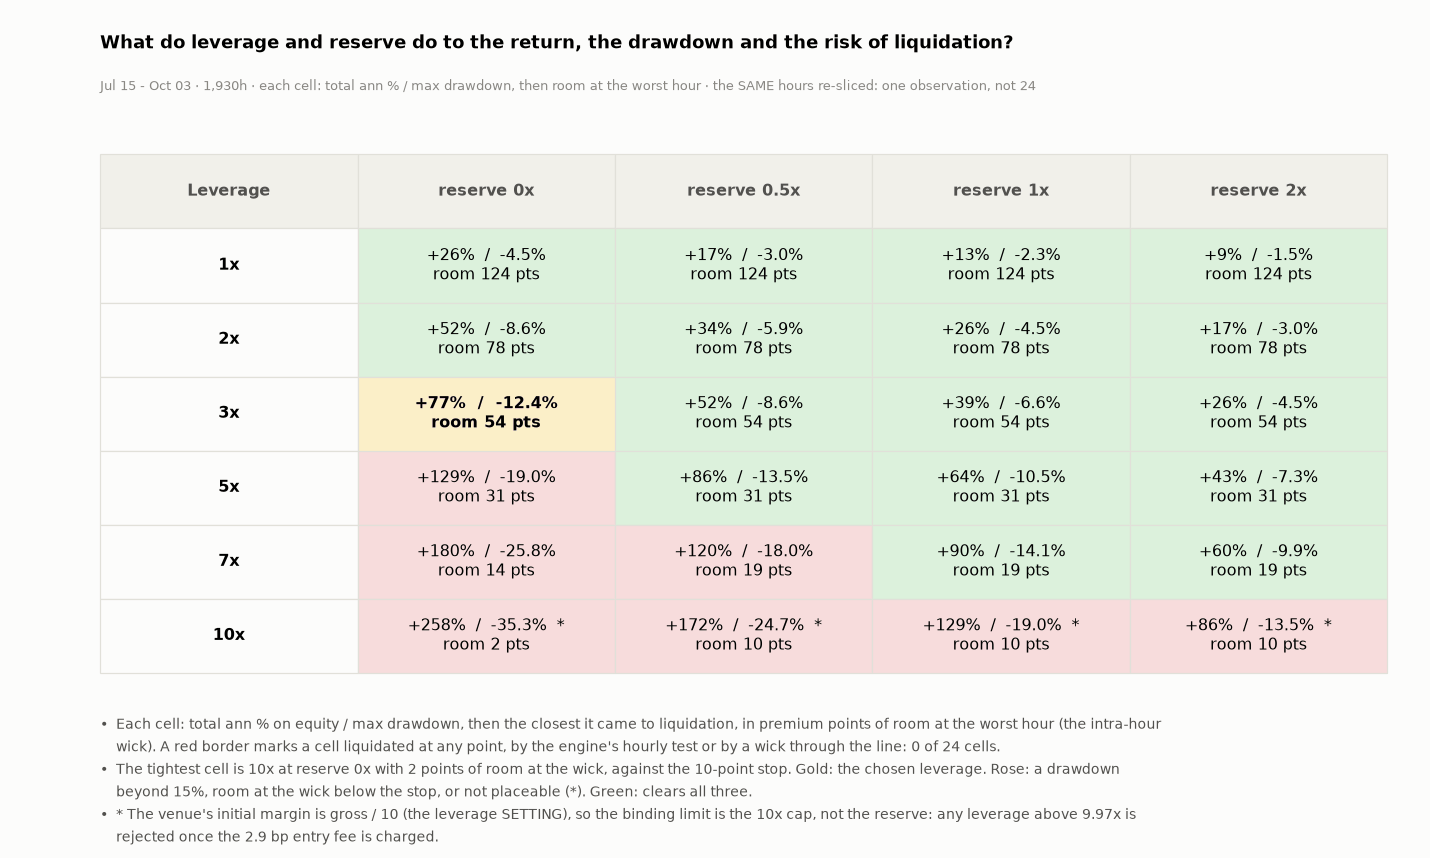

In [39]:
# ---- the grid
# ---- liquidation, cell by cell: a liquidation, or a wick that reaches the line, makes a cell LIQUIDATED (red border); the second line is the closest approach ----
WR = {k_: wick_room(r_)[0] for k_, r_ in GR.items()}
LIQC = {k_: bool(r_["liquidations"]) or WR[k_] <= 0 for k_, r_ in GR.items()}
tight = min(WR, key=WR.get)
fig = plt.figure(figsize=(13, 7.8))
bm = figstyle.bullets(fig, [f"Each cell: total ann % on equity / max drawdown, then the closest it came to liquidation, in premium points of room at the worst hour (the intra-hour wick). A red border marks a cell liquidated at any point, by the engine's hourly test or by a wick through the line: {sum(LIQC.values())} of {len(GR)} cells.",
                            f"The tightest cell is {tight[0]}x at reserve {tight[1]:g}x with {WR[tight]:.0f} points of room at the wick, against the {STOP_PTS:.0f}-point stop. Gold: the chosen leverage. Rose: a drawdown beyond {DD_LIMIT_PCT:.0f}%, room at the wick below the stop, or not placeable (*). Green: clears all three.",
                            f"* The venue's initial margin is gross / {MAXLEV} (the leverage SETTING), so the binding limit is the {MAXLEV}x cap, not the reserve: any leverage above {L_MAX_PLACEABLE:.2f}x is rejected once the {ENTRY_BPS:.1f} bp entry fee is charged."])
gs = fig.add_gridspec(1, 1, left=0.07, right=0.97, top=0.82, bottom=bm + 0.03); axt = fig.add_subplot(gs[0]); axt.axis("off")
cells = [[f"{L}x"] + [f"{GR[(L, R)]['ann_pct']:+.0f}%  /  {GR[(L, R)]['max_drawdown']*100:.1f}%" + ("" if PLACEABLE[(L, R)] else "  *") + chr(10) + ("LIQUIDATED" if LIQC[(L, R)] else f"room {WR[(L, R)]:.0f} pts") for R in RESV] for L in LEVS]
tb = axt.table(cellText=cells, colLabels=["Leverage"] + [f"reserve {R:g}x" for R in RESV], cellLoc="center", loc="center", bbox=[0, 0, 1, 1]); tb.set_fontsize(10.5); figstyle.style_table(tb)
for i_, L in enumerate(LEVS, 1):
    tb[(i_, 0)].set_text_props(weight="bold")
    for j_, R in enumerate(RESV, 1):
        bad = (GR[(L, R)]["max_drawdown"] * 100 <= -DD_LIMIT_PCT) or (not PLACEABLE[(L, R)]) or WR[(L, R)] < STOP_PTS
        tint(tb, i_, j_, "rose") if bad else tint(tb, i_, j_, "green")
        if L == L_PICK and R == 0.0:
            gold(tb, i_, j_)
        if LIQC[(L, R)]:
            tb[(i_, j_)].set_edgecolor(CRIT); tb[(i_, j_)].set_linewidth(3.2); tb[(i_, j_)].set_zorder(6); tb[(i_, j_)].set_text_props(color=CRIT, weight="bold")
fig.suptitle("What do leverage and reserve do to the return, the drawdown and the risk of liquidation?", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.96)
fig.text(0.07, 0.895, f"{WSH} \u00b7 each cell: total ann % / max drawdown, then room at the worst hour \u00b7 the SAME hours re-sliced: one observation, not {len(GR)}", color=MUTED, fontsize=8.5)
figstyle.show(fig, "fig:s6-grid", []); assert any(f["id"] == "fig:s6-grid" for f in FIGURES)
STATS["grid"] = {"n": len(GR), "nliq": NLIQ, "liquidated_cells": int(sum(LIQC.values())), "tightest": {"lev": tight[0], "reserve": tight[1], "room_pts": float(WR[tight])}}

## Research summary

The card the Research room will show, as a separate part at the bottom: the question, the answer, the numbers that matter.

In [40]:
# ---- the research summary: the card was built in S7 and rides in the manifest's summary; this is the same card, drawn ----
display(HTML(summary_card.render(CARD)))

Size,Return,Max DD,Liq buffer,Verdict
1x,+25.8%,-4.5%,123.7 pts,PASS
3x,+77.3%,-12.4%,54.4 pts,PASS
5x,+128.8%,-19.0%,31.0 pts,FAIL
10x,+257.6%,-35.3%,1.6 pts,FAIL
